# Аналіз зовнішньої торгівлі України товарами у 2015-2024 роках

## 01. Мета дослідження та джерело даних

### Мета дослідження
Дослідити динаміку експорту та імпорту товарів України, зміни товарної структури імпорту, індексів середніх цін і фізичного обсягу, а також географії імпорту у 2015-2024 роках.

### Дослідницьке питання
Як змінилися обсяги та структура зовнішньої торгівлі товарами України у 2015-2024 роках, зокрема після 2022 року, і які зміни відбулися в товарній структурі та географії імпорту?

### Напрямки дослідження
1. Загальна динаміка експорту, імпорту та торговельного балансу.
2. Товарна структура імпорту.
3. Індекси середніх цін і фізичного обсягу експорту та імпорту.
4. Географія імпорту за країнами-партнерами.
5. Динаміка окремих товарних груп.

### Джерело даних
[Державна служба статистики України — зовнішня торгівля товарами.](https://stat.gov.ua/uk/explorer?urn=SSSU%3ADF_EXTERNAL_TRADE_OF_GOODS%28~%29)

**Період дослідження:** 2015-2024 роки.

## 02. Завантаження та первинне дослідження даних

### 2.1. Підготовка середовища

In [110]:
# Імпорт бібліотек
import pandas as pd
import numpy as np
import requests

### 2.2. Завантаження та читання файлу CSV

In [111]:
# Посилання на файл Google Drive
file_url = 'https://drive.google.com/file/d/1UolcYzsMufhKMJKsc_DfLEgUWHI0t_qY/view?usp=sharing'

# Отримання ID файлу з посилання
import re

match = re.search(r'/d/([a-zA-Z0-9_-]+)', file_url)

if not match:
    raise ValueError('Не вдалося визначити ID файлу. Перевір посилання.')

file_id = match.group(1)

# Формування прямого посилання для завантаження
download_url = f'https://drive.google.com/uc?export=download&id={file_id}'

print('ID файлу визначено успішно')

# Завантаження файлу
response = requests.get(download_url)

if response.status_code != 200:
    raise Exception('Не вдалося завантажити файл. Перевір доступ за посиланням.')

# Перевірка, чи отримано CSV, а не сторінку Google Drive
if 'text/html' in response.headers.get('Content-Type', ''):
    raise Exception(
        'Google Drive повернув HTML-сторінку замість CSV. '
        'Перевір налаштування доступу до файлу.'
    )

# Читання даних
from io import BytesIO

df = pd.read_csv(
    BytesIO(response.content),
    encoding='utf-8-sig',
    low_memory=False
)

print('Дані успішно завантажено')

ID файлу визначено успішно
Дані успішно завантажено


### 2.3. Первинна перевірка

In [112]:
print('Розмір набору даних:', df.shape)

Розмір набору даних: (27177, 401)


In [113]:
# Визначення періоду дослідження
analysis_years = [str(year) for year in range(2015, 2025)]

print(analysis_years)

['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']


### 2.4. Цільова вибірка та повнота імпорту й експорту

### Мета

Оцінити заповненість річних даних імпорту та експорту товарів за 2015-2024 роки, порівняти кількість доступних значень за кожним показником і визначити, чи достатньо даних для аналізу загальної динаміки зовнішньої торгівлі.

In [114]:
# Відбираємо річні дані про товари за країнами
trade_data = df[
    (df['Категорія розрізу'] == 'Товари за країнами') &
    (df['Періодичність'] == 'Річна') &
    (df['Показник'].isin(['Імпорт товарів', 'Експорт товарів']))
].copy()

# Розраховуємо заповненість окремо для імпорту та експорту
completeness_by_indicator = []

for indicator in ['Імпорт товарів', 'Експорт товарів']:
    indicator_data = trade_data[
        trade_data['Показник'] == indicator
    ]

    for year in analysis_years:
        filled = indicator_data[year].notna().sum()
        missing = indicator_data[year].isna().sum()
        total = len(indicator_data)

        completeness_by_indicator.append({
            'Показник': indicator,
            'Рік': year,
            'Кількість записів': total,
            'Заповнено': filled,
            'Пропущено': missing,
            'Заповненість, %': round(filled / total * 100, 2)
        })

completeness_by_indicator = pd.DataFrame(
    completeness_by_indicator
)

display(completeness_by_indicator)

,Показник,Рік,Кількість записів,Заповнено,Пропущено,"Заповненість, %"
0,Імпорт товарів,2015,11867,5963,5904,50.25
1,Імпорт товарів,2016,11867,6210,5657,52.33
2,Імпорт товарів,2017,11867,6322,5545,53.27
3,Імпорт товарів,2018,11867,6524,5343,54.98
4,Імпорт товарів,2019,11867,9752,2115,82.18
5,Імпорт товарів,2020,11867,6953,4914,58.59
6,Імпорт товарів,2021,11867,7152,4715,60.27
7,Імпорт товарів,2022,11867,6503,5364,54.80
8,Імпорт товарів,2023,11867,6446,5421,54.32
9,Імпорт товарів,2024,11867,6333,5534,53.37


In [115]:
# Перевіряємо записи із загальним підсумком
total_trade = trade_data[
    (trade_data['Товар'] == 'Усього') &
    (trade_data['Країна контрагент'] == 'Усього')
].copy()

# Виводимо основні характеристики знайдених записів
display(
    total_trade[
        [
            'Показник',
            'Угруповання товарів',
            'Товар',
            'Країна контрагент',
            'Одиниця виміру'
        ] + analysis_years
    ]
)

,Показник,Угруповання товарів,Товар,Країна контрагент,Одиниця виміру,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
11751,Експорт товарів,Усього,Усього,Усього,Долар США,38127149.7,36361711.2,43264736.0,47334987.0,50054605.8,49191824.5,68072328.8,44135592.5,37584289.0,41733285.6
23523,Імпорт товарів,Усього,Усього,Усього,Долар США,37516443.0,39249797.2,49607173.9,57187578.0,60800173.1,54336136.7,72843126.6,55295748.4,63763482.6,70770582.4


In [116]:
# Формуємо таблицю загальних обсягів імпорту та експорту
total_trade_table = total_trade.set_index('Показник')[analysis_years].T

total_trade_table = total_trade_table.rename(columns={
    'Імпорт товарів': 'Імпорт, тис. дол. США',
    'Експорт товарів': 'Експорт, тис. дол. США'
})

total_trade_table.index.name = 'Рік'
total_trade_table = total_trade_table.reset_index()

# Переводимо значення у числовий формат
for col in ['Імпорт, тис. дол. США', 'Експорт, тис. дол. США']:
    total_trade_table[col] = pd.to_numeric(total_trade_table[col])

# Додаємо значення у мільярдах доларів
total_trade_table['Імпорт, млрд дол. США'] = (
    total_trade_table['Імпорт, тис. дол. США'] / 1_000_000
).round(5)

total_trade_table['Експорт, млрд дол. США'] = (
    total_trade_table['Експорт, тис. дол. США'] / 1_000_000
).round(5)


total_trade_table = total_trade_table[
    [
        'Рік',
        'Експорт, тис. дол. США',
        'Імпорт, тис. дол. США',
        'Експорт, млрд дол. США',
        'Імпорт, млрд дол. США'
    ]
]

###2.5. Висновок за результатами перевірки повноти даних імпорту та експорту

Перевірка річних даних категорії «Товари за країнами» показала, що заповненість записів імпорту та експорту відрізняється за роками.

Для імпорту рівень заповненості становив від 50,25% до 82,18%, для експорту — від 56,28% до 70,30%. Найвища заповненість імпорту спостерігалася у 2019 році, експорту - у 2021 році. У 2022-2024 роках для обох показників зафіксовано нижчу заповненість порівняно з 2021 роком.

Водночас перевірка загальних підсумкових записів «Усього» підтвердила наявність числових значень імпорту та експорту за всі роки дослідження — з 2015 до 2024 року. Кожен із двох показників містить 10 заповнених річних значень.

Таким чином, дані придатні для аналізу загальної динаміки імпорту та експорту товарів України за 2015-2024 роки. Для деталізованого аналізу товарної структури та географії торгівлі необхідно враховувати пропуски в окремих записах і не трактувати їх автоматично як нульові значення.

Під час перевірки метаданих встановлено, що показники експорту та імпорту товарів мають одиницю виміру «Долар США» та масштабування «Тисячі». Тому вихідні значення інтерпретуються як тисячі доларів США. Для подальшого аналізу сформовано додаткові показники в мільярдах доларів США шляхом ділення вихідних значень на 1 000 000. Початкові значення збережено без змін.

## 03. Контроль якості цільової вибірки

### 3.1. Перевірка унікальності та ключових полів

In [117]:
# Перевірка дублікатів за ключовими полями
key_columns = [
    'Показник',
    'Угруповання товарів',
    'Товар',
    'Країна контрагент',
    'Одиниця виміру',
    'Масштабування'
]

key_duplicates = trade_data[
    trade_data.duplicated(subset=key_columns, keep=False)
].copy()

print('Кількість рядків, що мають дублікати за ключовими полями:',
      len(key_duplicates))

print('Кількість повторюваних комбінацій:',
      key_duplicates.duplicated(subset=key_columns).sum())

Кількість рядків, що мають дублікати за ключовими полями: 0
Кількість повторюваних комбінацій: 0


### 3.2. Перевірка обов'язкових полів та форматів

In [118]:
# Перевірка пропусків у ключових полях
required_columns = [
    'Показник',
    'Періодичність',
    'Категорія розрізу',
    'Угруповання товарів',
    'Товар',
    'Країна контрагент',
    'Одиниця виміру',
    'Масштабування'
]

missing_required = trade_data[required_columns].isna().sum()

print('Кількість пропусків у ключових полях:')
display(missing_required)

print('Загальна кількість пропусків у ключових полях:',
      missing_required.sum())

Кількість пропусків у ключових полях:


,0
Показник,0
Періодичність,0
Категорія розрізу,0
Угруповання товарів,0
Товар,0
Країна контрагент,0
Одиниця виміру,0
Масштабування,0


Загальна кількість пропусків у ключових полях: 0


In [119]:
# Перевірка одиниць виміру та масштабування
print('Одиниці виміру:')
display(trade_data['Одиниця виміру'].value_counts(dropna=False))

print('\nМасштабування:')
display(trade_data['Масштабування'].value_counts(dropna=False))

print('\nКількість десяткових знаків:')
display(trade_data['Кількість десяткових знаків'].value_counts(dropna=False))

Одиниці виміру:


,count
Одиниця виміру,
Долар США,23708



Масштабування:


,count
Масштабування,
Тисячі,23708



Кількість десяткових знаків:


,count
Кількість десяткових знаків,
Один,23708


In [120]:
# Перевірка наявності річних колонок
year_columns = [str(year) for year in range(2015, 2025)]

missing_years = [year for year in year_columns if year not in trade_data.columns]

print('Роки дослідження:', year_columns)
print('Відсутні річні колонки:', missing_years)

# Кількість заповнених значень за кожним роком
print('\nКількість заповнених значень за роками:')
display(trade_data[year_columns].notna().sum())

Роки дослідження: ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']
Відсутні річні колонки: []

Кількість заповнених значень за роками:


,0
2015,12641
2016,13352
2017,13508
2018,14039
2019,17608
2020,14901
2021,15476
2022,13450
2023,13170
2024,12997


In [121]:
# Перевірка типів даних у річних колонках
print('Типи даних:')
display(trade_data[year_columns].dtypes)

# Перевірка числових значень
numeric_check = trade_data[year_columns].apply(
    lambda col: pd.to_numeric(col, errors='coerce')
)

print('\nКількість значень, які не вдалося перетворити на числа:')
display(
    (trade_data[year_columns].notna() & numeric_check.isna()).sum()
)

Типи даних:


,0
2015,float64
2016,float64
2017,float64
2018,float64
2019,float64
2020,float64
2021,float64
2022,float64
2023,float64
2024,float64



Кількість значень, які не вдалося перетворити на числа:


,0
2015,0
2016,0
2017,0
2018,0
2019,0
2020,0
2021,0
2022,0
2023,0
2024,0


### 3.3. Результати перевірки якості даних

У межах робочої вибірки `trade_data` проведено перевірку дублікатів, пропусків у ключових полях, одиниць виміру, наявності часових колонок та типів даних.

Результати перевірки:
- Повні дублікати відсутні.
- Повторення за ключовими полями не виявлені.
- Пропуски у ключових полях відсутні.
- Усі записи мають одиницю виміру «Долар США» та масштабування «Тисячі».
- Наявні всі річні колонки за 2015-2024 роки.
- Усі річні значення мають числовий тип `float64`.

**Висновок:** робоча вибірка придатна для подальшого аналізу. Пропущені значення в річних показниках не замінюються нулями, оскільки відсутність значення не означає відсутність торгівлі.

## 04. Формування робочих таблиць для аналізу

Після перевірки якості вихідних даних переходимо до формування окремих робочих таблиць для п'яти напрямків дослідження.

Для кожного напрямку буде сформовано відповідну вибірку з урахуванням показників, товарних категорій, періоду та рівня деталізації.

Робочі таблиці використовуватимуться як основа для подальших розрахунків, візуалізацій та аналітичних висновків.

План формування робочих таблиць:

1. Загальна динаміка імпорту та експорту товарів України.
2. Товарна структура імпорту.
3. Індекси середніх цін і фізичного обсягу.
4. Географічна структура імпорту.
5. Аналіз окремих товарних груп.

Усі грошові показники будуть супроводжуватися зазначенням одиниць виміру та масштабування. Пропущені значення не прирівнюватимуться до нуля без підтверджених підстав.

### 4.1. Робоча таблиця загальної динаміки імпорту та експорту

Для аналізу загальної динаміки зовнішньої торгівлі сформовано таблицю річних обсягів імпорту та експорту товарів України за 2015–2024 роки.

Таблиця містить національні підсумкові значення імпорту й експорту, представлені в тисячах та мільярдах доларів США.

**Назва робочого набору даних:** `total_trade_table`.

Таблиця пройшла перевірку структури, типів даних і повноти значень та буде використана в першому напрямку аналітичного дослідження.

In [122]:
display(total_trade_table)

Показник,Рік,"Експорт, тис. дол. США","Імпорт, тис. дол. США","Експорт, млрд дол. США","Імпорт, млрд дол. США"
0,2015,38127149.7,37516443.0,38.12715,37.51644
1,2016,36361711.2,39249797.2,36.36171,39.24980
2,2017,43264736.0,49607173.9,43.26474,49.60717
3,2018,47334987.0,57187578.0,47.33499,57.18758
4,2019,50054605.8,60800173.1,50.05461,60.80017
5,2020,49191824.5,54336136.7,49.19182,54.33614
6,2021,68072328.8,72843126.6,68.07233,72.84313
7,2022,44135592.5,55295748.4,44.13559,55.29575
8,2023,37584289.0,63763482.6,37.58429,63.76348
9,2024,41733285.6,70770582.4,41.73329,70.77058


### 4.2. Робоча таблиця товарної структури імпорту

Для дослідження товарної структури імпорту сформовано вибірку річних даних за товарними групами за 2015–2024 роки. Використовуються національні підсумкові значення імпорту без деталізації за країнами. Одиниця виміру — тисячі доларів США.

In [123]:
# Відбір річних даних імпорту за товарними групами
import_groups = trade_data[
    (trade_data['Показник'] == 'Імпорт товарів') &
    (trade_data['Угруповання товарів'] == 'Групи') &
    (trade_data['Країна контрагент'] == 'Усього')
].copy()

print('Розмір вибірки:', import_groups.shape)

print('\nКількість записів за роками:')
display(import_groups[analysis_years].notna().sum())

print('\nПерші 10 записів:')
display(
    import_groups[
        ['Товар'] + analysis_years
    ].head(10)
)

Розмір вибірки: (98, 401)

Кількість записів за роками:


,0
2015,96
2016,96
2017,96
2018,96
2019,97
2020,97
2021,97
2022,98
2023,98
2024,97



Перші 10 записів:


,Товар,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
11875,Група 01 Живі тварини,59701.1,57981.0,57432.5,71823.6,76639.9,80912.1,91337.5,62577.5,80568.1,86720.6
12020,Група 02 М'ясо та їстівні субпродукти,99338.4,80773.4,112024.7,167663.2,158603.9,165030.6,214508.2,209944.3,142069.6,103490.5
12122,"Група 03 Риба і ракоподібні, молюски та інші в...",291101.6,409947.9,455444.5,549534.7,644617.7,680552.5,875120.4,627489.9,804619.4,929694.5
12203,Група 04 Молоко та молочні продукти; яйця птиц...,79777.4,59489.5,84884.5,106458.0,169492.1,308396.9,384535.4,248225.9,290247.9,323883.3
12211,"Група 05 Інші продукти тваринного походження, ...",18251.7,18087.3,21763.4,22509.3,22119.2,23177.2,28506.1,26979.5,26293.8,31727.0
12302,Група 06 Живі дерева та інші рослини; цибулини...,19289.5,22437.7,27164.9,33977.0,40905.9,48843.1,73759.9,48582.4,44018.9,55410.1
12455,Група 07 Овочі та деякі їстівні коренеплоди і ...,62806.6,81654.7,75995.2,106191.3,212383.8,262576.7,250447.6,352510.7,373776.7,340508.0
12712,Група 08 Їстівні плоди та горіхи; шкірки цитру...,467066.2,476179.7,477254.8,526707.0,673160.7,795560.2,835704.3,662800.5,813504.4,866731.4
12861,"Група 09 Кава, чай, мате або парагвайський чай...",185770.9,187759.9,194133.8,209046.6,222433.8,251294.7,266675.2,274970.1,294327.1,360037.0
12938,Група 10 Зернові культури,154707.7,148799.7,176756.1,191116.7,180817.4,178913.7,166099.0,153676.8,119178.5,111242.0


In [124]:
# Формування таблиці товарної структури імпорту
import_groups_table = import_groups[
    ['Товар'] + analysis_years
].copy()

# Перейменування колонки з товарними групами
import_groups_table = import_groups_table.rename(
    columns={'Товар': 'Товарна група'}
)

# Перетворення річних значень на числовий формат
for year in analysis_years:
    import_groups_table[year] = pd.to_numeric(
        import_groups_table[year],
        errors='coerce'
    )

# Сортування за кодом товарної групи
import_groups_table = import_groups_table.sort_values(
    'Товарна група'
).reset_index(drop=True)

display(import_groups_table)

,Товарна група,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Група 01 Живі тварини,59701.1,57981.0,57432.5,71823.6,76639.9,80912.1,91337.5,62577.5,80568.1,86720.6
1,Група 02 М'ясо та їстівні субпродукти,99338.4,80773.4,112024.7,167663.2,158603.9,165030.6,214508.2,209944.3,142069.6,103490.5
2,"Група 03 Риба і ракоподібні, молюски та інші в...",291101.6,409947.9,455444.5,549534.7,644617.7,680552.5,875120.4,627489.9,804619.4,929694.5
3,Група 04 Молоко та молочні продукти; яйця птиц...,79777.4,59489.5,84884.5,106458.0,169492.1,308396.9,384535.4,248225.9,290247.9,323883.3
4,"Група 05 Інші продукти тваринного походження, ...",18251.7,18087.3,21763.4,22509.3,22119.2,23177.2,28506.1,26979.5,26293.8,31727.0
...,...,...,...,...,...,...,...,...,...,...,...
93,"Група 95 іграшки, ігри та спортивний інвентар;...",134403.5,192332.8,215536.8,262006.7,328211.0,332136.5,403265.6,158577.3,275216.1,319211.4
94,Група 96 Різні готові вироби,215498.6,220764.9,247379.4,282301.3,302823.6,502527.8,356876.5,240435.9,300329.1,306936.3
95,"Група 97 Твори мистецтва, предмети колекціонув...",637.7,1304.7,757.9,2066.4,1954.3,3997.7,6586.6,478.3,16339.4,96751.3
96,"Група 98 Товари, придбані в портах",182924.3,165052.6,200047.5,432796.2,381222.5,90809.5,126215.9,69228.5,44041.2,44807.8


In [125]:
# Сума значень за товарними групами за кожен рік
group_sum_by_year = import_groups_table[analysis_years].sum()

# Загальний імпорт із національної підсумкової таблиці
total_import_by_year = (
    total_trade_table
    .set_index('Рік')['Імпорт, тис. дол. США']
)

# Формуємо таблицю порівняння
import_coverage_table = pd.DataFrame({
    'Рік': analysis_years,
    'Сума товарних груп, тис. дол. США': group_sum_by_year.values,
    'Загальний імпорт, тис. дол. США': total_import_by_year.loc[analysis_years].values
})

import_coverage_table['Різниця, тис. дол. США'] = (
    import_coverage_table['Загальний імпорт, тис. дол. США'] -
    import_coverage_table['Сума товарних груп, тис. дол. США']
)

import_coverage_table['Покриття, %'] = (
    import_coverage_table['Сума товарних груп, тис. дол. США'] /
    import_coverage_table['Загальний імпорт, тис. дол. США'] * 100
).round(2)

display(import_coverage_table)

,Рік,"Сума товарних груп, тис. дол. США","Загальний імпорт, тис. дол. США","Різниця, тис. дол. США","Покриття, %"
0,2015,37448764.7,37516443.0,67678.3,99.82
1,2016,39209789.2,39249797.2,40008.0,99.90
2,2017,49567193.2,49607173.9,39980.7,99.92
3,2018,57081155.3,57187578.0,106422.7,99.81
4,2019,60800173.2,60800173.1,-0.1,100.00
5,2020,54336136.6,54336136.7,0.1,100.00
6,2021,72843126.4,72843126.6,0.2,100.00
7,2022,55295749.0,55295748.4,-0.6,100.00
8,2023,63674365.5,63763482.6,89117.1,99.86
9,2024,64849026.7,70770582.4,5921555.7,91.63


**Перевірка одиниць вимірювання та типів даних**

Перед подальшим аналізом перевірено відповідність одиниць вимірювання загального імпорту та імпорту за товарними групами.

Для обох вибірок встановлено однакові параметри:
- одиниця виміру - долар США;
- масштабування - тисячі;
- кількість десяткових знаків - один.

Річні показники мають числовий тип `float64`. Отже, відмінності в одиницях вимірювання або типах даних не пояснюють розбіжності між сумою товарних груп і загальним імпортом.

**Перевірка повноти товарної структури**

Суму значень за товарними групами порівняно із загальним обсягом імпорту за кожен рік.

Результати показали, що:
- у 2015-2018 роках покриття загального імпорту сумою товарних груп становить 99,81-99,92%;
- у 2019-2022 роках значення практично збігаються;
- у 2023 році покриття становить 99,86%;
- у 2024 році покриття знижується до 91,63%.

Найбільша розбіжність спостерігається у 2024 році та становить 5 921 555,7 тис. дол. США. Вона пов'язана з відсутнім значенням товарної групи 99 «Різне» у підсумкових даних за цей рік.

Таким чином, одиниці вимірювання обох вибірок узгоджені, однак повнота підсумків за товарними групами відрізняється залежно від року. Виявлені розбіжності потребують окремої перевірки перед розрахунком часток товарних груп.

In [126]:
group_99_by_country = trade_data[
    (trade_data['Показник'] == 'Імпорт товарів') &
    (trade_data['Товар'].str.contains('Група 99', na=False))
].copy()

display(
    group_99_by_country[
        ['Товар', 'Країна контрагент'] + analysis_years
    ]
)

,Товар,Країна контрагент,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
23168,Група 99 Різне,Іспанія,1105.5,1458.0,1882.9,2252.4,3735.4,2658.9,2802.4,4550.4,119707.3,32763.2
23169,Група 99 Різне,Боснія і Герцеговина,NaN,NaN,NaN,NaN,900.0,NaN,NaN,2377.0,5324.6,11811.2
23170,Група 99 Різне,Індія,145.7,NaN,15.9,246.1,189.0,59.0,229.0,NaN,116337.7,339261.5
23171,Група 99 Різне,Беліз,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
23173,Група 99 Різне,"Тайвань, Провінція Китаю",146.8,427.7,68.7,715.4,539.0,840.6,729.4,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
23285,Група 99 Різне,Данія,15.8,11.8,101.3,46.1,103.4,186.4,98.6,476.1,270.1,430.5
23287,Група 99 Різне,Болгарія,23058.2,389.9,NaN,18376.8,41349.1,9141.0,17458.0,926265.8,1287369.0,1791735.2
23289,Група 99 Різне,Франція,63.2,13.4,86.9,424.2,168.5,61.8,226.7,12050.3,162029.9,34019.2
23292,Група 99 Різне,Ліван,NaN,89.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [127]:
# Порівняння розрахункової суми групи 99 за країнами
# з офіційним залишком загального імпорту за 2024 рік

# 1. Сума значень групи 99 за окремими країнами
# Агреговані рядки "Усього" та "Країни ЄС" виключаємо,
# щоб уникнути подвійного підрахунку.

group_99_country_sum_2024 = (
    trade_data.loc[
        (trade_data['Показник'] == 'Імпорт товарів') &
        (trade_data['Періодичність'] == 'Річна') &
        (trade_data['Категорія розрізу'] == 'Товари за країнами') &
        (trade_data['Угруповання товарів'] == 'Групи') &
        (trade_data['Товар'].str.contains('Група 99', na=False)) &
        (~trade_data['Країна контрагент'].isin(['Усього', 'Країни ЄС'])),
        '2024'
    ].sum(min_count=1)
)

# 2. Офіційний залишок:
# загальний імпорт мінус сума наявних офіційних агрегованих груп

total_import_2024_thousand = total_trade_table.loc[
    total_trade_table['Рік'] == '2024',
    'Імпорт, тис. дол. США'
].iloc[0]

official_groups_sum_2024 = import_groups_table['2024'].sum(
    min_count=1
)

official_residual_2024 = (
    total_import_2024_thousand - official_groups_sum_2024
)

# 3. Порівняння значень

group_99_comparison = pd.DataFrame({
    'Показник': [
        'Сума групи 99 за країнами (розрахункова)',
        'Офіційний залишок загального імпорту',
        'Різниця між значеннями'
    ],
    'Значення, тис. дол. США': [
        group_99_country_sum_2024,
        official_residual_2024,
        group_99_country_sum_2024 - official_residual_2024
    ]
})

display(group_99_comparison.round(1))


,Показник,"Значення, тис. дол. США"
0,Сума групи 99 за країнами (розрахункова),5921555.5
1,Офіційний залишок загального імпорту,5921555.7
2,Різниця між значеннями,-0.2


**Примітка щодо товарної групи 99 «Різне»**

У 2024 році офіційне агреговане значення імпорту товарної групи 99 «Різне» відсутнє. Сума доступних значень за країнами становить 5 921 555,5 тис. дол. США, тоді як різниця між загальним імпортом і сумою наявних офіційних агрегованих товарних груп становить 5 921 555,7 тис. дол. США.

Розрахункова сума за країнами наведена лише для зіставлення з офіційним залишком. Вона не замінює відсутнє офіційне агреговане значення та не використовується в основному аналізі.

У подальших розрахунках застосовуються лише наявні офіційні агреговані значення. Покриття товарної структури імпорту за 2024 рік становить 91,63%. Відсутні значення не прирівнюються до нуля.

### 4.2.1 Формування робочої таблиці часток товарних груп у загальному імпорті

Для цього створимо таблицю, у якій кожна товарна група матиме частку в загальному імпорті за кожен рік з 2015 до 2024.

Формула розрахунку:

Частка, % = (Імпорт товарної групи / Загальний імпорт) * 100


In [128]:
# Створюємо копію таблиці імпорту за товарними групами
import_share_table = import_groups_table.copy()

# Перетворюємо значення імпорту в частки від загального імпорту
for year in analysis_years:
    total_import = total_trade_table.loc[
        total_trade_table['Рік'] == year,
        'Імпорт, тис. дол. США'
    ].iloc[0]

    import_share_table[year] = (
        import_share_table[year] / total_import * 100
    )
# Перейменовуємо стовпці
import_share_table = import_share_table.rename(
    columns={
        year: f'{year}, %'
        for year in analysis_years
    }
)

# Перевіряємо результат
display(import_share_table.head(10))

,Товарна група,"2015, %","2016, %","2017, %","2018, %","2019, %","2020, %","2021, %","2022, %","2023, %","2024, %"
0,Група 01 Живі тварини,0.159133,0.147723,0.115775,0.125593,0.126052,0.148910,0.125389,0.113169,0.126355,0.122538
1,Група 02 М'ясо та їстівні субпродукти,0.264786,0.205793,0.225824,0.293181,0.260861,0.303722,0.294480,0.379675,0.222807,0.146234
2,"Група 03 Риба і ракоподібні, молюски та інші в...",0.775931,1.044459,0.918102,0.960934,1.060223,1.252486,1.201377,1.134789,1.261881,1.313674
3,Група 04 Молоко та молочні продукти; яйця птиц...,0.212646,0.151566,0.171113,0.186156,0.278769,0.567572,0.527895,0.448906,0.455195,0.457652
4,"Група 05 Інші продукти тваринного походження, ...",0.048650,0.046083,0.043871,0.039360,0.036380,0.042655,0.039134,0.048791,0.041236,0.044831
5,Група 06 Живі дерева та інші рослини; цибулини...,0.051416,0.057166,0.054760,0.059413,0.067279,0.089891,0.101259,0.087859,0.069035,0.078295
6,Група 07 Овочі та деякі їстівні коренеплоди і ...,0.167411,0.208039,0.153194,0.185689,0.349314,0.483245,0.343818,0.637501,0.586192,0.481143
7,Група 08 Їстівні плоди та горіхи; шкірки цитру...,1.244964,1.213203,0.962068,0.921016,1.107169,1.464146,1.147266,1.198646,1.275816,1.224706
8,"Група 09 Кава, чай, мате або парагвайський чай...",0.495172,0.478372,0.391342,0.365545,0.365844,0.462482,0.366095,0.497272,0.461592,0.508738
9,Група 10 Зернові культури,0.412373,0.379109,0.356312,0.334193,0.297396,0.329272,0.228023,0.277918,0.186907,0.157187


**Результат перевірки робочої таблиці часток**

Частки товарних груп розраховано відносно загального обсягу імпорту України за кожен рік у 2015-2024 роках.

Контрольна перевірка показала, що сума часток становить від 99,81% до 100% у 2015-2023 роках, за винятком виявлених розбіжностей у вихідних даних. У 2024 році сума часток становить 91,63% через відсутність офіційного національного підсумку товарної групи 99 «Різне».

Пропущені значення не замінювалися нулями. Розрахунки виконано на основі наявних офіційних даних без штучного коригування структури.

Отримана таблиця використовується для подальшого дослідження змін товарної структури імпорту.

##4.3. Індекси середніх цін і фізичного обсягу

In [129]:
# Відбираємо показники, у назві яких згадується індекс
indices_data = df[
    df['Показник'].str.contains(
        'індекс',
        case=False,
        na=False
    )
].copy()

# Основні показники для третього напрямку
main_indices = [
    'Індекси середніх цін в імпорті товарів',
    'Індекси фізичного обсягу в імпорті товарів',
    'Індекси середніх цін в експорті товарів',
    'Індекси фізичного обсягу в експорті товарів'
]

# Відбираємо тільки річні дані
annual_indices = indices_data[
    (indices_data['Показник'].isin(main_indices)) &
    (indices_data['Періодичність'] == 'Річна')
].copy()

# Перевіряємо кількість записів за показниками та угрупованнями
annual_indices_summary = (
    annual_indices
    .groupby(['Показник', 'Угруповання товарів'])
    .size()
    .reset_index(name='Кількість записів')
)

display(annual_indices_summary)

,Показник,Угруповання товарів,Кількість записів
0,Індекси середніх цін в експорті товарів,Групи,96
1,Індекси середніх цін в експорті товарів,Усього,1
2,Індекси середніх цін в імпорті товарів,Групи,96
3,Індекси середніх цін в імпорті товарів,Усього,1
4,Індекси фізичного обсягу в експорті товарів,Групи,96
5,Індекси фізичного обсягу в експорті товарів,Усього,1
6,Індекси фізичного обсягу в імпорті товарів,Групи,96
7,Індекси фізичного обсягу в імпорті товарів,Усього,1


#### 4.3.1 Формування робочої таблиці індексів середніх цін і фізичного обсягу

In [130]:
# Відбираємо національні підсумкові значення
indices_total = annual_indices[
    annual_indices['Угруповання товарів'] == 'Усього'
].copy()

# Транспонуємо дані: роки стають рядками
trade_indices_table = (
    indices_total
    .set_index('Показник')[analysis_years]
    .T
    .reset_index()
    .rename(columns={'index': 'Рік'})
)

# Перевіряємо типи даних
for col in main_indices:
    trade_indices_table[col] = pd.to_numeric(
        trade_indices_table[col],
        errors='coerce'
    )

display(trade_indices_table)

Показник,Рік,Індекси середніх цін в експорті товарів,Індекси фізичного обсягу в експорті товарів,Індекси середніх цін в імпорті товарів,Індекси фізичного обсягу в імпорті товарів
0,2015,82.3,86.0,89.8,76.7
1,2016,96.2,99.1,96.4,108.6
2,2017,115.9,102.7,114.0,110.9
3,2018,111.8,97.9,112.3,102.6
4,2019,100.1,105.7,100.2,106.1
5,2020,104.6,94.0,99.6,89.4
6,2021,148.2,93.4,124.6,107.6
7,2022,108.2,59.9,137.3,55.3
8,2023,86.1,95.2,107.7,106.7
9,2024,100.8,114.5,105.7,105.3


Для аналізу динаміки середніх цін і фізичного обсягу зовнішньої торгівлі сформовано робочу таблицю національних річних індексів за 2015–2024 роки.

До таблиці включено чотири показники: індекси середніх цін та фізичного обсягу в імпорті й експорті товарів.

Значення індексів наведено у відсотках до попереднього року.

Дані використовуються для дослідження змін цінової складової та фізичних обсягів зовнішньої торгівлі.

##4.4 Географія імпорту товарів

### Мета

Дослідити, з яких країн Україна імпортувала товари у 2015–2024 роках, як змінювалася географічна структура імпорту та наскільки вона концентрована.

---



In [131]:
# Відбираємо річні дані про імпорт товарів за країнами
import_countries = trade_data[
    (trade_data['Показник'] == 'Імпорт товарів') &
    (trade_data['Категорія розрізу'] == 'Товари за країнами') &
    (trade_data['Періодичність'] == 'Річна')
].copy()

# Перевіряємо розмір вибірки
print('Розмір вибірки:', import_countries.shape)

# Перевіряємо кількість унікальних значень у полі країн
print(
    'Кількість унікальних значень поля "Країна контрагент":',
    import_countries['Країна контрагент'].nunique()
)

# Переглядаємо перші 20 значень поля країн
display(
    import_countries['Країна контрагент']
    .value_counts(dropna=False)
    .head(20)
)

Розмір вибірки: (11867, 401)
Кількість унікальних значень поля "Країна контрагент": 250


,count
Країна контрагент,
Усього,121
Країни ЄС,120
Італія,99
Австрія,99
Бельгія,99
Сполучене Королівство Великої Британії та Північної Ірландії,99
Німеччина,99
Франція,99
Чехія,99


In [132]:
# Формуємо таблицю загальних показників імпорту за географічними напрямками
countries_total_preview = import_countries[
    (import_countries['Угруповання товарів'] == 'Усього') &
    (import_countries['Товар'] == 'Усього')
].copy()

print('Розмір таблиці:', countries_total_preview.shape)

Розмір таблиці: (249, 401)


In [133]:
# Перевіряємо наявність річних значень за кожним географічним напрямком
country_coverage = countries_total_preview[
    ['Країна контрагент'] + analysis_years
].copy()

# Перетворюємо наявність значень на 1, пропуски — на 0
country_coverage[analysis_years] = (
    country_coverage[analysis_years].notna().astype(int)
)

# Рахуємо кількість років із доступними даними
country_coverage['Кількість років з даними'] = (
    country_coverage[analysis_years].sum(axis=1)
)

# Розподіл географічних напрямків за повнотою даних
display(
    country_coverage['Кількість років з даними']
    .value_counts()
    .sort_index()
)

# Переглядаємо напрямки, для яких є дані за всі 10 років
complete_countries = country_coverage[
    country_coverage['Кількість років з даними'] == 10
]

print(
    '\nКількість географічних напрямків із повними даними:',
    len(complete_countries)
)



,count
Кількість років з даними,
1,7
2,6
3,8
4,5
5,5
6,4
7,7
8,11
9,14



Кількість географічних напрямків із повними даними: 182


In [134]:
# Виключаємо агреговані рядки, щоб уникнути подвійного рахунку
countries_detail = countries_total_preview[
    ~countries_total_preview['Країна контрагент'].isin(
        ['Усього', 'Країни ЄС']
    )
].copy()

# Формуємо таблицю для контролю географічного розподілу
country_reconciliation = pd.DataFrame({
    'Рік': analysis_years
})

country_reconciliation['Сума за географічними напрямками, тис. дол. США'] = [
    countries_detail[year].sum() for year in analysis_years
]

country_reconciliation['Загальний імпорт, тис. дол. США'] = [
    total_trade_table.loc[
        total_trade_table['Рік'] == year,
        'Імпорт, тис. дол. США'
    ].iloc[0]
    for year in analysis_years
]

country_reconciliation['Різниця, тис. дол. США'] = (
    country_reconciliation['Загальний імпорт, тис. дол. США']
    - country_reconciliation['Сума за географічними напрямками, тис. дол. США']
)

country_reconciliation['Покриття, %'] = (
    country_reconciliation['Сума за географічними напрямками, тис. дол. США']
    / country_reconciliation['Загальний імпорт, тис. дол. США'] * 100
).round(2)

display(country_reconciliation)

,Рік,"Сума за географічними напрямками, тис. дол. США","Загальний імпорт, тис. дол. США","Різниця, тис. дол. США","Покриття, %"
0,2015,37516442.7,37516443.0,0.3,100.00
1,2016,39249797.4,39249797.2,-0.2,100.00
2,2017,49607174.4,49607173.9,-0.5,100.00
3,2018,57187577.8,57187578.0,0.2,100.00
4,2019,60802319.8,60800173.1,-2146.7,100.00
5,2020,54339022.6,54336136.7,-2885.9,100.01
6,2021,72843127.6,72843126.6,-1.0,100.00
7,2022,55295747.4,55295748.4,1.0,100.00
8,2023,63763482.6,63763482.6,0.0,100.00
9,2024,70770582.1,70770582.4,0.3,100.00


In [135]:
# Формуємо робочу таблицю географії імпорту
import_countries_table = countries_detail[
    ['Країна контрагент'] + analysis_years
].copy()

# Перевіряємо числові типи річних показників
for year in analysis_years:
    import_countries_table[year] = pd.to_numeric(
        import_countries_table[year],
        errors='coerce'
    )

# Сортуємо за назвою географічного напрямку
import_countries_table = (
    import_countries_table
    .sort_values('Країна контрагент')
    .reset_index(drop=True)
)

# Перевіряємо структуру таблиці
print('Розмір таблиці:', import_countries_table.shape)
print('Унікальні географічні напрямки:',
      import_countries_table['Країна контрагент'].nunique())

print('\nПерші 10 записів:')
display(import_countries_table.head(10))

Розмір таблиці: (247, 11)
Унікальні географічні напрямки: 247

Перші 10 записів:


,Країна контрагент,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Єгипет,55612.6,48716.6,77030.2,96783.0,113149.5,80913.5,149116.3,173523.7,201774.4,221611.8
1,Ємен,113.4,0.3,222.0,1142.4,2044.2,215.9,2607.0,432.6,8.1,2.1
2,Ізраїль,169946.2,184806.5,167878.8,212631.0,206739.2,171032.7,225085.1,299142.5,293886.2,533823.4
3,Індонезія,168812.4,226706.5,260674.7,259889.2,295818.2,278037.2,431889.1,221670.6,197714.4,232544.8
4,Індія,443660.3,486132.3,561279.0,616700.2,741400.5,721868.0,961379.5,1683773.2,1883018.8,1304505.2
5,Інше,21873.7,24360.9,41413.6,52673.3,70053.2,39216.8,46578.9,36762.7,23555.5,19078.2
6,Ірак,37.7,NaN,176.9,22.0,60.7,288.6,127.9,198.1,243.6,284.5
7,Іран (Ісламська Республіка),30517.3,39952.2,70059.9,53854.8,48956.2,48219.3,98839.9,58447.6,18693.2,11428.4
8,Ірландія,75396.4,84712.5,113890.3,143826.1,169564.7,209304.8,231456.2,147174.3,195967.2,245783.8
9,Ісландія,31204.0,64253.9,73032.4,98546.5,94539.5,90551.8,128419.1,78658.3,117477.6,120534.6


**Результат перевірки.**

Робочу таблицю географічної структури імпорту сформовано за 247 географічними напрямками за 2015–2024 роки. Агреговані записи «Усього» та «Країни ЄС» виключено, категорію «Інше» збережено окремо.

Річні показники мають числовий тип даних. У таблиці наявні пропуски: їхня кількість за роками становить від 19 до 45. Пропущені значення не замінювалися нулями, оскільки наявні дані не дають підстав трактувати їх як нульовий імпорт.

Під час контрольного зіставлення суми географічних напрямків із загальним імпортом виявлено майже повний збіг. Водночас у 2019 та 2020 роках сума географічних напрямків перевищує загальний показник відповідно на 2 146,7 та 2 885,9 тис. дол. США. Причину цих розбіжностей за наявними даними не встановлено.

##4.5 Попередній відбір товарних груп для поглибленого аналізу

In [136]:
# Ранжування товарних груп за обсягом імпорту у 2024 році
selected_groups_preview = import_groups_table[
    ['Товарна група', '2024']
].copy()

selected_groups_preview = (
    selected_groups_preview
    .dropna(subset=['2024'])
    .sort_values('2024', ascending=False)
    .reset_index(drop=True)
)

selected_groups_preview['Частка в імпорті, %'] = (
    selected_groups_preview['2024']
    / total_trade_table.loc[
        total_trade_table['Рік'] == '2024',
        'Імпорт, тис. дол. США'
    ].iloc[0] * 100
).round(2)

display(selected_groups_preview.head(15))

,Товарна група,2024,"Частка в імпорті, %"
0,Група 27 Палива мінеральні; нафта і продукти ї...,8901722.2,12.58
1,"Група 85 Електричні машини, обладнання та їх ч...",8386870.2,11.85
2,"Група 87 Засоби наземного транспорту, крім зал...",7563977.7,10.69
3,"Група 84 Реактори ядерні, котли, машини, облад...",6654472.9,9.40
4,"Група 39 Пластмаси, полімерні матеріали та вир...",2866975.2,4.05
5,Група 30 Фармацевтична продукція,2433212.8,3.44
6,"Група 90 Прилади та апарати оптичні, фотографі...",1739237.6,2.46
7,Група 72 Чорні метали,1487960.1,2.10
8,"Група 88 Літальні апарати, космічні апарати та...",1464382.6,2.07
9,Група 38 Різноманітна хімічна продукція,1270637.0,1.80


### 4.5.1 Формування робочої таблиці вибраних товарних груп

In [137]:
# Відбираємо 10 найбільших товарних груп за імпортом у 2024 році
top_10_group_names = selected_groups_preview.head(10)['Товарна група']

# Формуємо робочу таблицю за 2015–2024 роки
selected_groups_table = import_groups_table[
    import_groups_table['Товарна група'].isin(top_10_group_names)
].copy()

# Сортуємо за обсягом імпорту у 2024 році
selected_groups_table = (
    selected_groups_table
    .sort_values('2024', ascending=False)
    .reset_index(drop=True)
)

# Перевіряємо результат
print('Розмір таблиці:', selected_groups_table.shape)

print('\nКількість пропусків:')
display(selected_groups_table[analysis_years].isna().sum())

print('\nРобоча таблиця вибраних товарних груп:')
display(selected_groups_table)

Розмір таблиці: (10, 11)

Кількість пропусків:


,0
2015,0
2016,0
2017,0
2018,0
2019,0
2020,0
2021,0
2022,0
2023,0
2024,0



Робоча таблиця вибраних товарних груп:


,Товарна група,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Група 27 Палива мінеральні; нафта і продукти ї...,10882445.7,7851500.0,11699572.3,13398587.9,12172489.4,7982420.2,14330297.1,12811088.3,10366822.7,8901722.2
1,"Група 85 Електричні машини, обладнання та їх ч...",2695169.2,3203225.2,4125804.9,5479282.4,6654730.5,5476236.2,6205955.8,4959507.0,5956663.3,8386870.2
2,"Група 87 Засоби наземного транспорту, крім зал...",1619874.4,2814021.7,3965689.6,4222813.8,5796663.6,5506697.1,7069576.2,5227865.1,6976773.7,7563977.7
3,"Група 84 Реактори ядерні, котли, машини, облад...",3578210.7,4686140.1,5776818.0,6475933.7,6658107.6,6076517.9,8000037.5,4199711.0,5343834.9,6654472.9
4,"Група 39 Пластмаси, полімерні матеріали та вир...",2092970.4,2201117.6,2460339.3,2701117.0,2638845.0,2475828.0,3596219.8,2469625.2,2797463.1,2866975.2
5,Група 30 Фармацевтична продукція,1367034.5,1606956.3,1767455.8,1947012.5,2143147.0,2523224.1,3056616.1,1856232.8,2141968.2,2433212.8
6,"Група 90 Прилади та апарати оптичні, фотографі...",448503.0,563389.4,762459.7,914786.0,1053759.5,1248001.8,1484124.4,1149838.1,1434235.3,1739237.6
7,Група 72 Чорні метали,685739.3,798499.8,1134649.1,1366641.6,1252555.8,1039698.9,1550027.5,953848.1,1309880.1,1487960.1
8,"Група 88 Літальні апарати, космічні апарати та...",54859.9,50469.9,28705.0,64042.3,154558.1,113764.7,355139.0,361383.7,777465.6,1464382.6
9,Група 38 Різноманітна хімічна продукція,931067.2,1091830.1,1255031.9,1350193.6,1329904.7,1335085.7,1732206.2,1265011.4,1219620.5,1270637.0


**Результат формування робочої таблиці.**

Для поглибленого аналізу відібрано 10 товарних груп із найбільшими обсягами імпорту у 2024 році. Сукупна частка цих груп становить 60,44% загального імпорту України за 2024 рік.

Усі відібрані товарні групи мають повні річні дані за 2015-2024 роки. Пропущені значення відсутні. Відбір здійснено за показником імпорту 2024 року, а подальший аналіз дасть змогу дослідити зміну обсягів і структури імпорту цих груп упродовж десятиріччя.

##05. Аналіз загальної динаміки зовнішньої торгівлі України

###5.1. Загальна динаміка експорту та імпорту

In [138]:
# Копія таблиці загальної динаміки
total_trade_analysis = total_trade_table.copy()

# Сортування за роками
total_trade_analysis = (
    total_trade_analysis
    .sort_values('Рік')
    .reset_index(drop=True)
)

# Абсолютні зміни експорту та імпорту
total_trade_analysis['Зміна експорту, млрд дол. США'] = (
    total_trade_analysis['Експорт, млрд дол. США'].diff()
)

total_trade_analysis['Зміна імпорту, млрд дол. США'] = (
    total_trade_analysis['Імпорт, млрд дол. США'].diff()
)

# Темпи зміни порівняно з попереднім роком
total_trade_analysis['Зміна експорту, %'] = (
    total_trade_analysis['Експорт, млрд дол. США']
    .pct_change() * 100
)

total_trade_analysis['Зміна імпорту, %'] = (
    total_trade_analysis['Імпорт, млрд дол. США']
    .pct_change() * 100
)

# Торговельне сальдо
total_trade_analysis['Торговельне сальдо, млрд дол. США'] = (
    total_trade_analysis['Експорт, млрд дол. США']
    - total_trade_analysis['Імпорт, млрд дол. США']
)

# Співвідношення експорту до імпорту
total_trade_analysis['Експорт до імпорту, %'] = (
    total_trade_analysis['Експорт, млрд дол. США']
    / total_trade_analysis['Імпорт, млрд дол. США'] * 100
)

display(total_trade_analysis.round(2))

Показник,Рік,"Експорт, тис. дол. США","Імпорт, тис. дол. США","Експорт, млрд дол. США","Імпорт, млрд дол. США","Зміна експорту, млрд дол. США","Зміна імпорту, млрд дол. США","Зміна експорту, %","Зміна імпорту, %","Торговельне сальдо, млрд дол. США","Експорт до імпорту, %"
0,2015,38127149.7,37516443.0,38.13,37.52,NaN,NaN,NaN,NaN,0.61,101.63
1,2016,36361711.2,39249797.2,36.36,39.25,-1.77,1.73,-4.63,4.62,-2.89,92.64
2,2017,43264736.0,49607173.9,43.26,49.61,6.90,10.36,18.98,26.39,-6.34,87.21
3,2018,47334987.0,57187578.0,47.33,57.19,4.07,7.58,9.41,15.28,-9.85,82.77
4,2019,50054605.8,60800173.1,50.05,60.80,2.72,3.61,5.75,6.32,-10.75,82.33
5,2020,49191824.5,54336136.7,49.19,54.34,-0.86,-6.46,-1.72,-10.63,-5.14,90.53
6,2021,68072328.8,72843126.6,68.07,72.84,18.88,18.51,38.38,34.06,-4.77,93.45
7,2022,44135592.5,55295748.4,44.14,55.30,-23.94,-17.55,-35.16,-24.09,-11.16,79.82
8,2023,37584289.0,63763482.6,37.58,63.76,-6.55,8.47,-14.84,15.31,-26.18,58.94
9,2024,41733285.6,70770582.4,41.73,70.77,4.15,7.01,11.04,10.99,-29.04,58.97


####5.1.1. Графік динаміки експорту та імпорту за 2015–2024 роки

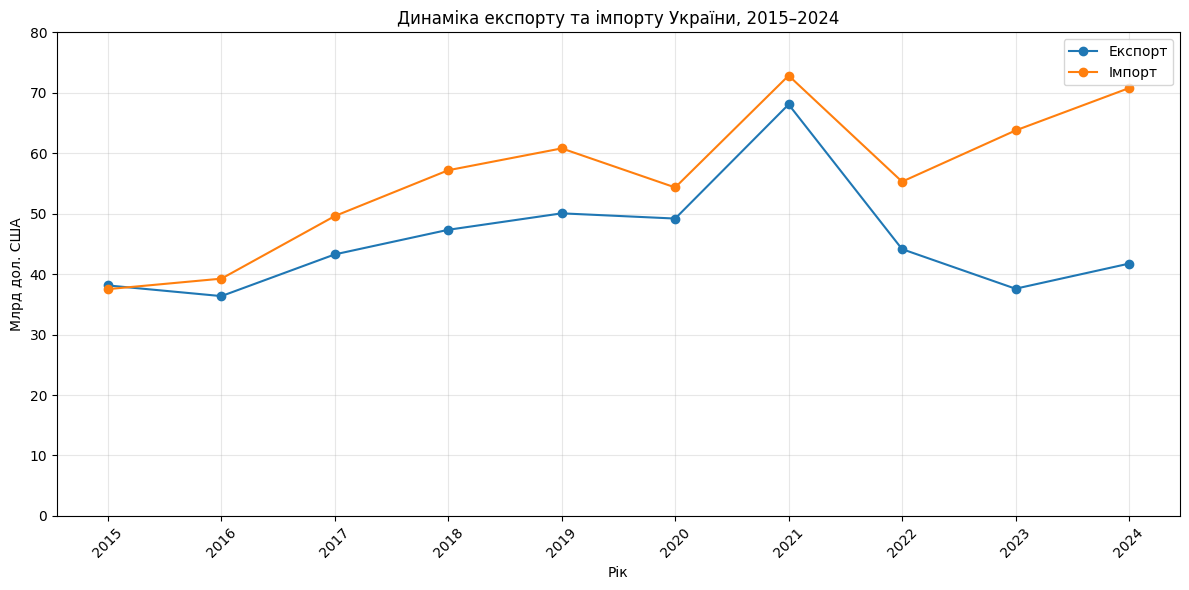

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    total_trade_analysis['Рік'],
    total_trade_analysis['Експорт, млрд дол. США'],
    marker='o',
    label='Експорт'
)

plt.plot(
    total_trade_analysis['Рік'],
    total_trade_analysis['Імпорт, млрд дол. США'],
    marker='o',
    label='Імпорт'
)

plt.title('Динаміка експорту та імпорту України, 2015–2024')
plt.xlabel('Рік')
plt.ylabel('Млрд дол. США')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.ylim(0, 80)
plt.tight_layout()
plt.show()

**Попередньо виявлені тенденції:**
1. У 2015 році експорт трохи перевищував імпорт.
2. З 2016 року імпорт щороку був більшим за експорт.
3. У 2021 році обидва показники досягли максимуму за досліджуваний період.
4. У 2022 році відбулося різке скорочення експорту й імпорту.
5. У 2023–2024 роках імпорт зростав, тоді як експорт відновлювався повільніше.
6. У 2024 році розрив між імпортом та експортом залишався значним.

###5.2 Аналіз торговельного балансу України

In [140]:
# Створюємо окрему таблицю для аналізу торговельного балансу
balance_analysis = total_trade_analysis[
    ['Рік', 'Експорт, млрд дол. США',
     'Імпорт, млрд дол. США',
     'Торговельне сальдо, млрд дол. США']
].copy()

# Розраховуємо зміну торговельного сальдо порівняно з попереднім роком
balance_analysis['Зміна сальдо, млрд дол. США'] = (
    balance_analysis['Торговельне сальдо, млрд дол. США'].diff()
)

# Визначаємо абсолютний розмір дефіциту
balance_analysis['Дефіцит, млрд дол. США'] = (
    -balance_analysis['Торговельне сальдо, млрд дол. США']
).clip(lower=0)

###5.2.1 Графік торговельного сальдо України, 2015-2024

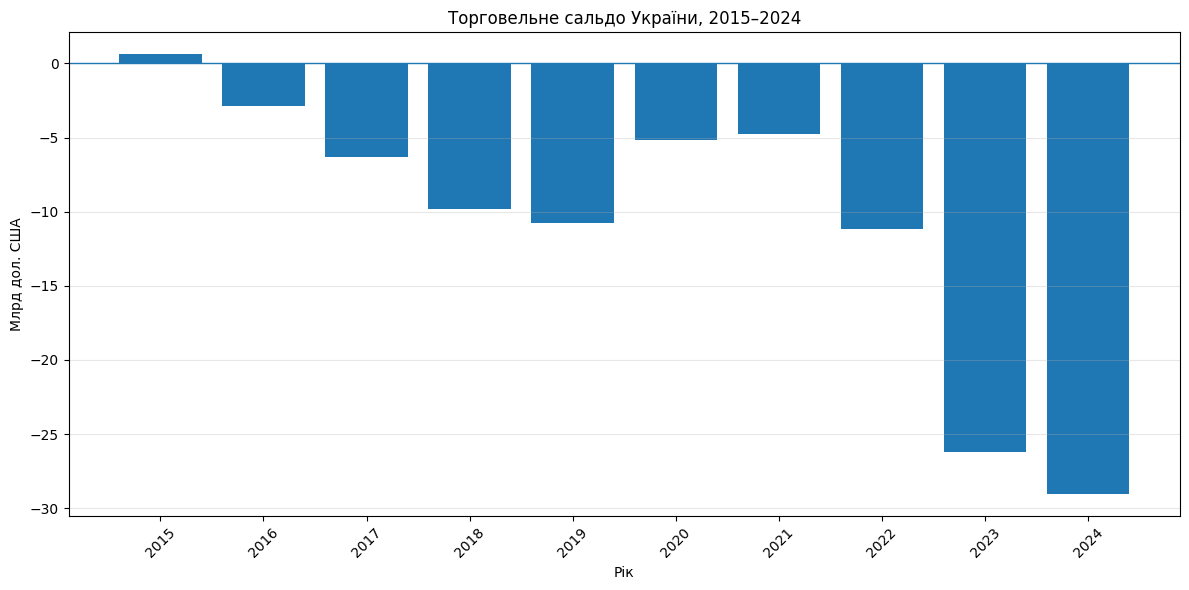

In [141]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    balance_analysis['Рік'],
    balance_analysis['Торговельне сальдо, млрд дол. США']
)

plt.axhline(y=0, linewidth=1)

plt.title('Торговельне сальдо України, 2015–2024')
plt.xlabel('Рік')
plt.ylabel('Млрд дол. США')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Висновок за результатами аналізу загальної динаміки зовнішньої торгівлі України у 2015-2024 роках**

Упродовж 2015-2024 років динаміка зовнішньої торгівлі України характеризувалася переважанням імпорту над експортом. Єдиним роком із додатним торговельним сальдо був 2015 рік, коли експорт перевищив імпорт на 0,61 млрд дол. США. Починаючи з 2016 року торговельний баланс був від'ємним.

Найбільші обсяги експорту та імпорту за досліджуваний період зафіксовано у 2021 році: відповідно 68,07 та 72,84 млрд дол. США. У 2022 році обидва показники скоротилися порівняно з попереднім роком: експорт — на 35,16%, імпорт — на 24,09%.

У 2023-2024 роках імпорт зростав швидше за відновлення експорту в абсолютному вимірі. У 2024 році експорт становив 41,73 млрд дол. США, а імпорт — 70,77 млрд дол. США. Від'ємне торговельне сальдо досягло 29,04 млрд дол. США — найбільшого значення за весь досліджуваний період.

Змінилася й частка покриття імпорту експортом: якщо у 2015 році вона становила 101,63%, то у 2024 році — 58,97%. Отже, у 2024 році на кожні 100 доларів імпорту припадало приблизно 59 доларів експорту.

Таким чином, дані за 2015-2024 роки свідчать про посилення розриву між вартісними обсягами імпорту та експорту, особливо у 2023-2024 роках. Наведені показники характеризують зовнішню торгівлю у вартісному вираженні в доларах США. Самі по собі вони не дають змоги відокремити вплив зміни цін від зміни фізичних обсягів товарів; для цього необхідно окремо проаналізувати відповідні індекси.

## 5.2. Аналіз товарної структури імпорту України.

### 5.2.1. Визначення ТОП-10 товарних груп за часткою в імпорті у 2024 році

**Мета:** визначити, які товарні групи формували найбільшу частину імпорту України у 2024 році, та оцінити їхню частку в загальному обсязі імпорту.

Використовуємо вже сформовану таблицю import_share_table, де зберігаються частки товарних груп у загальному імпорті за кожен рік.

In [142]:
# Формуємо рейтинг товарних груп за часткою в імпорті у 2024 році
top_10_import_share = (
    import_share_table[
        ['Товарна група', '2024, %']
    ]
    .sort_values('2024, %', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# Додаємо порядковий номер у рейтингу
top_10_import_share.index = top_10_import_share.index + 1

top_10_import_share

,Товарна група,"2024, %"
1,Група 27 Палива мінеральні; нафта і продукти ї...,12.578280
2,"Група 85 Електричні машини, обладнання та їх ч...",11.850786
3,"Група 87 Засоби наземного транспорту, крім зал...",10.688025
4,"Група 84 Реактори ядерні, котли, машини, облад...",9.402880
5,"Група 39 Пластмаси, полімерні матеріали та вир...",4.051083
6,Група 30 Фармацевтична продукція,3.438170
7,"Група 90 Прилади та апарати оптичні, фотографі...",2.457571
8,Група 72 Чорні метали,2.102512
9,"Група 88 Літальні апарати, космічні апарати та...",2.069197
10,Група 38 Різноманітна хімічна продукція,1.795431


In [143]:
top_10_total_share = top_10_import_share['2024, %'].sum()

# Розрахунок сукупних часток найбільших товарних груп
concentration_2024 = pd.DataFrame({
    'Показник': ['ТОП-3', 'ТОП-5', 'ТОП-10'],
    'Сукупна частка, %': [
        top_10_import_share.head(3)['2024, %'].sum(),
        top_10_import_share.head(5)['2024, %'].sum(),
        top_10_import_share.head(10)['2024, %'].sum()
    ]
})

concentration_2024['Сукупна частка, %'] = (
    concentration_2024['Сукупна частка, %'].round(2)
)

concentration_2024

,Показник,"Сукупна частка, %"
0,ТОП-3,35.12
1,ТОП-5,48.57
2,ТОП-10,60.43


###5.2.2. Порівняння товарної структури імпорту у 2015 та 2024 роках.

**Мета:** визначити, як змінилася частка найбільших товарних груп у загальному імпорті між 2015 та 2024 роками.

In [144]:
structure_comparison = (
    import_share_table[
        ['Товарна група', '2015, %', '2024, %']
    ]
    .copy()
)

structure_comparison['Зміна частки, в.п.'] = (
    structure_comparison['2024, %'] -
    structure_comparison['2015, %']
).round(2)

structure_comparison = (
    structure_comparison[
        structure_comparison['Товарна група'].isin(
            top_10_import_share['Товарна група']
        )
    ]
    .sort_values('2024, %', ascending=False)
    .reset_index(drop=True)
)

structure_comparison

,Товарна група,"2015, %","2024, %","Зміна частки, в.п."
0,Група 27 Палива мінеральні; нафта і продукти ї...,29.007136,12.578280,-16.43
1,"Група 85 Електричні машини, обладнання та їх ч...",7.183968,11.850786,4.67
2,"Група 87 Засоби наземного транспорту, крім зал...",4.317772,10.688025,6.37
3,"Група 84 Реактори ядерні, котли, машини, облад...",9.537713,9.402880,-0.13
4,"Група 39 Пластмаси, полімерні матеріали та вир...",5.578808,4.051083,-1.53
5,Група 30 Фармацевтична продукція,3.643828,3.438170,-0.21
6,"Група 90 Прилади та апарати оптичні, фотографі...",1.195484,2.457571,1.26
7,Група 72 Чорні метали,1.827837,2.102512,0.27
8,"Група 88 Літальні апарати, космічні апарати та...",0.146229,2.069197,1.92
9,Група 38 Різноманітна хімічна продукція,2.481758,1.795431,-0.69


### 5.2.3. Горизонтальна стовпчикова діаграма зміни часток ТОП-10 товарних груп.

Мета: наочно показати, які товарні групи посилили свої позиції, а які втратили частку.

/tmp/ipykernel_14477/2868895384.py:28: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


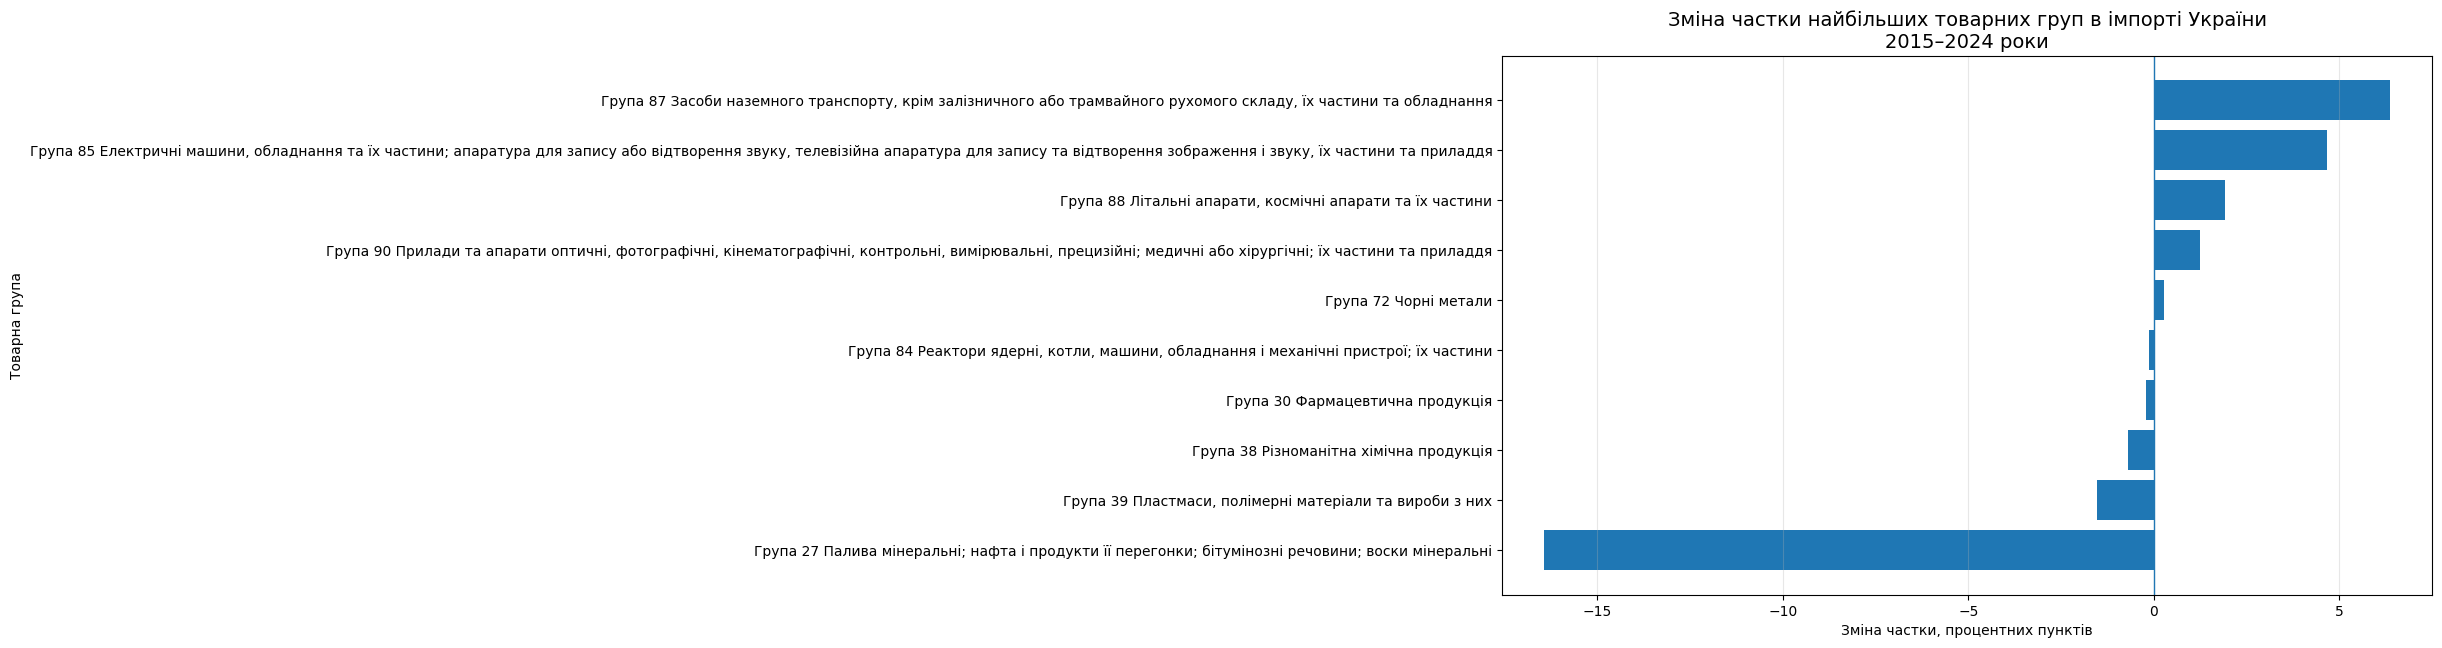

In [145]:
import matplotlib.pyplot as plt

# Сортуємо групи за величиною зміни частки
plot_structure = structure_comparison.sort_values(
    'Зміна частки, в.п.',
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_structure['Товарна група'],
    plot_structure['Зміна частки, в.п.']
)

# Нульова лінія для розмежування зростання і скорочення
plt.axvline(0, linewidth=1)

plt.title(
    'Зміна частки найбільших товарних груп в імпорті України\n'
    '2015–2024 роки',
    fontsize=14
)
plt.xlabel('Зміна частки, процентних пунктів')
plt.ylabel('Товарна група')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### 5.2.4. Аналіз динаміки часток за всіма роками.

Мета: дослідити, як змінювалася частка кожної з ТОП-10 товарних груп протягом 2015–2024 років.

Побудуємо лінійний графік, щоб побачити тенденції, переломні моменти та роки найбільших змін.

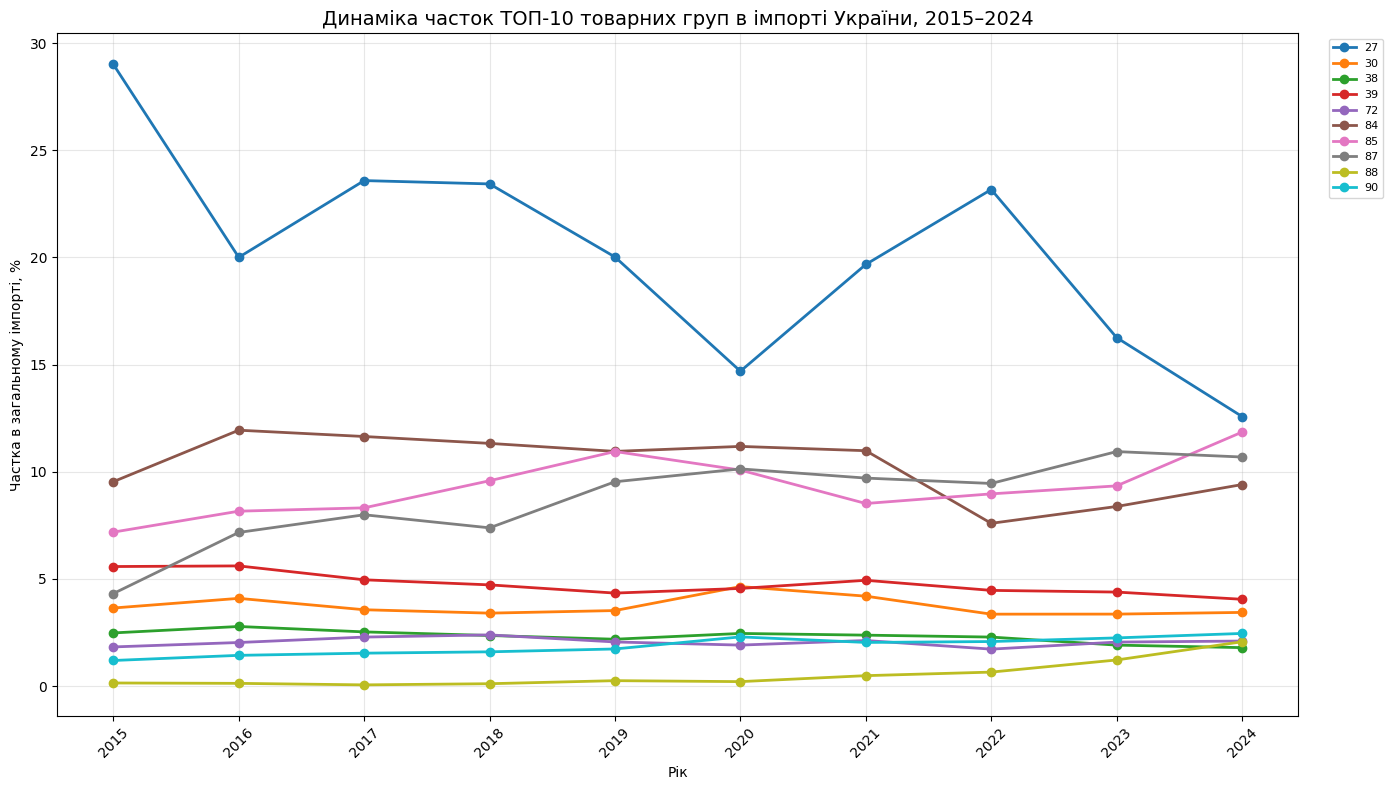

In [146]:
plt.figure(figsize=(14, 8))

for _, row in import_share_table[
    import_share_table['Товарна група'].isin(
        top_10_import_share['Товарна група']
    )
].iterrows():

    plt.plot(
        analysis_years,
        [row[f'{year}, %'] for year in analysis_years],
        marker='o',
        linewidth=2,
        label=row['Товарна група'].split(' ', 2)[1]
    )

plt.title(
    'Динаміка часток ТОП-10 товарних груп в імпорті України, 2015–2024',
    fontsize=14
)
plt.xlabel('Рік')
plt.ylabel('Частка в загальному імпорті, %')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### 5.2.5. Аналіз концентрації за роками

Ми вже визначили концентрацію ТОП-3, ТОП-5 і ТОП-10 для 2024 року. Тепер потрібно з'ясувати, чи була структура імпорту такою ж концентрованою у 2015 році та як змінювалася протягом десятиріччя.

In [147]:
# Концентрація ТОП-3, ТОП-5 і ТОП-10 товарних груп
# за офіційно наявними агрегованими значеннями за кожен рік

concentration_dynamics = pd.DataFrame({
    'Рік': analysis_years,
    'ТОП-3, %': [
        import_share_table[f'{year}, %']
        .nlargest(3).sum()
        for year in analysis_years
    ],
    'ТОП-5, %': [
        import_share_table[f'{year}, %']
        .nlargest(5).sum()
        for year in analysis_years
    ],
    'ТОП-10, %': [
        import_share_table[f'{year}, %']
        .nlargest(10).sum()
        for year in analysis_years
    ]
})

concentration_dynamics.iloc[:, 1:] = (
    concentration_dynamics.iloc[:, 1:].round(2)
)

display(concentration_dynamics)

,Рік,"ТОП-3, %","ТОП-5, %","ТОП-10, %"
0,2015,45.73,55.63,67.47
1,2016,40.10,52.88,65.92
2,2017,43.55,56.50,68.79
3,2018,44.33,56.44,67.99
4,2019,41.92,55.79,67.34
5,2020,36.01,50.73,63.66
6,2021,40.36,53.82,66.84
7,2022,41.59,53.65,67.19
8,2023,36.54,52.56,66.55
9,2024,35.12,48.57,60.43


### 5.2.6. Візуалізація концентрації імпорту

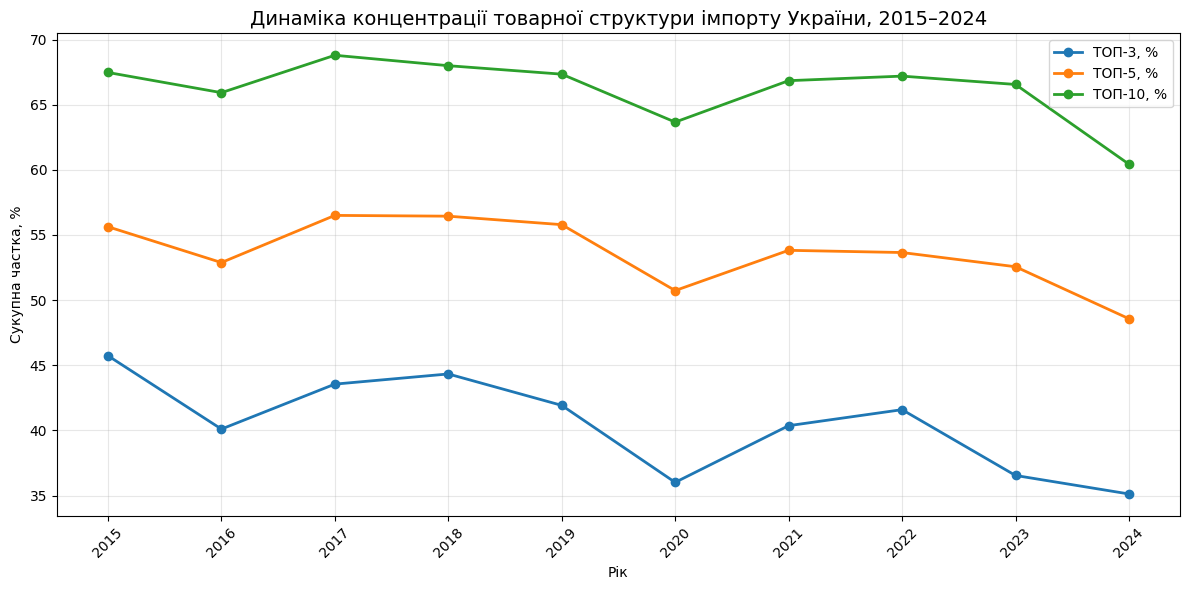

In [148]:
plt.figure(figsize=(12, 6))

for column in ['ТОП-3, %', 'ТОП-5, %', 'ТОП-10, %']:
    plt.plot(
        concentration_dynamics['Рік'],
        concentration_dynamics[column],
        marker='o',
        linewidth=2,
        label=column
    )

plt.title(
    'Динаміка концентрації товарної структури імпорту України, 2015–2024',
    fontsize=14
)
plt.xlabel('Рік')
plt.ylabel('Сукупна частка, %')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Основні спостереження по графіку:**

2017 рік: найвища концентрація ТОП-10 — 68,79%.

2020 рік: помітне зниження всіх трьох показників.

2024 рік: найнижчі значення за весь досліджуваний період: ТОП-3 — 35,12%, ТОП-5 — 48,57%, ТОП-10 — 60,43%.

**Висновки до розділу 5.2**

Аналіз товарної структури імпорту України за 2015–2024 роки показав, що найбільші частки у 2024 році припадали на мінеральне паливо (12,58%), електричні машини та обладнання (11,85%), наземний транспорт (10,69%) і механічні пристрої (9,40%). Сукупна частка десяти найбільших товарних груп становила 60,43% загального імпорту.

Порівняння 2015 та 2024 років виявило суттєве скорочення частки мінерального палива - на 16,43 процентного пункта. Водночас зросла частка наземного транспорту (+6,37 в.п.), електричних машин та обладнання (+4,67 в.п.), літальних апаратів (+1,92 в.п.).

Аналіз концентрації показав, що у 2024 році сукупні частки ТОП-3, ТОП-5 і ТОП-10 були найнижчими за досліджуваний період. Зокрема, частка ТОП-10 зменшилася з 67,47% у 2015 році до 60,43% у 2024 році.

Отримані результати свідчать про зміну співвідношення основних товарних груп у структурі імпорту. Водночас через відсутність окремих офіційних значень, зокрема для групи 99 «Різне» у 2024 році, результати оцінювання структури та концентрації слід трактувати з урахуванням неповного охоплення даних.

## 5.3. Аналіз індексів середніх цін і фізичного обсягу зовнішньої торгівлі України.

### 5.3.1. Розрахунок фактичної річної зміни показників

In [149]:
# Створюємо таблицю для аналізу річних змін
trade_indices_analysis = trade_indices_table.copy()

# Перелік показників
index_columns = [
    'Індекси середніх цін в імпорті товарів',
    'Індекси фізичного обсягу в імпорті товарів',
    'Індекси середніх цін в експорті товарів',
    'Індекси фізичного обсягу в експорті товарів'
]

# Перетворюємо індекси на фактичні річні зміни, %
for column in index_columns:
    trade_indices_analysis[column] = (
        trade_indices_analysis[column] - 100
    ).round(1)

display(trade_indices_analysis)

Показник,Рік,Індекси середніх цін в експорті товарів,Індекси фізичного обсягу в експорті товарів,Індекси середніх цін в імпорті товарів,Індекси фізичного обсягу в імпорті товарів
0,2015,-17.7,-14.0,-10.2,-23.3
1,2016,-3.8,-0.9,-3.6,8.6
2,2017,15.9,2.7,14.0,10.9
3,2018,11.8,-2.1,12.3,2.6
4,2019,0.1,5.7,0.2,6.1
5,2020,4.6,-6.0,-0.4,-10.6
6,2021,48.2,-6.6,24.6,7.6
7,2022,8.2,-40.1,37.3,-44.7
8,2023,-13.9,-4.8,7.7,6.7
9,2024,0.8,14.5,5.7,5.3


### 5.3.2. Найбільші зростання і скорочення

In [150]:
# Формуємо таблицю найбільших річних змін
extreme_changes = []

for column in index_columns:

    max_idx = trade_indices_analysis[column].idxmax()
    min_idx = trade_indices_analysis[column].idxmin()

    extreme_changes.append({
        'Показник': column,
        'Рік найбільшого зростання':
            trade_indices_analysis.loc[max_idx, 'Рік'],
        'Максимальна зміна, %':
            trade_indices_analysis.loc[max_idx, column],
        'Рік найбільшого скорочення':
            trade_indices_analysis.loc[min_idx, 'Рік'],
        'Мінімальна зміна, %':
            trade_indices_analysis.loc[min_idx, column]
    })

extreme_changes_table = pd.DataFrame(extreme_changes)

display(extreme_changes_table)

,Показник,Рік найбільшого зростання,"Максимальна зміна, %",Рік найбільшого скорочення,"Мінімальна зміна, %"
0,Індекси середніх цін в імпорті товарів,2022,37.3,2015,-10.2
1,Індекси фізичного обсягу в імпорті товарів,2017,10.9,2022,-44.7
2,Індекси середніх цін в експорті товарів,2021,48.2,2015,-17.7
3,Індекси фізичного обсягу в експорті товарів,2024,14.5,2022,-40.1


### 5.3.3. Візуалізація річних змін

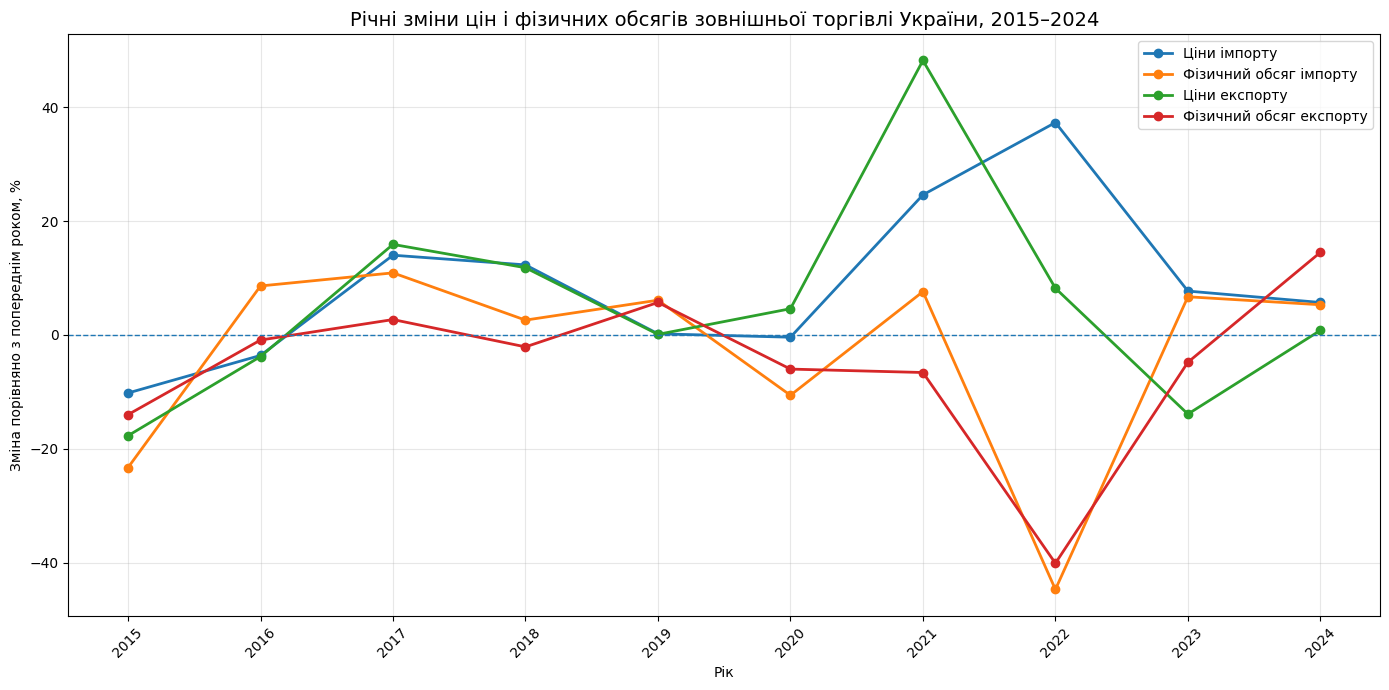

In [151]:
plt.figure(figsize=(14, 7))

plot_columns = {
    'Індекси середніх цін в імпорті товарів': 'Ціни імпорту',
    'Індекси фізичного обсягу в імпорті товарів': 'Фізичний обсяг імпорту',
    'Індекси середніх цін в експорті товарів': 'Ціни експорту',
    'Індекси фізичного обсягу в експорті товарів': 'Фізичний обсяг експорту'
}

for column, label in plot_columns.items():
    plt.plot(
        trade_indices_analysis['Рік'],
        trade_indices_analysis[column],
        marker='o',
        linewidth=2,
        label=label
    )

# Нульова лінія — відсутність річної зміни
plt.axhline(0, linewidth=1, linestyle='--')

plt.title(
    'Річні зміни цін і фізичних обсягів зовнішньої торгівлі України, 2015–2024',
    fontsize=14
)
plt.xlabel('Рік')
plt.ylabel('Зміна порівняно з попереднім роком, %')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 5.3.4. Поглиблене порівняння 2021-2024 років

Тепер зосередимося на чотирьох роках: останньому році перед повномасштабним вторгненням, 2022 році та двох наступних роках.

Мета: простежити, як змінювалися ціни та фізичні обсяги зовнішньої торгівлі після різкого падіння 2022 року.

In [152]:
# Виділяємо період 2021–2024 років
period_comparison = trade_indices_analysis[
    trade_indices_analysis['Рік'].isin(['2021', '2022', '2023', '2024'])
].copy()

display(period_comparison)

Показник,Рік,Індекси середніх цін в експорті товарів,Індекси фізичного обсягу в експорті товарів,Індекси середніх цін в імпорті товарів,Індекси фізичного обсягу в імпорті товарів
6,2021,48.2,-6.6,24.6,7.6
7,2022,8.2,-40.1,37.3,-44.7
8,2023,-13.9,-4.8,7.7,6.7
9,2024,0.8,14.5,5.7,5.3


In [153]:
# Оцінка фізичних обсягів у 2024 році відносно 2021 року

export_volume_recovery = (
    trade_indices_table.loc[
        trade_indices_table['Рік'].isin(['2022', '2023', '2024']),
        'Індекси фізичного обсягу в експорті товарів'
    ].prod() / 100**2
)

import_volume_recovery = (
    trade_indices_table.loc[
        trade_indices_table['Рік'].isin(['2022', '2023', '2024']),
        'Індекси фізичного обсягу в імпорті товарів'
    ].prod() / 100**2
)

recovery_comparison = pd.DataFrame({
    'Показник': ['Фізичний обсяг експорту', 'Фізичний обсяг імпорту'],
    'Рівень 2024 до 2021, %': [
        export_volume_recovery,
        import_volume_recovery
    ]
})

recovery_comparison['Рівень 2024 до 2021, %'] = (
    recovery_comparison['Рівень 2024 до 2021, %'].round(2)
)

recovery_comparison['Відхилення від рівня 2021, %'] = (
    recovery_comparison['Рівень 2024 до 2021, %'] - 100
).round(2)

display(recovery_comparison)

,Показник,"Рівень 2024 до 2021, %","Відхилення від рівня 2021, %"
0,Фізичний обсяг експорту,65.29,-34.71
1,Фізичний обсяг імпорту,62.13,-37.87


### Оцінка відновлення фізичних обсягів зовнішньої торгівлі

Порівняння фізичних обсягів експорту та імпорту у 2024 році з рівнем 2021 року показало, що відновлення після різкого скорочення у 2022 році залишалося неповним.

За результатами послідовного перемноження річних індексів фізичного обсягу, у 2024 році експорт становив 65,29% від рівня 2021 року, а імпорт - 62,13%. Таким чином, фізичний обсяг експорту залишався нижчим на 34,71%, а імпорту - на 37,87%.

Отже, позитивні річні зміни у 2023-2024 роках ще не означали повернення до попереднього рівня зовнішньоторговельної активності. За фізичними обсягами відновлення експорту було дещо швидшим, ніж імпорту.

### 5.3.5. Накопичена зміна середніх цін
Тепер проведемо аналогічний розрахунок для цінових індексів.

Мета: визначити, наскільки змінився рівень середніх цін експорту та імпорту у 2024 році порівняно з 2021 роком.

In [154]:
# Розрахунок накопиченої зміни середніх цін за 2022–2024 роки

export_price_level = (
    trade_indices_table.loc[
        trade_indices_table['Рік'].isin(['2022', '2023', '2024']),
        'Індекси середніх цін в експорті товарів'
    ].prod() / 100**2
)

import_price_level = (
    trade_indices_table.loc[
        trade_indices_table['Рік'].isin(['2022', '2023', '2024']),
        'Індекси середніх цін в імпорті товарів'
    ].prod() / 100**2
)

price_comparison = pd.DataFrame({
    'Показник': ['Середні ціни експорту', 'Середні ціни імпорту'],
    'Рівень 2024 до 2021, %': [
        export_price_level,
        import_price_level
    ]
})

price_comparison['Рівень 2024 до 2021, %'] = (
    price_comparison['Рівень 2024 до 2021, %'].round(2)
)

price_comparison['Зміна відносно 2021, %'] = (
    price_comparison['Рівень 2024 до 2021, %'] - 100
).round(2)

display(price_comparison)

,Показник,"Рівень 2024 до 2021, %","Зміна відносно 2021, %"
0,Середні ціни експорту,93.91,-6.09
1,Середні ціни імпорту,156.30,56.30


Основні спостереження:
1. Середні ціни імпорту у 2024 році були на 56,3% вищими за рівень 2021 року.
2. Середні ціни експорту, навпаки, залишалися на 6,09% нижчими.
3. Фізичний обсяг експорту не досяг рівня 2021 року - відставання становило 34,71%.
4. Фізичний обсяг імпорту відставав ще більше - на 37,87%.


### 5.3.6. Формуємо підсумкову таблицю цінових і фізичних змін

In [155]:
# Об'єднуємо результати аналізу цін і фізичних обсягів

trade_recovery_summary = pd.DataFrame({
    'Показник': [
        'Середні ціни експорту',
        'Фізичний обсяг експорту',
        'Середні ціни імпорту',
        'Фізичний обсяг імпорту'
    ],
    'Рівень 2024 до 2021, %': [
        price_comparison.loc[0, 'Рівень 2024 до 2021, %'],
        recovery_comparison.loc[0, 'Рівень 2024 до 2021, %'],
        price_comparison.loc[1, 'Рівень 2024 до 2021, %'],
        recovery_comparison.loc[1, 'Рівень 2024 до 2021, %']
    ]
})

trade_recovery_summary['Зміна відносно 2021, %'] = (
    trade_recovery_summary['Рівень 2024 до 2021, %'] - 100
).round(2)

display(trade_recovery_summary)

,Показник,"Рівень 2024 до 2021, %","Зміна відносно 2021, %"
0,Середні ціни експорту,93.91,-6.09
1,Фізичний обсяг експорту,65.29,-34.71
2,Середні ціни імпорту,156.30,56.30
3,Фізичний обсяг імпорту,62.13,-37.87


**Висновки до розділу 5.3**

Аналіз індексів середніх цін і фізичного обсягу зовнішньої торгівлі України за 2015-2024 роки виявив суттєві зміни у 2022 році. Тоді фізичний обсяг експорту скоротився на 40,1%, а імпорту - на 44,7%. Одночасно середні ціни експорту зросли на 8,2%, а імпорту - на 37,3%.

У 2023-2024 роках спостерігалося зростання фізичних обсягів торгівлі, однак воно не забезпечило повернення до рівня 2021 року. За результатами послідовного перемноження річних індексів, у 2024 році фізичний обсяг експорту становив 65,29% від рівня 2021 року, а імпорту - 62,13%.

Цінова динаміка за цей період була різною: середні ціни експорту у 2024 році становили 93,91% від рівня 2021 року, тоді як середні ціни імпорту досягли 156,30%.

Таким чином, відновлення фізичних обсягів зовнішньої торгівлі залишалося неповним, а цінова динаміка експорту та імпорту суттєво відрізнялася. Під час інтерпретації цінових індексів необхідно враховувати, що вони відображають також можливий вплив змін товарної структури.

## 5.4 Аналіз географічної структури імпорту України.

### 5.4.1. Визначення ТОП-10 географічних напрямків імпорту у 2024 році

In [156]:
# Визначаємо ТОП-10 географічних напрямків імпорту у 2024 році

top_10_countries_2024 = (
    import_countries_table[
        ['Країна контрагент', '2024']
    ]
    .dropna(subset=['2024'])
    .sort_values('2024', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# Переводимо обсяги з тисяч доларів у мільярди доларів
top_10_countries_2024['Імпорт, млрд дол. США'] = (
    top_10_countries_2024['2024'] / 1_000_000
)

display(
    top_10_countries_2024[
        ['Країна контрагент', 'Імпорт, млрд дол. США']
    ]
)

,Країна контрагент,"Імпорт, млрд дол. США"
0,Китай,14.369973
1,Польща,6.990086
2,Німеччина,5.386242
3,Туреччина,4.242425
4,США,3.472010
5,Італія,2.576192
6,Чехія,2.476501
7,Болгарія,2.360147
8,Греція,2.067067
9,Словаччина,2.001062


In [157]:
# Отримуємо загальний обсяг імпорту за 2024 рік
total_import_2024 = total_trade_table.loc[
    total_trade_table['Рік'] == '2024',
    'Імпорт, млрд дол. США'
].iloc[0]

# Розраховуємо частки ТОП-10 країн
top_10_countries_2024['Частка в імпорті, %'] = (
    top_10_countries_2024['Імпорт, млрд дол. США']
    / total_import_2024 * 100
)

display(
    top_10_countries_2024[
        [
            'Країна контрагент',
            'Імпорт, млрд дол. США',
            'Частка в імпорті, %'
        ]
    ]
)

,Країна контрагент,"Імпорт, млрд дол. США","Частка в імпорті, %"
0,Китай,14.369973,20.305010
1,Польща,6.990086,9.877108
2,Німеччина,5.386242,7.610849
3,Туреччина,4.242425,5.994616
4,США,3.472010,4.906007
5,Італія,2.576192,3.640202
6,Чехія,2.476501,3.499337
7,Болгарія,2.360147,3.334926
8,Греція,2.067067,2.920800
9,Словаччина,2.001062,2.827533


### 5.4.2. Оцінка концентрації імпорту за країнами у 2024 році

In [158]:
# Розраховуємо концентрацію імпорту за ТОП-3, ТОП-5 і ТОП-10 країн
country_concentration_2024 = pd.DataFrame({
    'Показник': ['ТОП-3 країни', 'ТОП-5 країн', 'ТОП-10 країн'],
    'Частка імпорту, %': [
        top_10_countries_2024.head(3)['Частка в імпорті, %'].sum(),
        top_10_countries_2024.head(5)['Частка в імпорті, %'].sum(),
        top_10_countries_2024['Частка в імпорті, %'].sum()
    ]
})

country_concentration_2024['Частка імпорту, %'] = (
    country_concentration_2024['Частка імпорту, %'].round(2)
)

display(country_concentration_2024)

,Показник,"Частка імпорту, %"
0,ТОП-3 країни,37.79
1,ТОП-5 країн,48.69
2,ТОП-10 країн,64.92


**Перевіряємо:** чи змінювалася частка найбільших постачальників у загальному імпорті, зокрема після 2022 року.

In [159]:
# Розраховуємо частки країн у загальному імпорті за кожен рік
country_share_table = import_countries_table.copy()

for year in analysis_years:
    total_import = total_trade_table.loc[
        total_trade_table['Рік'] == year,
        'Імпорт, млрд дол. США'
    ].iloc[0]

    country_share_table[year] = (
        country_share_table[year] / 1_000_000
        / total_import * 100
    )

# Розраховуємо концентрацію ТОП-3, ТОП-5 і ТОП-10 за кожен рік
country_concentration_by_year = []

for year in analysis_years:
    yearly_data = (
        country_share_table[['Країна контрагент', year]]
        .dropna(subset=[year])
        .sort_values(year, ascending=False)
    )

    country_concentration_by_year.append({
        'Рік': year,
        'ТОП-3, %': yearly_data.head(3)[year].sum(),
        'ТОП-5, %': yearly_data.head(5)[year].sum(),
        'ТОП-10, %': yearly_data.head(10)[year].sum()
    })

country_concentration_by_year = pd.DataFrame(
    country_concentration_by_year
).round(2)

display(country_concentration_by_year)

,Рік,"ТОП-3, %","ТОП-5, %","ТОП-10, %"
0,2015,40.62,53.34,68.83
1,2016,36.07,50.00,66.97
2,2017,36.89,50.31,67.76
3,2018,37.91,50.90,68.10
4,2019,36.47,49.40,67.43
5,2020,33.50,46.76,65.70
6,2021,32.05,45.49,64.06
7,2022,33.86,43.89,59.47
8,2023,34.70,46.61,62.19
9,2024,37.79,48.69,64.92


### 5.4.3. Лінійний графік концентрації ТОП-3, ТОП-5 і ТОП-10 за 2015-2024 роки.

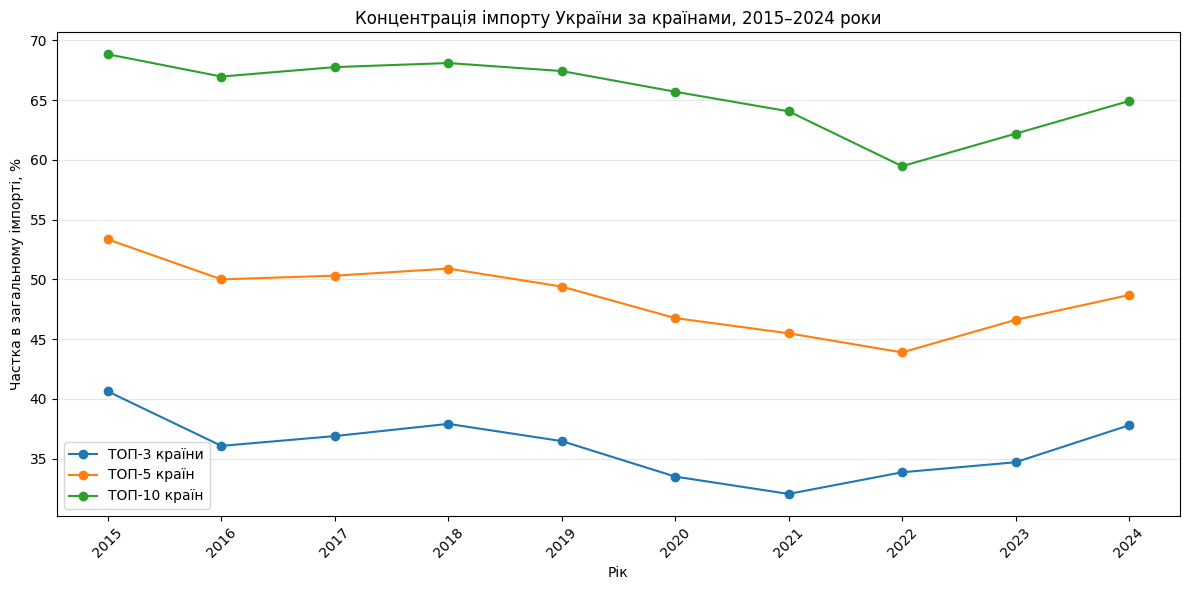

In [160]:
plt.figure(figsize=(12, 6))

plt.plot(
    country_concentration_by_year['Рік'],
    country_concentration_by_year['ТОП-3, %'],
    marker='o',
    label='ТОП-3 країни'
)

plt.plot(
    country_concentration_by_year['Рік'],
    country_concentration_by_year['ТОП-5, %'],
    marker='o',
    label='ТОП-5 країн'
)

plt.plot(
    country_concentration_by_year['Рік'],
    country_concentration_by_year['ТОП-10, %'],
    marker='o',
    label='ТОП-10 країн'
)

plt.title('Концентрація імпорту України за країнами, 2015–2024 роки')
plt.xlabel('Рік')
plt.ylabel('Частка в загальному імпорті, %')
plt.xticks(country_concentration_by_year['Рік'], rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 5.4.3. Порівняння ТОП-10 країн-постачальників у 2021 та 2022 роках

**Мета - визначити:**
- які країни входили до ТОП-10 у кожному році;
- які країни зберегли позиції, вибули або з'явилися в рейтингу;
- як змінилися обсяги імпорту та частки окремих країн.

In [161]:
# Формуємо ТОП-10 країн за обсягом імпорту у 2021 та 2022 роках
top_countries_2021 = (
    import_countries_table[
        ['Країна контрагент', '2021']
    ]
    .dropna(subset=['2021'])
    .sort_values('2021', ascending=False)
    .head(10)
    .copy()
)

top_countries_2022 = (
    import_countries_table[
        ['Країна контрагент', '2022']
    ]
    .dropna(subset=['2022'])
    .sort_values('2022', ascending=False)
    .head(10)
    .copy()
)

# Переводимо обсяги імпорту в млрд дол. США
top_countries_2021['Імпорт, млрд дол. США'] = (
    top_countries_2021['2021'] / 1_000_000
).round(2)

top_countries_2022['Імпорт, млрд дол. США'] = (
    top_countries_2022['2022'] / 1_000_000
).round(2)

display(top_countries_2021[
    ['Країна контрагент', 'Імпорт, млрд дол. США']
])

display(top_countries_2022[
    ['Країна контрагент', 'Імпорт, млрд дол. США']
])

,Країна контрагент,"Імпорт, млрд дол. США"
96,Китай,10.98
151,Німеччина,6.28
182,Російська Федерація,6.08
170,Польща,4.96
46,Білорусь,4.82
185,США,3.33
221,Туреччина,3.26
11,Італія,2.68
242,Швейцарія,2.50
232,Франція,1.76


,Країна контрагент,"Імпорт, млрд дол. США"
96,Китай,8.67
170,Польща,5.49
151,Німеччина,4.56
221,Туреччина,3.37
185,США,2.17
34,Болгарія,2.08
11,Італія,1.80
4,Індія,1.68
182,Російська Федерація,1.54
184,Румунія,1.50


In [162]:
# Об'єднуємо країни, які входили до ТОП-10 хоча б в одному році
countries_comparison = pd.DataFrame({
    'Країна контрагент': list(
        set(top_countries_2021['Країна контрагент']) |
        set(top_countries_2022['Країна контрагент'])
    )
})

# Додаємо обсяги імпорту за обидва роки
countries_comparison = countries_comparison.merge(
    import_countries_table[
        ['Країна контрагент', '2021', '2022']
    ],
    on='Країна контрагент',
    how='left'
)

# Розраховуємо частки в загальному імпорті
total_import_2021 = total_trade_table.loc[
    total_trade_table['Рік'] == '2021',
    'Імпорт, млрд дол. США'
].iloc[0]

total_import_2022 = total_trade_table.loc[
    total_trade_table['Рік'] == '2022',
    'Імпорт, млрд дол. США'
].iloc[0]

countries_comparison['Частка 2021, %'] = (
    countries_comparison['2021'] / 1_000_000
    / total_import_2021 * 100
)

countries_comparison['Частка 2022, %'] = (
    countries_comparison['2022'] / 1_000_000
    / total_import_2022 * 100
)

# Розраховуємо абсолютну зміну обсягу імпорту
countries_comparison['Зміна імпорту, млрд дол. США'] = (
    (countries_comparison['2022'] - countries_comparison['2021'])
    / 1_000_000
)

# Розраховуємо зміну частки у відсоткових пунктах
countries_comparison['Зміна частки, в. п.'] = (
    countries_comparison['Частка 2022, %']
    - countries_comparison['Частка 2021, %']
)

# Формуємо підсумкову таблицю
countries_comparison = countries_comparison[
    [
        'Країна контрагент',
        'Частка 2021, %',
        'Частка 2022, %',
        'Зміна частки, в. п.',
        'Зміна імпорту, млрд дол. США'
    ]
].sort_values(
    'Частка 2021, %',
    ascending=False
).round(2).reset_index(drop=True)

display(countries_comparison)

,Країна контрагент,"Частка 2021, %","Частка 2022, %","Зміна частки, в. п.","Зміна імпорту, млрд дол. США"
0,Китай,15.08,15.68,0.61,-2.31
1,Німеччина,8.63,8.25,-0.38,-1.72
2,Російська Федерація,8.35,2.79,-5.56,-4.54
3,Польща,6.81,9.93,3.12,0.53
4,Білорусь,6.62,2.50,-4.13,-3.44
5,США,4.58,3.93,-0.65,-1.16
6,Туреччина,4.48,6.10,1.62,0.11
7,Італія,3.67,3.26,-0.42,-0.87
8,Швейцарія,3.43,1.83,-1.60,-1.49
9,Франція,2.42,2.23,-0.19,-0.53


Візуалізація змін часток

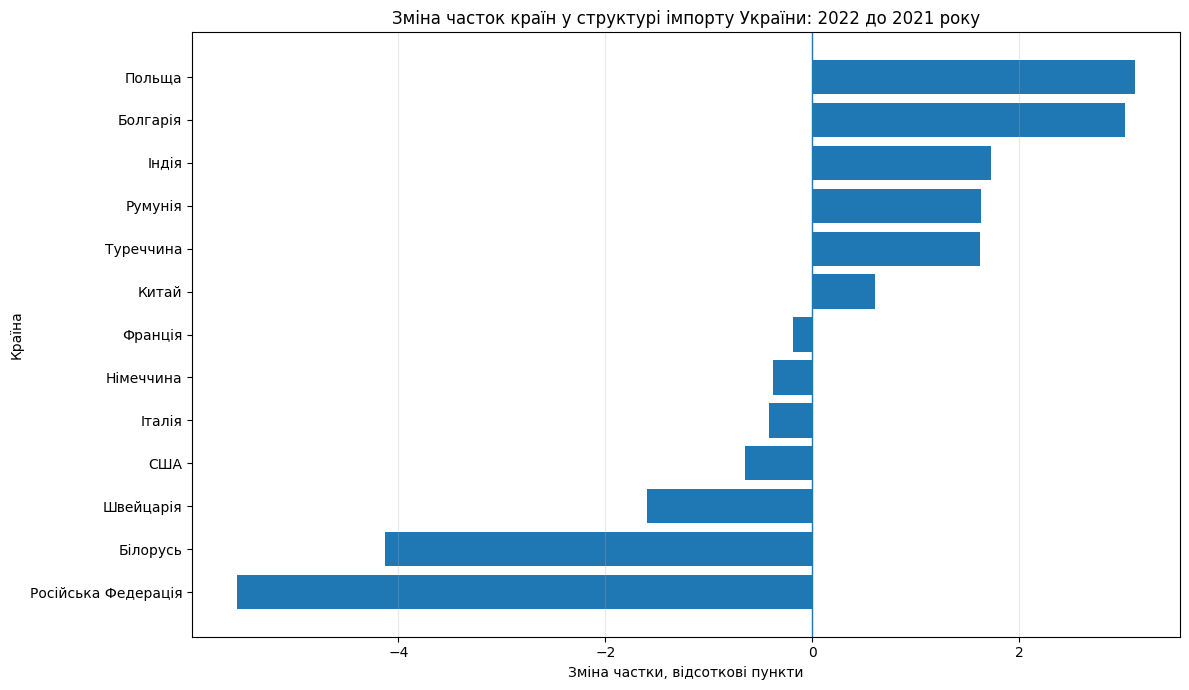

In [163]:
plt.figure(figsize=(12, 7))

countries_sorted = countries_comparison.sort_values(
    'Зміна частки, в. п.'
)

plt.barh(
    countries_sorted['Країна контрагент'],
    countries_sorted['Зміна частки, в. п.']
)

plt.axvline(0, linewidth=1)
plt.title('Зміна часток країн у структурі імпорту України: 2022 до 2021 року')
plt.xlabel('Зміна частки, відсоткові пункти')
plt.ylabel('Країна')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Висновок до підрозділу 5.4.3**

Порівняння географічної структури імпорту у 2021 та 2022 роках засвідчило суттєву зміну складу провідних торговельних партнерів України. До ТОП-10 за обсягом імпорту у 2022 році увійшли Болгарія, Індія та Румунія, тоді як Білорусь, Швейцарія та Франція вибули з рейтингу.

Найбільше скоротилася частка Російської Федерації — на 5,56 відсоткового пункта, а також Білорусі — на 4,13 в. п. Водночас зросла частка Польщі (+3,12 в. п.), Болгарії (+3,02 в. п.), Індії (+1,73 в. п.) та Румунії (+1,63 в. п.).

Китай зберіг перше місце за обсягом імпорту. Попри скорочення абсолютного обсягу імпорту з цієї країни на 2,31 млрд дол. США, її частка зросла на 0,61 в. п.

Отримані результати свідчать про перерозподіл географічної структури імпорту у 2022 році. Водночас наведене порівняння охоплює лише країни, які входили до ТОП-10 хоча б в одному з двох років, і не є повним аналізом усіх географічних напрямків.

### 5.4.4. Довгострокова зміна позицій країн-постачальників у 2015-2024 роках

In [164]:
# Формуємо рейтинги всіх географічних напрямків за 2015 і 2024 роки
country_ranking_2015 = (
    import_countries_table[
        ['Країна контрагент', '2015']
    ]
    .dropna(subset=['2015'])
    .sort_values('2015', ascending=False)
    .reset_index(drop=True)
)

country_ranking_2024 = (
    import_countries_table[
        ['Країна контрагент', '2024']
    ]
    .dropna(subset=['2024'])
    .sort_values('2024', ascending=False)
    .reset_index(drop=True)
)

# Присвоюємо кожній країні її місце в рейтингу
country_ranking_2015['Місце 2015'] = range(
    1, len(country_ranking_2015) + 1
)

country_ranking_2024['Місце 2024'] = range(
    1, len(country_ranking_2024) + 1
)

# Визначаємо країни, які входили до ТОП-10 хоча б в одному році
top_countries_2015_2024 = set(
    country_ranking_2015.head(10)['Країна контрагент']
) | set(
    country_ranking_2024.head(10)['Країна контрагент']
)

# Об'єднуємо рейтинги
long_term_country_comparison = (
    country_ranking_2015[
        ['Країна контрагент', 'Місце 2015', '2015']
    ]
    .merge(
        country_ranking_2024[
            ['Країна контрагент', 'Місце 2024', '2024']
        ],
        on='Країна контрагент',
        how='outer'
    )
)

# Залишаємо країни з ТОП-10 хоча б одного року
long_term_country_comparison = (
    long_term_country_comparison[
        long_term_country_comparison['Країна контрагент'].isin(
            top_countries_2015_2024
        )
    ].copy()
)

# Розраховуємо зміну позиції та обсягів імпорту
long_term_country_comparison['Зміна місця'] = (
    long_term_country_comparison['Місце 2015']
    - long_term_country_comparison['Місце 2024']
)

long_term_country_comparison['Імпорт 2015, млрд дол. США'] = (
    long_term_country_comparison['2015'] / 1_000_000
)

long_term_country_comparison['Імпорт 2024, млрд дол. США'] = (
    long_term_country_comparison['2024'] / 1_000_000
)

long_term_country_comparison['Зміна імпорту, млрд дол. США'] = (
    long_term_country_comparison['Імпорт 2024, млрд дол. США']
    - long_term_country_comparison['Імпорт 2015, млрд дол. США']
)

# Сортуємо за місцем у рейтингу 2015 року
long_term_country_comparison = (
    long_term_country_comparison
    .sort_values('Місце 2015', na_position='last')
    .reset_index(drop=True)
)

display(
    long_term_country_comparison[
        [
            'Країна контрагент',
            'Місце 2015',
            'Місце 2024',
            'Зміна місця',
            'Імпорт 2015, млрд дол. США',
            'Імпорт 2024, млрд дол. США',
            'Зміна імпорту, млрд дол. США'
        ]
    ].round(2)
)

,Країна контрагент,Місце 2015,Місце 2024,Зміна місця,"Імпорт 2015, млрд дол. США","Імпорт 2024, млрд дол. США","Зміна імпорту, млрд дол. США"
0,Російська Федерація,1.0,122.0,-121.0,7.49,0.00,-7.49
1,Німеччина,2.0,3.0,-1.0,3.98,5.39,1.41
2,Китай,3.0,1.0,2.0,3.77,14.37,10.60
3,Білорусь,4.0,89.0,-85.0,2.45,0.02,-2.43
4,Польща,5.0,2.0,3.0,2.32,6.99,4.67
5,Угорщина,6.0,13.0,-7.0,1.61,1.62,0.01
6,США,7.0,5.0,2.0,1.48,3.47,1.99
7,Італія,8.0,6.0,2.0,0.98,2.58,1.60
8,Франція,9.0,12.0,-3.0,0.89,1.62,0.73
9,Туреччина,10.0,4.0,6.0,0.85,4.24,3.39


**За 2015-2024 роки можна виділити три помітні зміни:**
1. Посилення позицій Китаю та європейських постачальників. Китай став найбільшим напрямком імпорту, Польща посіла друге місце. Помітно піднялися Болгарія, Греція, Словаччина та Чехія.
2. Різке скорочення імпорту з Російської Федерації та Білорусі. Обидві країни втратили практично весь попередній обсяг імпорту в межах розглянутого періоду.
3. Зміна географічного балансу. У 2024 році серед десяти найбільших напрямків переважають європейські країни, а Китай посідає перше місце.

### 5.4.5. Аналіз ролі Європейського Союзу в імпорті України

In [165]:
# Перевіряємо наявність агрегованого показника країн ЄС
eu_import_preview = countries_total_preview[
    countries_total_preview['Країна контрагент'] == 'Країни ЄС'
].copy()

display(
    eu_import_preview[
        ['Країна контрагент'] + analysis_years
    ]
)

,Країна контрагент,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
23318,Країни ЄС,15330156.2,17140841.8,20799357.1,23216495.4,25012187.7,23859713.0,28954281.2,26962397.1,32641399.4,35713318.0


5.4.5.1. Розрахунок обсягу та частки імпорту з ЄС

In [166]:
# Формуємо таблицю імпорту з країн ЄС
eu_import_table = pd.DataFrame({
    'Рік': analysis_years,
    'Імпорт з ЄС, млрд дол. США': [
        eu_import_preview[year].iloc[0] / 1_000_000
        for year in analysis_years
    ],
    'Загальний імпорт, млрд дол. США': [
        total_trade_table.loc[
            total_trade_table['Рік'] == year,
            'Імпорт, млрд дол. США'
        ].iloc[0]
        for year in analysis_years
    ]
})

# Розраховуємо частку ЄС у загальному імпорті
eu_import_table['Частка ЄС у загальному імпорті, %'] = (
    eu_import_table['Імпорт з ЄС, млрд дол. США'] /
    eu_import_table['Загальний імпорт, млрд дол. США'] * 100
)

display(eu_import_table.round(2))

,Рік,"Імпорт з ЄС, млрд дол. США","Загальний імпорт, млрд дол. США","Частка ЄС у загальному імпорті, %"
0,2015,15.33,37.52,40.86
1,2016,17.14,39.25,43.67
2,2017,20.80,49.61,41.93
3,2018,23.22,57.19,40.60
4,2019,25.01,60.80,41.14
5,2020,23.86,54.34,43.91
6,2021,28.95,72.84,39.75
7,2022,26.96,55.30,48.76
8,2023,32.64,63.76,51.19
9,2024,35.71,70.77,50.46


5.4.5.2. Графік - Динаміка імпорту з ЄС, 2015-2024 роки

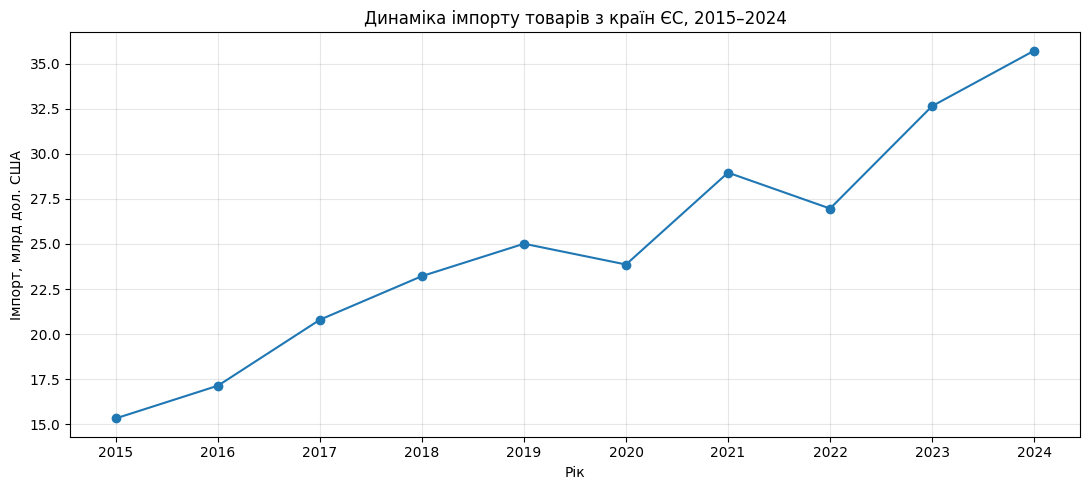

In [167]:
plt.figure(figsize=(11, 5))

plt.plot(
    eu_import_table['Рік'],
    eu_import_table['Імпорт з ЄС, млрд дол. США'],
    marker='o'
)

plt.title('Динаміка імпорту товарів з країн ЄС, 2015–2024')
plt.xlabel('Рік')
plt.ylabel('Імпорт, млрд дол. США')
plt.xticks(eu_import_table['Рік'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5.4.6. Зміна часток провідних країн у 2015 та 2024 роках.

In [168]:
# Визначаємо загальний імпорт за 2015 та 2024 роки
total_import_2015 = total_trade_table.loc[
    total_trade_table['Рік'] == '2015',
    'Імпорт, млрд дол. США'
].iloc[0]

total_import_2024 = total_trade_table.loc[
    total_trade_table['Рік'] == '2024',
    'Імпорт, млрд дол. США'
].iloc[0]

# Розраховуємо частки країн у загальному імпорті
long_term_country_comparison['Частка 2015, %'] = (
    long_term_country_comparison['Імпорт 2015, млрд дол. США']
    / total_import_2015 * 100
)

long_term_country_comparison['Частка 2024, %'] = (
    long_term_country_comparison['Імпорт 2024, млрд дол. США']
    / total_import_2024 * 100
)

# Зміна частки у відсоткових пунктах
long_term_country_comparison['Зміна частки, в. п.'] = (
    long_term_country_comparison['Частка 2024, %']
    - long_term_country_comparison['Частка 2015, %']
)

display(
    long_term_country_comparison[
        [
            'Країна контрагент',
            'Частка 2015, %',
            'Частка 2024, %',
            'Зміна частки, в. п.',
            'Зміна імпорту, млрд дол. США'
        ]
    ].sort_values('Зміна частки, в. п.', ascending=False).round(2)
)

,Країна контрагент,"Частка 2015, %","Частка 2024, %","Зміна частки, в. п.","Зміна імпорту, млрд дол. США"
2,Китай,10.05,20.31,10.25,10.60
9,Туреччина,2.27,5.99,3.72,3.39
4,Польща,6.19,9.88,3.68,4.67
12,Болгарія,0.67,3.33,2.66,2.11
13,Греція,0.64,2.92,2.28,1.83
10,Чехія,1.28,3.50,2.22,2.00
11,Словаччина,0.92,2.83,1.90,1.65
7,Італія,2.60,3.64,1.04,1.60
6,США,3.95,4.91,0.96,1.99
8,Франція,2.38,2.29,-0.09,0.73


### 5.4.7. Графік - Порівняння часток країн у загальному імпорті за 2015 і 2024 роки.

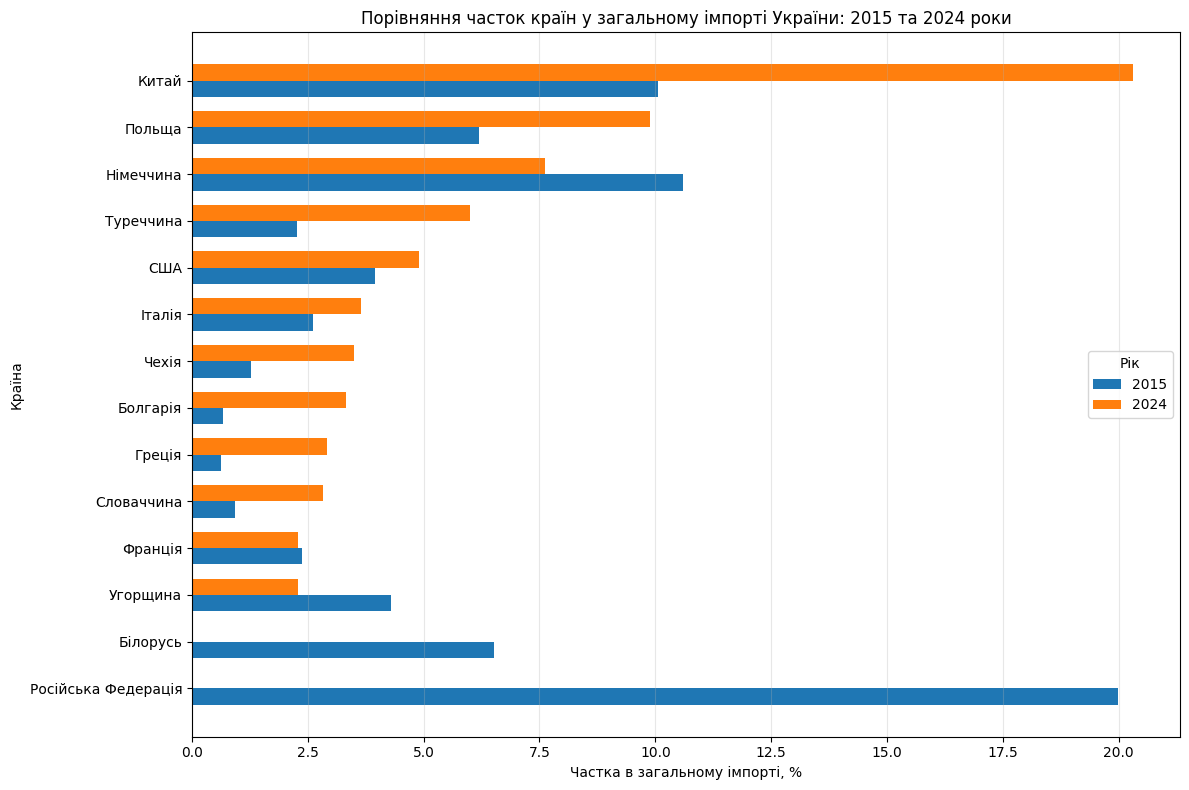

In [169]:
import matplotlib.pyplot as plt
import numpy as np

# Сортуємо країни за часткою імпорту у 2024 році
chart_data = long_term_country_comparison.sort_values(
    'Частка 2024, %',
    ascending=True
)

y = np.arange(len(chart_data))
height = 0.35

plt.figure(figsize=(12, 8))

plt.barh(
    y - height / 2,
    chart_data['Частка 2015, %'],
    height,
    label='2015'
)

plt.barh(
    y + height / 2,
    chart_data['Частка 2024, %'],
    height,
    label='2024'
)

plt.yticks(y, chart_data['Країна контрагент'])

plt.title(
    'Порівняння часток країн у загальному імпорті України: 2015 та 2024 роки'
)
plt.xlabel('Частка в загальному імпорті, %')
plt.ylabel('Країна')

plt.legend(title='Рік')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Висновки за напрямом 5.4. Географічна структура імпорту України**

Аналіз географічної структури імпорту України за 2015–2024 роки виявив суттєві зміни у складі основних країн-постачальників, рівні концентрації імпорту та ролі окремих географічних напрямків.

**1. Основні країни-постачальники у 2024 році**

Найбільшим постачальником товарів в Україну у 2024 році був Китай — 14,37 млрд дол. США, або 20,31% загального імпорту. Друге місце посіла Польща — 6,99 млрд дол. США (9,88%), третє — Німеччина — 5,39 млрд дол. США (7,62%).

До ТОП-10 також увійшли Туреччина, США, Італія, Чехія, Болгарія, Греція та Словаччина.

На три найбільші країни припадало близько 37,8% імпорту, на п’ять — 48,7%, на десять — 64,9%. Отже, значна частина імпорту була зосереджена на відносно обмеженій кількості постачальників.

**2. Динаміка концентрації імпорту**

Упродовж 2015–2021 років частка ТОП-10 країн поступово знизилася з 68,83% до 64,06%. У 2022 році показник скоротився до 59,47%, а у 2023–2024 роках знову зріс і досяг 64,92%.

У 2022 році зміни концентрації на різних рівнях відрізнялися: частка ТОП-3 зросла на 1,81 відсоткового пункта порівняно з 2021 роком, тоді як частка ТОП-5 скоротилася на 1,60 в. п., а ТОП-10 — на 4,59 в. п.

Це свідчить про неоднакову динаміку часток найбільших постачальників: позиції трьох лідерів посилилися, тоді як сукупна частка ширшої групи провідних країн зменшилася.

**3. Зміни географічного складу у 2021–2022 роках**

У 2022 році до ТОП-10 увійшли Болгарія, Індія та Румунія, тоді як Білорусь, Швейцарія та Франція вибули з рейтингу.

Серед країн, які входили до ТОП-10 хоча б в одному з двох років, найбільше скоротилася частка Російської Федерації (–5,56 в. п.) та Білорусі (–4,13 в. п.). Водночас зросли частки Польщі (+3,12 в. п.), Болгарії (+3,02 в. п.), Індії (+1,73 в. п.) та Румунії (+1,63 в. п.).

Ці зміни відображають суттєву перебудову складу основних постачальників у 2022 році. Водночас порівняння охоплює лише країни, які входили до ТОП-10 хоча б в одному з років, а не всі географічні напрямки.

**4. Довгострокова зміна позицій і часток країн у 2015–2024 роках**

Порівняння часток країн у загальному імпорті за 2015 та 2024 роки демонструє найбільш помітне посилення позицій Китаю: його частка зросла з 10,05% до 20,31%, тобто на 10,25 в. п.

Також збільшилися частки Туреччини (+3,72 в. п.), Польщі (+3,68 в. п.), Болгарії (+2,66 в. п.), Греції (+2,28 в. п.), Чехії (+2,22 в. п.) та Словаччини (+1,90 в. п.).

Натомість найбільше скоротилися частки Російської Федерації (–19,97 в. п.) та Білорусі (–6,51 в. п.). Частка Німеччини зменшилася на 2,99 в. п., Угорщини — на 2,00 в. п.

У рейтингу основних постачальників Китай піднявся з третього на перше місце, Польща — з п’ятого на друге. Також покращили позиції Туреччина (з 10-го на 4-те місце), Чехія (з 14-го на 7-ме), Словаччина (з 23-го на 10-те), Болгарія (з 27-го на 8-ме) та Греція (з 29-го на 9-те).

Імпорт із Російської Федерації скоротився з 7,49 млрд дол. США у 2015 році до приблизно 1,7 млн дол. США у 2024 році. Імпорт із Білорусі зменшився з 2,45 млрд до приблизно 16,2 млн дол. США.

**5. Роль країн Європейського Союзу в імпорті України**

За агрегованими даними про імпорт із країн ЄС його обсяг зріс із 15,33 млрд дол. США у 2015 році до 35,71 млрд дол. США у 2024 році.

Частка ЄС у загальному імпорті змінилася з 40,86% у 2015 році до 50,46% у 2024 році, збільшившись на 9,60 відсоткового пункта.

Найбільш помітне зростання частки зафіксовано у 2022 році: вона збільшилася з 39,75% у 2021 році до 48,76%, хоча абсолютний обсяг імпорту з ЄС у цей період скоротився з 28,95 до 26,96 млрд дол. США. Це означає, що частка ЄС зросла на тлі скорочення загального імпорту та зміни його географічної структури.

У 2023 році обсяг імпорту з ЄС збільшився до 32,64 млрд дол. США, а частка досягла 51,19%. У 2024 році обсяг зріс до 35,71 млрд дол. США, проте частка дещо знизилася — до 50,46%.

Таким чином, за досліджуваний період країни ЄС стали важливішим сукупним напрямком імпорту України. Водночас агрегований показник ЄС не слід додавати до показників окремих країн, оскільки він охоплює їх сукупно.

**6. Загальний висновок**

У 2015–2024 роках географічна структура імпорту України суттєво змінилася. Найбільш помітними тенденціями стали посилення позицій Китаю, Польщі, Туреччини та низки інших країн, зростання сукупної частки імпорту з ЄС, а також майже повне скорочення імпорту з Російської Федерації та значне скорочення імпорту з Білорусі.

У 2024 році Китай був найбільшим окремим постачальником, тоді як країни ЄС сукупно забезпечували близько половини імпорту України. Водночас після зниження концентрації імпорту у 2022 році частка ТОП-10 країн у 2023–2024 роках знову зросла.

Отримані результати свідчать про зміну географічного складу імпорту та посилення ролі окремих постачальників і сукупного напрямку ЄС. Однак самі по собі ці дані не встановлюють причин таких змін і не дають підстав робити висновки про політичні, логістичні чи економічні чинники без додаткових джерел.

**Обмеження аналізу**

- У вихідній таблиці є пропущені значення: 45 у 2015 році та 24 у 2024 році. Вони не замінювалися нулями.
- До ТОП-10 включалися географічні напрямки з наявними значеннями відповідного року.
- Порівняння 2021–2022 років охоплює країни, які входили до ТОП-10 хоча б в одному з цих років.
- Довгострокове порівняння часток за 2015 та 2024 роки охоплює 14 країн, які входили до ТОП-10 хоча б в одному з цих років, а не всі географічні напрямки.
- Показник «Країни ЄС» є агрегованим і не додається до показників окремих країн.
- У даних за 2024 рік є невелика невідповідність між сумою імпорту за країнами та загальним імпортом; для 2019–2020 років розбіжність більша. Її причину не встановлено.
- Результати характеризують вартісну структуру імпорту в доларах США. Вони не є оцінкою фізичних обсягів поставок.

## 5.5. Аналіз динаміки вибраних товарних груп імпорту України

### 5.5.1. Аналіз динаміки ТОП-10 товарних груп

In [170]:
# Створюємо таблицю для порівняння 2015 та 2024 років
groups_dynamics = selected_groups_table[
    ['Товарна група', '2015', '2024']
].copy()

# Абсолютна зміна, млрд дол. США
groups_dynamics['Абсолютна зміна, млрд дол. США'] = (
    groups_dynamics['2024'] - groups_dynamics['2015']
) / 1_000_000

# Відносна зміна, %
groups_dynamics['Відносна зміна, %'] = (
    (groups_dynamics['2024'] / groups_dynamics['2015']) - 1
) * 100

# Переводимо обсяги імпорту в млрд дол. США
groups_dynamics['Імпорт 2015, млрд дол. США'] = (
    groups_dynamics['2015'] / 1_000_000
)

groups_dynamics['Імпорт 2024, млрд дол. США'] = (
    groups_dynamics['2024'] / 1_000_000
)

# Виводимо результат за величиною абсолютної зміни
display(
    groups_dynamics[
        [
            'Товарна група',
            'Імпорт 2015, млрд дол. США',
            'Імпорт 2024, млрд дол. США',
            'Абсолютна зміна, млрд дол. США',
            'Відносна зміна, %'
        ]
    ]
    .sort_values('Абсолютна зміна, млрд дол. США', ascending=False)
    .round(2)
)

,Товарна група,"Імпорт 2015, млрд дол. США","Імпорт 2024, млрд дол. США","Абсолютна зміна, млрд дол. США","Відносна зміна, %"
2,"Група 87 Засоби наземного транспорту, крім зал...",1.62,7.56,5.94,366.95
1,"Група 85 Електричні машини, обладнання та їх ч...",2.70,8.39,5.69,211.18
3,"Група 84 Реактори ядерні, котли, машини, облад...",3.58,6.65,3.08,85.97
8,"Група 88 Літальні апарати, космічні апарати та...",0.05,1.46,1.41,2569.31
6,"Група 90 Прилади та апарати оптичні, фотографі...",0.45,1.74,1.29,287.79
5,Група 30 Фармацевтична продукція,1.37,2.43,1.07,77.99
7,Група 72 Чорні метали,0.69,1.49,0.80,116.99
4,"Група 39 Пластмаси, полімерні матеріали та вир...",2.09,2.87,0.77,36.98
9,Група 38 Різноманітна хімічна продукція,0.93,1.27,0.34,36.47
0,Група 27 Палива мінеральні; нафта і продукти ї...,10.88,8.90,-1.98,-18.20


### 5.5.2. Аналіз зміни часток ТОП-10 товарних груп

In [171]:
# Загальний імпорт за 2015 та 2024 роки, млрд дол. США
total_import_2015 = total_trade_table.loc[
    total_trade_table['Рік'] == '2015',
    'Імпорт, млрд дол. США'
].iloc[0]

total_import_2024 = total_trade_table.loc[
    total_trade_table['Рік'] == '2024',
    'Імпорт, млрд дол. США'
].iloc[0]

# Копія таблиці вибраних товарних груп
groups_shares = selected_groups_table[
    ['Товарна група', '2015', '2024']
].copy()

# Частки у загальному імпорті
groups_shares['Частка 2015, %'] = (
    groups_shares['2015'] / 1_000_000
    / total_import_2015 * 100
)

groups_shares['Частка 2024, %'] = (
    groups_shares['2024'] / 1_000_000
    / total_import_2024 * 100
)

# Зміна частки у відсоткових пунктах
groups_shares['Зміна частки, в. п.'] = (
    groups_shares['Частка 2024, %']
    - groups_shares['Частка 2015, %']
)

# Виведення результатів
display(
    groups_shares[
        [
            'Товарна група',
            'Частка 2015, %',
            'Частка 2024, %',
            'Зміна частки, в. п.'
        ]
    ]
    .sort_values('Частка 2024, %', ascending=False)
    .round(2)
)

# Сукупна частка вибраних 10 груп
print(
    'Сукупна частка ТОП-10 груп у 2015 році:',
    round(groups_shares['Частка 2015, %'].sum(), 2), '%'
)

print(
    'Сукупна частка ТОП-10 груп у 2024 році:',
    round(groups_shares['Частка 2024, %'].sum(), 2), '%'
)

,Товарна група,"Частка 2015, %","Частка 2024, %","Зміна частки, в. п."
0,Група 27 Палива мінеральні; нафта і продукти ї...,29.01,12.58,-16.43
1,"Група 85 Електричні машини, обладнання та їх ч...",7.18,11.85,4.67
2,"Група 87 Засоби наземного транспорту, крім зал...",4.32,10.69,6.37
3,"Група 84 Реактори ядерні, котли, машини, облад...",9.54,9.40,-0.13
4,"Група 39 Пластмаси, полімерні матеріали та вир...",5.58,4.05,-1.53
5,Група 30 Фармацевтична продукція,3.64,3.44,-0.21
6,"Група 90 Прилади та апарати оптичні, фотографі...",1.20,2.46,1.26
7,Група 72 Чорні метали,1.83,2.10,0.27
8,"Група 88 Літальні апарати, космічні апарати та...",0.15,2.07,1.92
9,Група 38 Різноманітна хімічна продукція,2.48,1.80,-0.69


Сукупна частка ТОП-10 груп у 2015 році: 64.92 %
Сукупна частка ТОП-10 груп у 2024 році: 60.43 %


### 5.5.3. Аналіз часової динаміки

In [172]:
# Дані за 2015-2024 роки
values = selected_groups_table[analysis_years].copy()

# Річна зміна у відсотках
yearly_changes = values.pct_change(axis=1) * 100

# Формуємо підсумкову таблицю
temporal_analysis = selected_groups_table[['Товарна група']].copy()

# Рік і значення максимального імпорту
temporal_analysis['Рік максимуму'] = values.idxmax(axis=1)
temporal_analysis['Максимум, млрд дол. США'] = values.max(axis=1) / 1_000_000

# Рік і значення мінімального імпорту
temporal_analysis['Рік мінімуму'] = values.idxmin(axis=1)
temporal_analysis['Мінімум, млрд дол. США'] = values.min(axis=1) / 1_000_000

# Найбільше річне зростання
temporal_analysis['Рік найбільшого зростання'] = yearly_changes.idxmax(axis=1)
temporal_analysis['Найбільше зростання, %'] = yearly_changes.max(axis=1)

# Найбільше річне скорочення
temporal_analysis['Рік найбільшого скорочення'] = yearly_changes.idxmin(axis=1)
temporal_analysis['Найбільше скорочення, %'] = yearly_changes.min(axis=1)

display(temporal_analysis.round(2))

,Товарна група,Рік максимуму,"Максимум, млрд дол. США",Рік мінімуму,"Мінімум, млрд дол. США",Рік найбільшого зростання,"Найбільше зростання, %",Рік найбільшого скорочення,"Найбільше скорочення, %"
0,Група 27 Палива мінеральні; нафта і продукти ї...,2021,14.33,2016,7.85,2021,79.52,2020,-34.42
1,"Група 85 Електричні машини, обладнання та їх ч...",2024,8.39,2015,2.70,2024,40.80,2022,-20.08
2,"Група 87 Засоби наземного транспорту, крім зал...",2024,7.56,2015,1.62,2016,73.72,2022,-26.05
3,"Група 84 Реактори ядерні, котли, машини, облад...",2021,8.00,2015,3.58,2021,31.65,2022,-47.50
4,"Група 39 Пластмаси, полімерні матеріали та вир...",2021,3.60,2015,2.09,2021,45.25,2022,-31.33
5,Група 30 Фармацевтична продукція,2021,3.06,2015,1.37,2021,21.14,2022,-39.27
6,"Група 90 Прилади та апарати оптичні, фотографі...",2024,1.74,2015,0.45,2017,35.33,2022,-22.52
7,Група 72 Чорні метали,2021,1.55,2015,0.69,2021,49.08,2022,-38.46
8,"Група 88 Літальні апарати, космічні апарати та...",2024,1.46,2017,0.03,2021,212.17,2017,-43.12
9,Група 38 Різноманітна хімічна продукція,2021,1.73,2015,0.93,2021,29.74,2022,-26.97


### 5.5.4. Візуалізація

####5.5.4.1. Графік - Лінійна динаміка імпорту

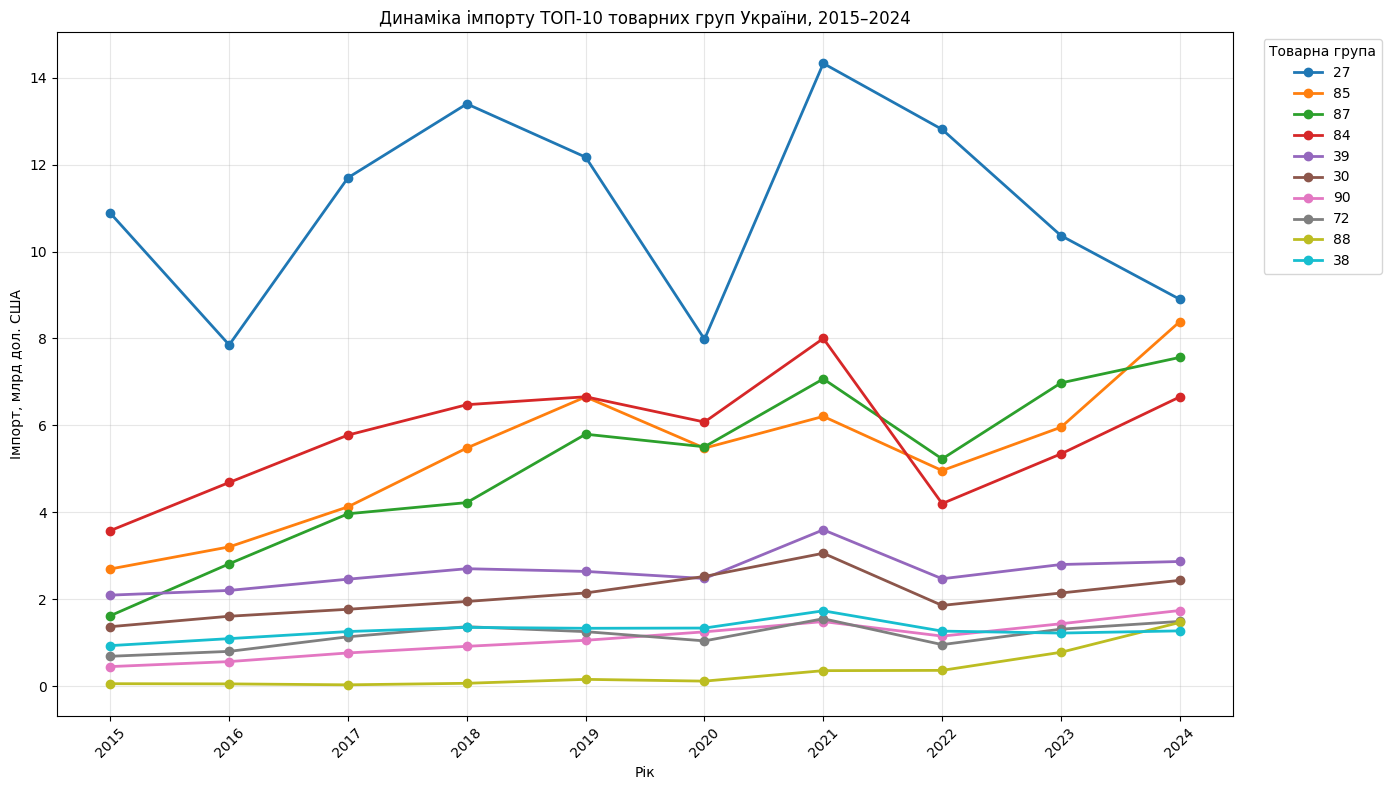

In [173]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

for _, row in selected_groups_table.iterrows():
    group_name = row['Товарна група'].split(' ', 2)[1]
    values = row[analysis_years].astype(float) / 1_000_000

    plt.plot(
        analysis_years,
        values,
        marker='o',
        linewidth=2,
        label=group_name
    )

plt.title('Динаміка імпорту ТОП-10 товарних груп України, 2015–2024')
plt.xlabel('Рік')
plt.ylabel('Імпорт, млрд дол. США')
plt.xticks(rotation=45)
plt.legend(title='Товарна група', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

####5.5.4.2. Графік - Теплова карта (Heatmap).

Щоб порівняння було коректним для груп із дуже різними початковими обсягами, нормалізуємо дані: для кожної групи 2015 рік = 100. Наприклад, значення 150 означатиме, що імпорт у відповідному році на 50% більший, ніж у 2015 році.

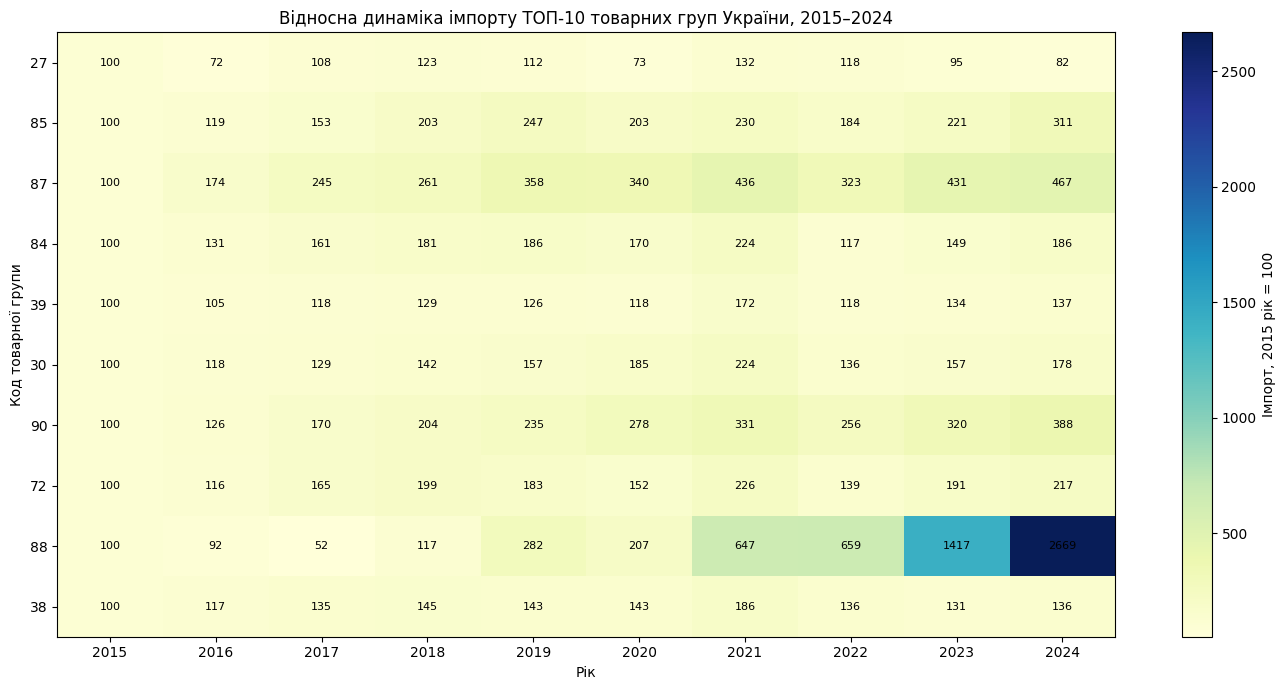

In [174]:
import matplotlib.pyplot as plt
import numpy as np

# Готуємо дані
heatmap_data = (
    selected_groups_table
    .set_index('Товарна група')[analysis_years]
    .astype(float)
)

# Нормалізація: 2015 рік = 100 для кожної групи
heatmap_indexed = heatmap_data.div(heatmap_data['2015'], axis=0) * 100

# Короткі підписи товарних груп
group_labels = heatmap_indexed.index.str.extract(r'Група\s+(\d+)')[0]

plt.figure(figsize=(14, 7))

im = plt.imshow(
    heatmap_indexed.values,
    aspect='auto',
    cmap='YlGnBu'
)

plt.colorbar(im, label='Імпорт, 2015 рік = 100')

plt.xticks(
    range(len(analysis_years)),
    analysis_years
)

plt.yticks(
    range(len(group_labels)),
    group_labels
)

plt.title('Відносна динаміка імпорту ТОП-10 товарних груп України, 2015–2024')
plt.xlabel('Рік')
plt.ylabel('Код товарної групи')

# Додаємо числові значення до клітинок
for i in range(len(heatmap_indexed)):
    for j in range(len(analysis_years)):
        plt.text(
            j, i,
            f'{heatmap_indexed.iloc[i, j]:.0f}',
            ha='center',
            va='center',
            fontsize=8
        )

plt.tight_layout()
plt.show()

### 5.5.5. Висновки: динаміка імпорту ключових товарних груп України

Аналіз десяти найбільших за обсягом імпорту товарних груп у 2024 році за період 2015-2024 років виявив суттєві зміни в структурі імпорту України.

**1. Найбільше абсолютне зростання продемонстрували три товарні групи.**  
Лідерами за приростом вартості імпорту стали транспортні засоби (група 87) - +5,94 млрд дол. США, електричні машини й обладнання (група 85) - +5,69 млрд дол. США, а також механічне обладнання (група 84) — +3,08 млрд дол. США.

**2. Найвищий відносний приріст зафіксовано в групі 88.**  
Імпорт літальних апаратів зріс на 2569,31% порівняно з 2015 роком. Водночас абсолютний приріст становив 1,41 млрд дол. США. Високий відсоток значною мірою пов'язаний із низькою базою порівняння: у 2015 році імпорт цієї групи становив близько 0,05 млрд дол. США.

**3. Зменшилася частка паливної групи в загальному імпорті.**  
Частка групи 27 скоротилася з 29,01% у 2015 році до 12,58% у 2024 році, тобто на 16,43 відсоткового пункта. Попри це, паливна група залишилася найбільшою серед досліджуваних товарних груп за вартістю імпорту у 2024 році — 8,90 млрд дол. США.

**4. Зросла частка окремих машинобудівних і транспортних груп.**  
Найбільше зростання частки в загальному імпорті зафіксовано для транспортних засобів (група 87) - на 6,37 в. п. та електричних машин і обладнання (група 85) — на 4,67 в. п. Також зросли частки літальних апаратів (група 88) і оптичних та медичних приладів (група 90).

**5. 2022 рік став роком найбільшого річного скорочення для більшості досліджуваних груп.**  
Для дев'яти з десяти груп найбільше річне падіння імпорту зафіксовано саме у 2022 році. Найбільше скорочення відбулося в групах механічного обладнання (-47,50%), фармацевтичної продукції (-39,27%) та чорних металів (-38,46%). Винятком стала група 88, для якої найбільше річне скорочення припало на 2017 рік.

**6. Відновлення імпорту відбувалося нерівномірно.**  
У 2024 році чотири з десяти груп досягли максимальних значень за весь досліджуваний період: групи 85, 87, 90 і 88. Для решти шести груп максимальні значення припадали на 2021 рік. Це свідчить про різні траєкторії зміни вартості імпорту залежно від товарної категорії.

**Загальний висновок.**  
У 2015-2024 роках структура імпорту України за досліджуваними товарними групами змінилася: зменшилася частка мінерального палива, натомість зросла роль транспортних засобів та електричного обладнання. Після скорочення 2022 року відновлення імпорту відбувалося неоднаково за різними товарними категоріями. Ці результати характеризують зміни вартості імпорту, але самі по собі не пояснюють їхніх причин.

**Обмеження аналізу.**  
Десять товарних груп відібрано за вартістю імпорту у 2024 році. Дані щодо групи 99 «Різне» за 2024 рік відсутні в офіційному агрегованому значенні, тому охоплення товарної структури за цей рік становить 91,63%. Показники наведено в номінальних доларах США без коригування на інфляцію та зміну цін. Відповідно, результати не слід трактувати як зміну фізичних обсягів імпорту.

## 6.1. Зіставлення загальної динаміки торгівлі з товарною структурою.

### 6.1.1. Формування аналітичної основи

Використовуємо вже підготовлені таблиці:

total_trade_table	- Загальна динаміка імпорту, експорту та торговельного балансу

import_groups_table	- Вартість імпорту за товарними групами

import_share_table - Частка товарних груп у загальному імпорті

### 6.1.2. Порівняння змін загального імпорту та окремих товарних груп

### 6.1.3. Яку частину загального приросту імпорту пояснюють товарні групи?

In [175]:
# Беремо лише групи, для яких є дані за 2015 і 2024 роки
groups_comparison = import_groups_table[
    ['Товарна група', '2015', '2024']
].dropna(subset=['2015', '2024']).copy()

groups_comparison['Зміна, млрд дол. США'] = (
    groups_comparison['2024'].astype(float)
    - groups_comparison['2015'].astype(float)
) / 1_000_000

# Сумарне зростання і скорочення
positive_change = groups_comparison.loc[
    groups_comparison['Зміна, млрд дол. США'] > 0,
    'Зміна, млрд дол. США'
].sum()

negative_change = groups_comparison.loc[
    groups_comparison['Зміна, млрд дол. США'] < 0,
    'Зміна, млрд дол. США'
].sum()

net_change = groups_comparison['Зміна, млрд дол. США'].sum()

# Загальний приріст імпорту
total_import_change = (
    total_trade_table.loc[
        total_trade_table['Рік'] == '2024',
        'Імпорт, млрд дол. США'
    ].iloc[0]
    -
    total_trade_table.loc[
        total_trade_table['Рік'] == '2015',
        'Імпорт, млрд дол. США'
    ].iloc[0]
)

# Приріст трьох найбільших груп
top3_change = groups_comparison.nlargest(
    3, 'Зміна, млрд дол. США'
)['Зміна, млрд дол. США'].sum()

# Підсумкова таблиця
summary_61 = pd.DataFrame({
    'Показник': [
        'Загальний приріст імпорту',
        'Сумарне зростання товарних груп',
        'Сумарне скорочення товарних груп',
        'Чистий приріст товарних груп',
        'Приріст трьох найбільших груп',
        'Частка приросту ТОП-3 у загальному прирості імпорту, %'
    ],
    'Значення': [
        total_import_change,
        positive_change,
        negative_change,
        net_change,
        top3_change,
        top3_change / total_import_change * 100
    ]
})

display(summary_61.round(2))

,Показник,Значення
0,Загальний приріст імпорту,33.25
1,Сумарне зростання товарних груп,30.29
2,Сумарне скорочення товарних груп,-2.94
3,Чистий приріст товарних груп,27.35
4,Приріст трьох найбільших груп,14.71
5,Частка приросту ТОП-3 у загальному прирості ім...,44.24


In [176]:
top3_share_of_net = top3_change / net_change * 100

print(
    f"Частка ТОП-3 у чистому прирості наявних товарних груп: "
    f"{top3_share_of_net:.2f}%"
)

Частка ТОП-3 у чистому прирості наявних товарних груп: 53.79%


**Зв'язок загальної динаміки імпорту з товарною структурою**

У 2015-2024 роках імпорт товарів України зріс із 37,52 до 70,77 млрд дол. США, тобто на 33,25 млрд дол. США. Водночас зростання було нерівномірним за товарними групами.

Серед груп, для яких наявні дані за обидва роки, сумарне збільшення імпорту становило 30,29 млрд дол. США, а скорочення - 2,94 млрд дол. США. Чистий приріст склав 27,35 млрд дол. США.

Найбільше абсолютне збільшення зафіксовано у трьох групах: транспортні засоби (група 87) - на 5,94 млрд дол. США, електричні машини та обладнання (група 85) - на 5,69 млрд дол. США, механічне обладнання (група 84) - на 3,08 млрд дол. США. Разом їхній приріст становив 14,71 млрд дол. США - 44,24% загального приросту імпорту та 53,79% чистого приросту врахованих товарних груп.

Отже, збільшення імпорту супроводжувалося зміною його товарної структури та концентрацією значної частини приросту в окремих групах. Водночас частка десяти найбільших товарних груп у загальному імпорті знизилася з 67,47% у 2015 році до 60,44% у 2024 році. Це свідчить про зменшення концентрації імпорту за цим показником, хоча окремі групи продемонстрували суттєве зростання.

**Обмеження:** розрахунок змін за товарними групами охоплює лише категорії з наявними значеннями за 2015 і 2024 роки. Через пропуски, зокрема в групі 99 «Різне», сума змін не є повною декомпозицією загального приросту імпорту. Відсутні значення не замінювалися нулями.

### 6.1.4 Як змінилася вага окремих товарних груп у загальному імпорті між 2015 і 2024 роками.

In [177]:
# Порівнюємо частки товарних груп у 2015 та 2024 роках
share_comparison = import_share_table[
    ['Товарна група', '2015, %', '2024, %']
].copy()

# Перетворюємо значення на числовий формат
share_comparison['2015, %'] = pd.to_numeric(
    share_comparison['2015, %'], errors='coerce'
)

share_comparison['2024, %'] = pd.to_numeric(
    share_comparison['2024, %'], errors='coerce'
)

# Виключаємо групи без даних хоча б за один із років
share_comparison = share_comparison.dropna(
    subset=['2015, %', '2024, %']
).copy()

# Зміна частки у відсоткових пунктах
share_comparison['Зміна частки, в. п.'] = (
    share_comparison['2024, %'] - share_comparison['2015, %']
)

In [178]:
# Групи з найбільшим зростанням частки
groups_to_compare = ['87', '85', '88', '90']

selected_share = share_comparison[
    share_comparison['Товарна група'].str.contains(
        r'^Група (' + '|'.join(groups_to_compare) + r')\b',
        regex=True
    )
].copy()

# Сукупна частка цих груп у 2015 та 2024 роках
combined_2015 = selected_share['2015, %'].sum()
combined_2024 = selected_share['2024, %'].sum()

combined_share_summary = pd.DataFrame({
    'Показник': [
        'Сукупна частка груп 87, 85, 88, 90 у 2015 році',
        'Сукупна частка груп 87, 85, 88, 90 у 2024 році',
        'Зміна сукупної частки, в. п.'
    ],
    'Значення, %': [
        combined_2015,
        combined_2024,
        combined_2024 - combined_2015
    ]
})

display(combined_share_summary.round(2))

/tmp/ipykernel_14477/3255251290.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  share_comparison['Товарна група'].str.contains(


,Показник,"Значення, %"
0,"Сукупна частка груп 87, 85, 88, 90 у 2015 році",12.84
1,"Сукупна частка груп 87, 85, 88, 90 у 2024 році",27.07
2,"Зміна сукупної частки, в. п.",14.22


**Перерозподіл часток між товарними групами імпорту**

Порівняння товарної структури імпорту України за 2015 і 2024 роки виявило суттєвий перерозподіл часток між окремими категоріями.

Найбільше зросла частка засобів наземного транспорту (група 87) - на 6,37 відсоткового пункта, електричних машин та обладнання (група 85) - на 4,67 в. п., літальних апаратів (група 88) — на 1,92 в. п. та оптичних і медичних приладів (група 90) - на 1,26 в. п.

Сукупна частка цих чотирьох груп збільшилася з 12,85% у 2015 році до 27,07% у 2024 році, тобто більш ніж удвічі.

Найбільше скорочення частки зафіксовано в мінеральному паливі (група 27): з 29,01% до 12,58% (-16,43 в. п.). Також зменшилася частка пластмас і полімерних матеріалів (група 39) - на 1,53 в. п., руд, шлаку та золи (група 26) - на 1,50 в. п.

Отримані результати свідчать про зміну товарних пропорцій імпорту: відносна вага мінерального палива зменшилася, тоді як частка транспортних засобів, електричних машин, літальних апаратів та оптичних і медичних приладів зросла.

Ці зміни описують структуру імпорту у вартісному вираженні. Вони самі по собі не доводять зміну фізичних обсягів споживання, виробничих потреб або причин трансформації попиту.

**Обмеження:** у 2024 році офіційні значення товарних груп покривають 91,63% загального імпорту через відсутність значення групи 99 «Різне». Тому висновки стосуються часток конкретних груп у загальному імпорті, а не повністю відновленої структури всіх товарних категорій.

## 6.2 Зіставлення вартісної динаміки з індексами цін і фізичного обсягу.

In [179]:
# Копії таблиць для порівняння
value_data = total_trade_table.copy()
index_data = trade_indices_table.copy()

# Приводимо роки до єдиного формату
value_data['Рік'] = value_data['Рік'].astype(str)
index_data['Рік'] = index_data['Рік'].astype(str)

# Залишаємо необхідні показники
value_data = value_data[
    ['Рік', 'Експорт, млрд дол. США', 'Імпорт, млрд дол. США']
].copy()

# Об'єднуємо вартісні показники та індекси
comparison_62 = value_data.merge(
    index_data,
    on='Рік',
    how='inner'
)

# Сортуємо за роком
comparison_62 = comparison_62.sort_values('Рік').reset_index(drop=True)

# Розраховуємо річну зміну вартості експорту та імпорту
comparison_62['Зміна вартості експорту, %'] = (
    comparison_62['Експорт, млрд дол. США'].pct_change() * 100
)

comparison_62['Зміна вартості імпорту, %'] = (
    comparison_62['Імпорт, млрд дол. США'].pct_change() * 100
)

# Формуємо таблицю для аналізу
comparison_62 = comparison_62[
    [
        'Рік',
        'Зміна вартості експорту, %',
        'Індекси середніх цін в експорті товарів',
        'Індекси фізичного обсягу в експорті товарів',
        'Зміна вартості імпорту, %',
        'Індекси середніх цін в імпорті товарів',
        'Індекси фізичного обсягу в імпорті товарів'
    ]
]

display(comparison_62.round(2))

Показник,Рік,"Зміна вартості експорту, %",Індекси середніх цін в експорті товарів,Індекси фізичного обсягу в експорті товарів,"Зміна вартості імпорту, %",Індекси середніх цін в імпорті товарів,Індекси фізичного обсягу в імпорті товарів
0,2015,NaN,82.3,86.0,NaN,89.8,76.7
1,2016,-4.63,96.2,99.1,4.62,96.4,108.6
2,2017,18.98,115.9,102.7,26.39,114.0,110.9
3,2018,9.41,111.8,97.9,15.28,112.3,102.6
4,2019,5.75,100.1,105.7,6.32,100.2,106.1
5,2020,-1.72,104.6,94.0,-10.63,99.6,89.4
6,2021,38.38,148.2,93.4,34.06,124.6,107.6
7,2022,-35.16,108.2,59.9,-24.09,137.3,55.3
8,2023,-14.84,86.1,95.2,15.31,107.7,106.7
9,2024,11.04,100.8,114.5,10.99,105.7,105.3


In [180]:
# Індекси за 2022–2024 роки для порівняння з 2021 роком
index_columns = [
    'Індекси середніх цін в експорті товарів',
    'Індекси фізичного обсягу в експорті товарів',
    'Індекси середніх цін в імпорті товарів',
    'Індекси фізичного обсягу в імпорті товарів'
]

period_indices = comparison_62[
    comparison_62['Рік'].isin(['2022', '2023', '2024'])
]

cumulative_indices = period_indices[index_columns].prod() / 100**2

# Грошові значення беремо з початкової таблиці
value_2021 = total_trade_table[
    total_trade_table['Рік'] == '2021'
].iloc[0]

value_2024 = total_trade_table[
    total_trade_table['Рік'] == '2024'
].iloc[0]

export_value_change = (
    value_2024['Експорт, млрд дол. США'] /
    value_2021['Експорт, млрд дол. США'] - 1
) * 100

import_value_change = (
    value_2024['Імпорт, млрд дол. США'] /
    value_2021['Імпорт, млрд дол. США'] - 1
) * 100

recovery_summary = pd.DataFrame({
    'Показник': [
        'Зміна вартості експорту, %',
        'Зміна фізичного обсягу експорту, %',
        'Зміна середніх цін експорту, %',
        'Зміна вартості імпорту, %',
        'Зміна фізичного обсягу імпорту, %',
        'Зміна середніх цін імпорту, %'
    ],
    'Результат, %': [
        export_value_change,
        cumulative_indices[index_columns[1]] - 100,
        cumulative_indices[index_columns[0]] - 100,
        import_value_change,
        cumulative_indices[index_columns[3]] - 100,
        cumulative_indices[index_columns[2]] - 100
    ]
})

recovery_summary['Результат, %'] = recovery_summary['Результат, %'].round(2)

recovery_summary

,Показник,"Результат, %"
0,"Зміна вартості експорту, %",-38.69
1,"Зміна фізичного обсягу експорту, %",-34.71
2,"Зміна середніх цін експорту, %",-6.09
3,"Зміна вартості імпорту, %",-2.85
4,"Зміна фізичного обсягу імпорту, %",-37.87
5,"Зміна середніх цін імпорту, %",56.30


**Порівняння вартісної динаміки торгівлі з індексами цін і фізичного обсягу**

Порівняння вартості експорту й імпорту з індексами середніх цін та фізичного обсягу показує, що зміни зовнішньої торгівлі України у 2015-2024 роках не можна пояснювати лише зростанням або скороченням кількості товарів.

У 2021 році вартість експорту зросла на 38,38% порівняно з попереднім роком, хоча індекс фізичного обсягу становив 93,4%, тобто фізичний обсяг скоротився на 6,6%. Водночас індекс середніх цін експорту досяг 148,2%. Вартість імпорту за цей рік зросла на 34,06%, фізичний обсяг - на 7,6%, а індекс середніх цін становив 124,6%.

У 2022 році відбулося різке скорочення фізичних обсягів: на 40,1% в експорті та на 44,7% в імпорті. Вартість експорту зменшилася на 35,16%, імпорту - на 24,09%. При цьому індекси середніх цін залишалися вище 100%: 108,2% для експорту та 137,3% для імпорту.

У 2023-2024 роках спостерігалося відновлення фізичних обсягів торгівлі. У 2024 році порівняно з попереднім роком фізичний обсяг експорту зріс на 14,5%, імпорту - на 5,3%. Вартість обох потоків збільшилася приблизно на 11%.

Однак порівняння 2024 року з 2021 роком демонструє, що відновлення залишалося неповним. Вартість експорту була нижчою на 38,69%, фізичний обсяг — на 34,71%. Для імпорту відповідні зміни становили -2,85% та -37,87%. Водночас індекс середніх цін імпорту за цей період зріс на 56,30%.

Отже, майже відновлена вартість імпорту у 2024 році порівняно з 2021 роком супроводжувалася значно нижчим фізичним обсягом і вищим індексом середніх цін. Це свідчить про те, що динаміка вартості імпорту та фізичного обсягу суттєво відрізнялася. Для експорту відставання за вартістю та фізичним обсягом було значно більшим.

**Обмеження інтерпретації:** індекси середніх цін не є індексами цін незмінного кошика товарів і можуть залежати від зміни товарної структури. Тому їх не слід механічно використовувати для точного розкладання зміни вартості на цінову та кількісну складові. Порівняння характеризує динаміку показників, але саме по собі не встановлює причин змін.

## 6.3. Зіставлення географічної та товарної структури імпорту

### 6.3.1. Таблиця імпорту за країнами та товарними групами

In [181]:
# Річний імпорт за товарними групами та країнами
group_country_import = trade_data[
    (trade_data['Показник'] == 'Імпорт товарів') &
    (trade_data['Періодичність'] == 'Річна') &
    (trade_data['Категорія розрізу'] == 'Товари за країнами') &
    (trade_data['Угруповання товарів'] == 'Групи')
].copy()

print("Розмір таблиці:", group_country_import.shape)
print("Кількість товарних груп:", group_country_import['Товар'].nunique())
print("Кількість країн:", group_country_import['Країна контрагент'].nunique())

display(
    group_country_import[
        ['Товар', 'Країна контрагент', '2015', '2024']
    ].head(10)
)

Розмір таблиці: (11573, 401)
Кількість товарних груп: 98
Кількість країн: 250


,Товар,Країна контрагент,2015,2024
11649,Група 01 Живі тварини,Камерун,NaN,NaN
11652,Група 01 Живі тварини,Австрія,440.5,955.8
11653,Група 01 Живі тварини,Республіка Корея,NaN,NaN
11654,Група 01 Живі тварини,Італія,1.6,NaN
11656,Група 01 Живі тварини,Ірландія,NaN,84.7
11658,Група 01 Живі тварини,Білорусь,NaN,NaN
11660,Група 01 Живі тварини,Іспанія,72.3,42.0
11662,Група 01 Живі тварини,Бельгія,1.3,90.1
11664,Група 01 Живі тварини,Мадагаскар,21.8,NaN
11667,Група 01 Живі тварини,Австралія,0.9,NaN


In [182]:
# Назви 10 товарних груп із попереднього аналізу
selected_group_names = selected_groups_table['Товарна група'].tolist()

# Відбір країн-постачальників для вибраних груп
selected_group_countries = group_country_import[
    group_country_import['Товар'].isin(selected_group_names)
][
    ['Товар', 'Країна контрагент', '2015', '2024']
].copy()

print("Розмір таблиці:", selected_group_countries.shape)
print("Кількість товарних груп:", selected_group_countries['Товар'].nunique())
print("Кількість країн:", selected_group_countries['Країна контрагент'].nunique())

display(selected_group_countries.head(15))

Розмір таблиці: (1695, 4)
Кількість товарних груп: 10
Кількість країн: 242


,Товар,Країна контрагент,2015,2024
14853,Група 27 Палива мінеральні; нафта і продукти ї...,Бурунді,NaN,NaN
14854,Група 27 Палива мінеральні; нафта і продукти ї...,Албанія,22.1,157.2
14859,Група 27 Палива мінеральні; нафта і продукти ї...,Антигуа і Барбуда,NaN,NaN
14864,Група 27 Палива мінеральні; нафта і продукти ї...,Афганістан,NaN,NaN
14874,Група 27 Палива мінеральні; нафта і продукти ї...,Австралія,122502.1,99243.5
14883,Група 27 Палива мінеральні; нафта і продукти ї...,Аргентина,NaN,42.1
14896,Група 27 Палива мінеральні; нафта і продукти ї...,Бельгія,17439.2,81797.3
14905,Група 27 Палива мінеральні; нафта і продукти ї...,Об'єднані Арабські Емірати,23.7,70184.2
14929,Група 27 Палива мінеральні; нафта і продукти ї...,Аруба,NaN,NaN
14931,Група 27 Палива мінеральні; нафта і продукти ї...,Вірменія,NaN,NaN


In [183]:
# Виключаємо агреговані географічні категорії
group_country_import_clean = group_country_import[
    ~group_country_import['Країна контрагент'].isin(['Усього', 'Країни ЄС'])
].copy()

# Перераховуємо суми за країнами для 10 вибраних груп
selected_group_countries_clean = group_country_import_clean[
    group_country_import_clean['Товар'].isin(selected_group_names)
].copy()

country_sums_clean = (
    selected_group_countries_clean
    .groupby('Товар')[['2015', '2024']]
    .sum(min_count=1)
    .reset_index()
)

coverage_check_clean = country_sums_clean.merge(
    selected_groups_table[['Товарна група', '2015', '2024']],
    left_on='Товар',
    right_on='Товарна група',
    suffixes=('_країни', '_офіційно')
)

for year in ['2015', '2024']:
    coverage_check_clean[f'Покриття {year}, %'] = (
        coverage_check_clean[f'{year}_країни']
        / coverage_check_clean[f'{year}_офіційно'] * 100
    )

display(coverage_check_clean)

,Товар,2015_країни,2024_країни,Товарна група,2015_офіційно,2024_офіційно,"Покриття 2015, %","Покриття 2024, %"
0,Група 27 Палива мінеральні; нафта і продукти ї...,10882445.6,8901721.9,Група 27 Палива мінеральні; нафта і продукти ї...,10882445.7,8901722.2,99.999999,99.999997
1,Група 30 Фармацевтична продукція,1367034.3,2433212.9,Група 30 Фармацевтична продукція,1367034.5,2433212.8,99.999985,100.000004
2,Група 38 Різноманітна хімічна продукція,931067.1,1270637.3,Група 38 Різноманітна хімічна продукція,931067.2,1270637.0,99.999989,100.000024
3,"Група 39 Пластмаси, полімерні матеріали та вир...",2092969.9,2866974.8,"Група 39 Пластмаси, полімерні матеріали та вир...",2092970.4,2866975.2,99.999976,99.999986
4,Група 72 Чорні метали,685738.9,1487960.2,Група 72 Чорні метали,685739.3,1487960.1,99.999942,100.000007
5,"Група 84 Реактори ядерні, котли, машини, облад...",3578210.8,6654473.5,"Група 84 Реактори ядерні, котли, машини, облад...",3578210.7,6654472.9,100.000003,100.000009
6,"Група 85 Електричні машини, обладнання та їх ч...",2695169.3,8386870.0,"Група 85 Електричні машини, обладнання та їх ч...",2695169.2,8386870.2,100.000004,99.999998
7,"Група 87 Засоби наземного транспорту, крім зал...",1619874.1,7563977.6,"Група 87 Засоби наземного транспорту, крім зал...",1619874.4,7563977.7,99.999981,99.999999
8,"Група 88 Літальні апарати, космічні апарати та...",54859.7,1464382.7,"Група 88 Літальні апарати, космічні апарати та...",54859.9,1464382.6,99.999635,100.000007
9,"Група 90 Прилади та апарати оптичні, фотографі...",448502.7,1739237.3,"Група 90 Прилади та апарати оптичні, фотографі...",448503.0,1739237.6,99.999933,99.999983


In [184]:
# ТОП-5 країн-постачальників за кожною товарною групою у 2024 році

top5_suppliers_2024 = (
    selected_group_countries_clean[
        ~selected_group_countries_clean['Країна контрагент'].isin(['Інше'])
    ]
    .sort_values(['Товар', '2024'], ascending=[True, False])
    .groupby('Товар')
    .head(5)
    [['Товар', 'Країна контрагент', '2024']]
    .copy()
)

top5_suppliers_2024['Імпорт, млрд дол. США'] = (
    top5_suppliers_2024['2024'] / 1_000_000
)

In [185]:
# Додаємо офіційні загальні обсяги імпорту товарних груп
supplier_shares = top5_suppliers_2024.merge(
    selected_groups_table[['Товарна група', '2024']],
    left_on='Товар',
    right_on='Товарна група'
)

# Розраховуємо частку кожної країни в імпорті відповідної групи
supplier_shares['Частка країни, %'] = (
    supplier_shares['2024_x'] / supplier_shares['2024_y'] * 100
)

# Підсумовуємо частки ТОП-3 і ТОП-5 постачальників
supplier_concentration = (
    supplier_shares
    .groupby('Товар')
    .agg(
        ТОП_3=('Частка країни, %', lambda x: x.head(3).sum()),
        ТОП_5=('Частка країни, %', 'sum')
    )
    .reset_index()
)

supplier_concentration = supplier_concentration.rename(
    columns={
        'ТОП_3': 'Частка ТОП-3, %',
        'ТОП_5': 'Частка ТОП-5, %'
    }
)

display(
    supplier_shares[
        ['Товар', 'Країна контрагент', 'Імпорт, млрд дол. США', 'Частка країни, %']
    ].round(2)
)

display(supplier_concentration.round(2))

,Товар,Країна контрагент,"Імпорт, млрд дол. США","Частка країни, %"
0,Група 27 Палива мінеральні; нафта і продукти ї...,Польща,1.44,16.14
1,Група 27 Палива мінеральні; нафта і продукти ї...,Греція,1.40,15.70
2,Група 27 Палива мінеральні; нафта і продукти ї...,Литва,0.79,8.90
3,Група 27 Палива мінеральні; нафта і продукти ї...,Румунія,0.63,7.04
4,Група 27 Палива мінеральні; нафта і продукти ї...,Туреччина,0.60,6.78
5,Група 30 Фармацевтична продукція,Німеччина,0.46,19.09
6,Група 30 Фармацевтична продукція,Індія,0.20,8.24
7,Група 30 Фармацевтична продукція,Франція,0.19,7.74
8,Група 30 Фармацевтична продукція,Італія,0.16,6.70
9,Група 30 Фармацевтична продукція,Ірландія,0.12,4.91


,Товар,"Частка ТОП-3, %","Частка ТОП-5, %"
0,Група 27 Палива мінеральні; нафта і продукти ї...,40.74,54.55
1,Група 30 Фармацевтична продукція,35.07,46.69
2,Група 38 Різноманітна хімічна продукція,54.54,65.51
3,"Група 39 Пластмаси, полімерні матеріали та вир...",43.77,56.00
4,Група 72 Чорні метали,60.06,71.23
5,"Група 84 Реактори ядерні, котли, машини, облад...",51.40,64.32
6,"Група 85 Електричні машини, обладнання та їх ч...",62.77,70.13
7,"Група 87 Засоби наземного транспорту, крім зал...",42.53,57.43
8,"Група 88 Літальні апарати, космічні апарати та...",92.36,97.27
9,"Група 90 Прилади та апарати оптичні, фотографі...",47.30,58.23


In [186]:
# Розрахунок концентрації постачальників у 2015 та 2024 роках

concentration_results = []

for year in ['2015', '2024']:
    for group in selected_group_names:

        group_data = selected_group_countries_clean[
            (selected_group_countries_clean['Товар'] == group) &
            (~selected_group_countries_clean['Країна контрагент'].isin(['Інше']))
        ].dropna(subset=[year]).sort_values(year, ascending=False)

        official_total = selected_groups_table.loc[
            selected_groups_table['Товарна група'] == group, year
        ].iloc[0]

        top3_share = group_data.head(3)[year].sum() / official_total * 100
        top5_share = group_data.head(5)[year].sum() / official_total * 100

        concentration_results.append({
            'Рік': year,
            'Товарна група': group,
            'Частка ТОП-3, %': top3_share,
            'Частка ТОП-5, %': top5_share
        })

concentration_comparison = pd.DataFrame(concentration_results)

concentration_comparison_pivot = concentration_comparison.pivot(
    index='Товарна група',
    columns='Рік',
    values=['Частка ТОП-3, %', 'Частка ТОП-5, %']
)

concentration_comparison_pivot['Зміна ТОП-3, в.п.'] = (
    concentration_comparison_pivot[('Частка ТОП-3, %', '2024')]
    - concentration_comparison_pivot[('Частка ТОП-3, %', '2015')]
)

concentration_comparison_pivot['Зміна ТОП-5, в.п.'] = (
    concentration_comparison_pivot[('Частка ТОП-5, %', '2024')]
    - concentration_comparison_pivot[('Частка ТОП-5, %', '2015')]
)

display(concentration_comparison_pivot.round(2))

Частка ТОП-3, %         \
Рік                                                           2015   2024   
Товарна група                                                               
Група 27 Палива мінеральні; нафта і продукти її...           59.79  40.74   
Група 30 Фармацевтична продукція                             34.20  35.07   
Група 38 Різноманітна хімічна продукція                      51.09  54.54   
Група 39 Пластмаси, полімерні матеріали та виро...           38.06  43.77   
Група 72 Чорні метали                                        56.93  60.06   
Група 84 Реактори ядерні, котли, машини, обладн...           53.54  51.40   
Група 85 Електричні машини, обладнання та їх ча...           50.58  62.77   
Група 87 Засоби наземного транспорту, крім залі...           42.79  42.53   
Група 88 Літальні апарати, космічні апарати та ...           64.30  92.36   
Група 90 Прилади та апарати оптичні, фотографіч...           44.27  47.30   

                                                   Частка ТОП-5, %         \
Рік                                                           2015   2024   
Товарна група                                                               
Група 27 Палива мінеральні; нафта і продукти її...           73.76  54.55   
Група 30 Фармацевтична продукція                             45.12  46.69   
Група 38 Різноманітна хімічна продукція                      64.28  65.51   
Група 39 Пластмаси, полімерні матеріали та виро...           53.01  56.00   
Група 72 Чорні метали                                        69.32  71.23   
Група 84 Реактори ядерні, котли, машини, обладн...           66.22  64.32   
Група 85 Електричні машини, обладнання та їх ча...           63.73  70.13   
Група 87 Засоби наземного транспорту, крім залі...           54.34  57.43   
Група 88 Літальні апарати, космічні апарати та ...           83.34  97.27   
Група 90 Прилади та апарати оптичні, фотографіч...           54.72  58.23   

                                                   Зміна ТОП-3, в.п.  \
Рік                                                                    
Товарна група                                                          
Група 27 Палива мінеральні; нафта і продукти її...            -19.06   
Група 30 Фармацевтична продукція                                0.88   
Група 38 Різноманітна хімічна продукція                         3.45   
Група 39 Пластмаси, полімерні матеріали та виро...              5.72   
Група 72 Чорні метали                                           3.14   
Група 84 Реактори ядерні, котли, машини, обладн...             -2.14   
Група 85 Електричні машини, обладнання та їх ча...             12.19   
Група 87 Засоби наземного транспорту, крім залі...             -0.26   
Група 88 Літальні апарати, космічні апарати та ...             28.06   
Група 90 Прилади та апарати оптичні, фотографіч...              3.03   

                                                   Зміна ТОП-5, в.п.  
Рік                                                                   
Товарна група                                                         
Група 27 Палива мінеральні; нафта і продукти її...            -19.20  
Група 30 Фармацевтична продукція                                1.57  
Група 38 Різноманітна хімічна продукція                         1.23  
Група 39 Пластмаси, полімерні матеріали та виро...              2.98  
Група 72 Чорні метали                                           1.91  
Група 84 Реактори ядерні, котли, машини, обладн...             -1.90  
Група 85 Електричні машини, обладнання та їх ча...              6.40  
Група 87 Засоби наземного транспорту, крім залі...              3.09  
Група 88 Літальні апарати, космічні апарати та ...             13.92  
Група 90 Прилади та апарати оптичні, фотографіч...              3.51

In [187]:
# Порівняння ТОП-3 країн-постачальників у 2015 та 2024 роках

top3_country_comparison = []

for group in selected_group_names:
    for year in ['2015', '2024']:

        group_data = selected_group_countries_clean[
            (selected_group_countries_clean['Товар'] == group) &
            (~selected_group_countries_clean['Країна контрагент'].isin(['Інше']))
        ].dropna(subset=[year]).sort_values(year, ascending=False)

        official_total = selected_groups_table.loc[
            selected_groups_table['Товарна група'] == group, year
        ].iloc[0]

        top3 = group_data.head(3)

        suppliers = [
            f"{row['Країна контрагент']} "
            f"({row[year] / 1_000_000:.2f} млрд дол.; "
            f"{row[year] / official_total * 100:.1f}%)"
            for _, row in top3.iterrows()
        ]

        top3_country_comparison.append({
            'Товарна група': group,
            'Рік': year,
            'ТОП-3 постачальників': '; '.join(suppliers)
        })

top3_country_comparison = pd.DataFrame(top3_country_comparison)

display(top3_country_comparison)

,Товарна група,Рік,ТОП-3 постачальників
0,Група 27 Палива мінеральні; нафта і продукти ї...,2015,Російська Федерація (3.71 млрд дол.; 34.1%); Б...
1,Група 27 Палива мінеральні; нафта і продукти ї...,2024,Польща (1.44 млрд дол.; 16.1%); Греція (1.40 м...
2,"Група 85 Електричні машини, обладнання та їх ч...",2015,Китай (0.87 млрд дол.; 32.1%); Німеччина (0.27...
3,"Група 85 Електричні машини, обладнання та їх ч...",2024,Китай (4.57 млрд дол.; 54.5%); Польща (0.37 мл...
4,"Група 87 Засоби наземного транспорту, крім зал...",2015,Німеччина (0.32 млрд дол.; 19.6%); США (0.20 м...
5,"Група 87 Засоби наземного транспорту, крім зал...",2024,Німеччина (1.12 млрд дол.; 14.8%); США (1.09 м...
6,"Група 84 Реактори ядерні, котли, машини, облад...",2015,Російська Федерація (0.80 млрд дол.; 22.4%); К...
7,"Група 84 Реактори ядерні, котли, машини, облад...",2024,Китай (2.02 млрд дол.; 30.3%); Німеччина (0.95...
8,"Група 39 Пластмаси, полімерні матеріали та вир...",2015,Російська Федерація (0.29 млрд дол.; 13.8%); Н...
9,"Група 39 Пластмаси, полімерні матеріали та вир...",2024,Китай (0.51 млрд дол.; 17.6%); Польща (0.48 мл...


In [188]:
# Порівняння складу ТОП-3 постачальників

supplier_changes = []

for group in selected_group_names:
    top_countries = {}

    for year in ['2015', '2024']:
        group_data = selected_group_countries_clean[
            (selected_group_countries_clean['Товар'] == group) &
            (~selected_group_countries_clean['Країна контрагент'].isin(['Інше']))
        ].dropna(subset=[year]).sort_values(year, ascending=False)

        top_countries[year] = set(
            group_data.head(3)['Країна контрагент']
        )

    common = top_countries['2015'] & top_countries['2024']
    exited = top_countries['2015'] - top_countries['2024']
    entered = top_countries['2024'] - top_countries['2015']

    supplier_changes.append({
        'Товарна група': group,
        'Спільні країни ТОП-3': ', '.join(sorted(common)) if common else 'Немає',
        'Вибули з ТОП-3': ', '.join(sorted(exited)) if exited else 'Немає',
        'Увійшли до ТОП-3': ', '.join(sorted(entered)) if entered else 'Немає',
        'Кількість спільних країн': len(common)
    })

supplier_changes_table = pd.DataFrame(supplier_changes)

display(supplier_changes_table)

,Товарна група,Спільні країни ТОП-3,Вибули з ТОП-3,Увійшли до ТОП-3,Кількість спільних країн
0,Група 27 Палива мінеральні; нафта і продукти ї...,Немає,"Білорусь, Німеччина, Російська Федерація","Греція, Литва, Польща",0
1,"Група 85 Електричні машини, обладнання та їх ч...","Китай, Польща",Німеччина,Угорщина,2
2,"Група 87 Засоби наземного транспорту, крім зал...","Німеччина, США",Японія,Китай,2
3,"Група 84 Реактори ядерні, котли, машини, облад...","Китай, Німеччина",Російська Федерація,Польща,2
4,"Група 39 Пластмаси, полімерні матеріали та вир...","Китай, Німеччина",Російська Федерація,Польща,2
5,Група 30 Фармацевтична продукція,"Індія, Німеччина, Франція",Немає,Немає,3
6,"Група 90 Прилади та апарати оптичні, фотографі...","Китай, Німеччина, США",Немає,Немає,3
7,Група 72 Чорні метали,"Китай, Польща",Російська Федерація,Туреччина,2
8,"Група 88 Літальні апарати, космічні апарати та...",Польща,"Білорусь, Російська Федерація","Китай, Німеччина",1
9,Група 38 Різноманітна хімічна продукція,"Китай, Німеччина, Франція",Немає,Немає,3


**Зміни географії постачання за основними товарними групами**

Порівняння географії імпорту десяти найбільших товарних груп за 2015 та 2024 роки показало суттєві зміни у складі основних країн-постачальників. Найпомітніші зміни відбулися у групі мінерального палива: жодна з трьох провідних країн 2015 року - Російська Федерація, Білорусь і Німеччина - не залишилася в ТОП-3 у 2024 році. Їх замінили Польща, Греція та Литва.

Змінилася географія постачання й у низці інших груп. Російська Федерація вибула з трійки провідних постачальників механічного обладнання, пластмас і чорних металів. Натомість у відповідних групах до ТОП-3 увійшли Польща та Туреччина. У групі електричних машин зросла роль Китаю: його частка досягла 54,52% імпорту групи у 2024 році проти 32,1% у 2015 році.

Найвища концентрація постачання у 2024 році зафіксована у групі літальних апаратів: на Китай припадало 81,49% імпорту, а на три провідні країни - 92,36%. Водночас у групі фармацевтичної продукції склад ТОП-3 постачальників залишився незмінним: Німеччина, Індія та Франція.

Отже, географічна структура імпорту змінювалася залежно від товарної групи: в одних випадках відбулася повна заміна провідних постачальників, в інших - збереглося ядро основних країн, але змінилися їхні частки. Ці дані дають змогу оцінити концентрацію імпорту за країнами, однак самі по собі не доводять наявності критичної залежності чи ризику перебоїв постачання.

## 6.4 Визначення найважливіших змін у зовнішній торгівлі України за 2015-2024 роки

In [189]:
# Зведення ключових змін зовнішньої торгівлі України за 2015–2024 роки
# Усі числові показники отримуються з попередніх робочих таблиць.

# Допоміжні функції

def get_trade_value(year, column):
    """Отримання показника загальної торгівлі."""
    return float(
        total_trade_table.loc[
            total_trade_table['Рік'] == year, column
        ].iloc[0]
    )


def get_group_share(group_code, year):
    """Частка товарної групи в загальному імпорті."""
    row = import_groups_table.loc[
        import_groups_table['Товарна група'].str.startswith(
            f'Група {group_code}', na=False
        )
    ]

    if row.empty or pd.isna(row.iloc[0][year]):
        return None

    group_value = float(row.iloc[0][year])
    total_import = get_trade_value(
        year, 'Імпорт, тис. дол. США'
    )

    return group_value / total_import * 100


def get_supplier_share(group_code, country, year):
    """Частка країни в імпорті конкретної товарної групи."""

    group_row = selected_groups_table.loc[
        selected_groups_table['Товарна група'].str.startswith(
            f'Група {group_code}', na=False
        )
    ]

    if group_row.empty:
        return None

    group_name = group_row.iloc[0]['Товарна група']
    official_total = group_row.iloc[0][year]

    country_row = selected_group_countries_clean.loc[
        (selected_group_countries_clean['Товар'] == group_name) &
        (selected_group_countries_clean['Країна контрагент'] == country)
    ]

    if country_row.empty or pd.isna(official_total):
        return None

    country_value = country_row.iloc[0][year]

    if pd.isna(country_value):
        return None

    return float(country_value) / float(official_total) * 100


def get_table_value(table, year, year_column, value_column):
    """Отримання показника з таблиці за відповідний рік."""
    return float(
        table.loc[
            table[year_column] == year, value_column
        ].iloc[0]
    )


# 1. Загальна динаміка експорту та імпорту

export_2015 = get_trade_value(
    '2015', 'Експорт, тис. дол. США'
) / 1_000_000

export_2024 = get_trade_value(
    '2024', 'Експорт, тис. дол. США'
) / 1_000_000

import_2015 = get_trade_value(
    '2015', 'Імпорт, тис. дол. США'
) / 1_000_000

import_2024 = get_trade_value(
    '2024', 'Імпорт, тис. дол. США'
) / 1_000_000


# 2. Частки товарних груп

group_27_2015 = get_group_share('27', '2015')
group_27_2024 = get_group_share('27', '2024')

group_87_2015 = get_group_share('87', '2015')
group_87_2024 = get_group_share('87', '2024')

group_85_2015 = get_group_share('85', '2015')
group_85_2024 = get_group_share('85', '2024')


# 3. Фізичні обсяги

export_volume_2024 = get_table_value(
    recovery_comparison,
    'Фізичний обсяг експорту',
    'Показник',
    'Рівень 2024 до 2021, %'
)

import_volume_2024 = get_table_value(
    recovery_comparison,
    'Фізичний обсяг імпорту',
    'Показник',
    'Рівень 2024 до 2021, %'
)


# 4. Географія імпорту

top10_countries_2015 = get_table_value(
    country_concentration_by_year,
    '2015',
    'Рік',
    'ТОП-10, %'
)

top10_countries_2024 = get_table_value(
    country_concentration_by_year,
    '2024',
    'Рік',
    'ТОП-10, %'
)

eu_share_2015 = get_table_value(
    eu_import_table,
    '2015',
    'Рік',
    'Частка ЄС у загальному імпорті, %'
)

eu_share_2024 = get_table_value(
    eu_import_table,
    '2024',
    'Рік',
    'Частка ЄС у загальному імпорті, %'
)


# 5. Частки Китаю в окремих товарних групах

china_group_85_2015 = get_supplier_share(
    '85', 'Китай', '2015'
)

china_group_85_2024 = get_supplier_share(
    '85', 'Китай', '2024'
)

china_group_88_2015 = get_supplier_share(
    '88', 'Китай', '2015'
)

china_group_88_2024 = get_supplier_share(
    '88', 'Китай', '2024'
)


# 6. Формування зведеної таблиці

key_changes = pd.DataFrame([
    {
        'Напрям': 'Загальна торгівля',
        'Показник': 'Обсяг експорту',
        '2015': export_2015,
        '2024': export_2024,
        'Зміна': (export_2024 / export_2015 - 1) * 100,
        'Одиниця зміни': '%',
        'Аналітичне значення': 'Динаміка вартості експорту'
    },
    {
        'Напрям': 'Загальна торгівля',
        'Показник': 'Обсяг імпорту',
        '2015': import_2015,
        '2024': import_2024,
        'Зміна': (import_2024 / import_2015 - 1) * 100,
        'Одиниця зміни': '%',
        'Аналітичне значення': 'Динаміка вартості імпорту'
    },
    {
        'Напрям': 'Товарна структура',
        'Показник': 'Частка групи 27 — мінеральне паливо',
        '2015': group_27_2015,
        '2024': group_27_2024,
        'Зміна': group_27_2024 - group_27_2015,
        'Одиниця зміни': 'в. п.',
        'Аналітичне значення': 'Зміна частки мінерального палива'
    },
    {
        'Напрям': 'Товарна структура',
        'Показник': 'Частка групи 87 — транспортні засоби',
        '2015': group_87_2015,
        '2024': group_87_2024,
        'Зміна': group_87_2024 - group_87_2015,
        'Одиниця зміни': 'в. п.',
        'Аналітичне значення': 'Зміна частки транспортних засобів'
    },
    {
        'Напрям': 'Товарна структура',
        'Показник': 'Частка групи 85 — електричні машини',
        '2015': group_85_2015,
        '2024': group_85_2024,
        'Зміна': group_85_2024 - group_85_2015,
        'Одиниця зміни': 'в. п.',
        'Аналітичне значення': 'Зміна частки електричних машин'
    },
    {
        'Напрям': 'Фізичні обсяги',
        'Показник': 'Фізичний обсяг експорту, 2024 до 2021',
        '2015': None,
        '2024': export_volume_2024,
        'Зміна': export_volume_2024 - 100,
        'Одиниця зміни': '% до рівня 2021 року',
        'Аналітичне значення': 'Співвідношення фізичного обсягу експорту з рівнем 2021 року'
    },
    {
        'Напрям': 'Фізичні обсяги',
        'Показник': 'Фізичний обсяг імпорту, 2024 до 2021',
        '2015': None,
        '2024': import_volume_2024,
        'Зміна': import_volume_2024 - 100,
        'Одиниця зміни': '% до рівня 2021 року',
        'Аналітичне значення': 'Співвідношення фізичного обсягу імпорту з рівнем 2021 року'
    },
    {
        'Напрям': 'Географія імпорту',
        'Показник': 'Частка ТОП-10 країн-постачальників',
        '2015': top10_countries_2015,
        '2024': top10_countries_2024,
        'Зміна': top10_countries_2024 - top10_countries_2015,
        'Одиниця зміни': 'в. п.',
        'Аналітичне значення': 'Зміна сукупної частки десяти найбільших постачальників'
    },
    {
        'Напрям': 'Географія імпорту',
        'Показник': 'Частка ЄС у загальному імпорті',
        '2015': eu_share_2015,
        '2024': eu_share_2024,
        'Зміна': eu_share_2024 - eu_share_2015,
        'Одиниця зміни': 'в. п.',
        'Аналітичне значення': 'Зміна частки імпорту з країн ЄС'
    },
    {
        'Напрям': 'Постачальники за товарними групами',
        'Показник': 'Частка Китаю в імпорті групи 85',
        '2015': china_group_85_2015,
        '2024': china_group_85_2024,
        'Зміна': china_group_85_2024 - china_group_85_2015,
        'Одиниця зміни': 'в. п.',
        'Аналітичне значення': 'Зміна частки Китаю в імпорті електричних машин'
    },
    {
        'Напрям': 'Постачальники за товарними групами',
        'Показник': 'Частка Китаю в імпорті групи 88',
        '2015': china_group_88_2015,
        '2024': china_group_88_2024,
        'Зміна': (
            china_group_88_2024 - china_group_88_2015
            if china_group_88_2015 is not None else None
        ),
        'Одиниця зміни': 'в. п.',
        'Аналітичне значення': 'Частка Китаю в імпорті літальних апаратів'
    }
])

display(key_changes.round(2))


,Напрям,Показник,2015,2024,Зміна,Одиниця зміни,Аналітичне значення
0,Загальна торгівля,Обсяг експорту,38.13,41.73,9.46,%,Динаміка вартості експорту
1,Загальна торгівля,Обсяг імпорту,37.52,70.77,88.64,%,Динаміка вартості імпорту
2,Товарна структура,Частка групи 27 — мінеральне паливо,29.01,12.58,-16.43,в. п.,Зміна частки мінерального палива
3,Товарна структура,Частка групи 87 — транспортні засоби,4.32,10.69,6.37,в. п.,Зміна частки транспортних засобів
4,Товарна структура,Частка групи 85 — електричні машини,7.18,11.85,4.67,в. п.,Зміна частки електричних машин
5,Фізичні обсяги,"Фізичний обсяг експорту, 2024 до 2021",NaN,65.29,-34.71,% до рівня 2021 року,Співвідношення фізичного обсягу експорту з рів...
6,Фізичні обсяги,"Фізичний обсяг імпорту, 2024 до 2021",NaN,62.13,-37.87,% до рівня 2021 року,Співвідношення фізичного обсягу імпорту з рівн...
7,Географія імпорту,Частка ТОП-10 країн-постачальників,68.83,64.92,-3.91,в. п.,Зміна сукупної частки десяти найбільших постач...
8,Географія імпорту,Частка ЄС у загальному імпорті,40.86,50.46,9.60,в. п.,Зміна частки імпорту з країн ЄС
9,Постачальники за товарними групами,Частка Китаю в імпорті групи 85,32.13,54.52,22.39,в. п.,Зміна частки Китаю в імпорті електричних машин


**Примітки до таблиці:**
- Значення експорту й імпорту - млрд дол. США.
- Частки - у відсотках; зміни часток - у відсоткових пунктах.
- Для індексів фізичного обсягу значення 65,29% та 62,13% означають співвідношення рівня 2024 року до 2021-го, а не частку в загальному обсязі.
- None означає, що відповідне значення не є предметом цього порівняння.
- Дані товарної структури за 2024 рік мають обмеження: офіційне значення групи 99 «Різне» відсутнє, тому покриття товарної структури становить 91,63%.

In [190]:
# Додаткові показники для визначення ключових змін

trade_2015 = total_trade_table[
    total_trade_table['Рік'] == '2015'
].iloc[0]

trade_2021 = total_trade_table[
    total_trade_table['Рік'] == '2021'
].iloc[0]

trade_2022 = total_trade_table[
    total_trade_table['Рік'] == '2022'
].iloc[0]

trade_2024 = total_trade_table[
    total_trade_table['Рік'] == '2024'
].iloc[0]

indices_2022 = trade_indices_table[
    trade_indices_table['Рік'] == '2022'
].iloc[0]

additional_changes = pd.DataFrame([
    {
        'Показник': 'Торговельний баланс',
        '2015': round(
            trade_2015['Експорт, млрд дол. США'] -
            trade_2015['Імпорт, млрд дол. США'], 2
        ),
        '2024': round(
            trade_2024['Експорт, млрд дол. США'] -
            trade_2024['Імпорт, млрд дол. США'], 2
        ),
        'Одиниця': 'млрд дол. США'
    },
    {
        'Показник': 'Зміна експорту у 2022 році до 2021',
        '2015': None,
        '2024': round(
            (trade_2022['Експорт, млрд дол. США'] /
             trade_2021['Експорт, млрд дол. США'] - 1) * 100, 2
        ),
        'Одиниця': '%'
    },
    {
        'Показник': 'Зміна імпорту у 2022 році до 2021',
        '2015': None,
        '2024': round(
            (trade_2022['Імпорт, млрд дол. США'] /
             trade_2021['Імпорт, млрд дол. США'] - 1) * 100, 2
        ),
        'Одиниця': '%'
    },
    {
        'Показник': 'Індекс фізичного обсягу експорту у 2022',
        '2015': None,
        '2024': indices_2022[
            'Індекси фізичного обсягу в експорті товарів'
        ],
        'Одиниця': '%, до попереднього року'
    },
    {
        'Показник': 'Індекс фізичного обсягу імпорту у 2022',
        '2015': None,
        '2024': indices_2022[
            'Індекси фізичного обсягу в імпорті товарів'
        ],
        'Одиниця': '%, до попереднього року'
    }
])

display(additional_changes)

,Показник,2015,2024,Одиниця
0,Торговельний баланс,0.61,-29.04,млрд дол. США
1,Зміна експорту у 2022 році до 2021,NaN,-35.16,%
2,Зміна імпорту у 2022 році до 2021,NaN,-24.09,%
3,Індекс фізичного обсягу експорту у 2022,NaN,59.90,"%, до попереднього року"
4,Індекс фізичного обсягу імпорту у 2022,NaN,55.30,"%, до попереднього року"


## 6.5. Найважливіші зміни у зовнішній торгівлі України за 2015-2024 роки

Аналіз зовнішньої торгівлі товарами України за 2015-2024 роки виявив п'ять ключових змін.

**1. Поглиблення від'ємного торговельного балансу.**

У 2015 році експорт перевищував імпорт на 0,61 млрд дол. США. У 2024 році імпорт становив 70,77 млрд дол. США, експорт - 41,73 млрд дол. США, а дефіцит торговельного балансу досяг 29,04 млрд дол. США. За цей період вартість імпорту зросла на 88,64%, експорту — на 9,46%.

**2. Неповне відновлення фізичних обсягів торгівлі.**

У 2022 році фізичний обсяг експорту скоротився на 40,1%, імпорту - на 44,7% порівняно з попереднім роком. У 2024 році фізичний обсяг експорту залишався на 34,71%, а імпорту — на 37,87% нижчим за рівень 2021 року.

**3. Перебудова товарної структури імпорту.**

У 2015–2024 роках частка мінерального палива скоротилася з 29,01% до 12,58% (-16,43 відсоткового пункту). Натомість частка транспортних засобів зросла з 4,32% до 10,69% (+6,37 в. п.), електричних машин - з 7,18% до 11,85% (+4,67 в. п.). Сукупна частка транспортних засобів, електричних машин, літальних апаратів та оптичних і медичних приладів збільшилася з 12,85% до 27,07%.

**4. Зміна географії імпорту.**

Частка країн Європейського Союзу в імпорті зросла з 40,86% у 2015 році до 50,46% у 2024 році. У товарній групі мінерального палива змінився склад трьох провідних постачальників: замість Російської Федерації, Білорусі та Німеччини до них увійшли Польща, Греція та Литва.

**5. Різна концентрація постачальників залежно від товарної групи.**

Частка десяти найбільших країн-постачальників у загальному імпорті зменшилася з 68,83% у 2015 році до 64,92% у 2024 році. Водночас в окремих товарних групах концентрація залишалася високою: частка Китаю становила 54,52% імпорту електричних машин і 81,49% імпорту літальних апаратів.

Підсумок. За десятиріччя змінилися співвідношення експорту й імпорту, фізичні обсяги торгівлі, товарна структура та географія постачання. Загальне зниження концентрації постачальників не виключає високої концентрації в окремих товарних категоріях.

Під час інтерпретації товарної структури за 2024 рік необхідно враховувати, що наявні офіційні агреговані товарні групи охоплюють 91,63% загального імпорту через відсутність значення групи 99 «Різне».

## 6.6. Загальні висновки дослідження

Зовнішня торгівля товарами України у 2015-2024 роках зазнала суттєвої структурної трансформації. Найвиразнішими її проявами стали поглиблення дефіциту торговельного балансу, неповне відновлення фізичних обсягів після 2021 року, зміна товарних пропорцій імпорту та переорієнтація частини постачання на країни Європейського Союзу.

Водночас загальні показники приховують відмінності між окремими товарними напрямами: за зниження загальної концентрації країн-постачальників зберігається висока залежність вартості постачання від окремих країн у деяких товарних групах. Це потребує детальнішого вивчення товарної специфіки та можливостей альтернативного постачання.

Отримані результати характеризують динаміку та структуру торгівлі, але не встановлюють причин виявлених змін і не дають змоги самостійно оцінити їхній вплив на внутрішнє виробництво, зайнятість або економічну безпеку країни.

**Межі дослідження.** Аналіз охоплює лише зовнішню торгівлю товарами за 2015-2024 роки. Вартісні показники наведені в номінальних доларах США без коригування на інфляцію. Індекси середніх цін не є індексами цін незмінного набору товарів і можуть залежати від зміни товарної структури.

Покриття товарної структури імпорту за 2024 рік становить 91,63% через відсутність офіційного агрегованого значення групи 99 «Різне». У деталізованих товарних і географічних рядах є пропущені значення; вони не прирівнювалися до нуля. В окремі роки також спостерігаються розбіжності між деталізованими та загальними показниками, причини яких не завжди можна встановити за наявними даними.

Висока концентрація постачальників сама по собі не доводить критичної залежності або ризику перебоїв. Для таких оцінок потрібні додаткові дані про критичність товарів, альтернативних постачальників і можливості заміщення.

## 6.7. Виявлені проблеми та рекомендації щодо поліпшення зовнішньої торгівлі України

Результати аналізу дають підстави виділити чотири напрями, які потребують уваги та додаткового опрацювання.

**1. Дисбаланс між експортом та імпортом**

Проблема: імпорт зростав значно швидше за експорт, унаслідок чого торговельний баланс перейшов від профіциту до значного дефіциту.

***Рекомендації:***

- визначити товарні групи, які формують найбільшу частину дефіциту;

- оцінити експортний потенціал українських виробників за цими напрямами;

- дослідити можливості збільшення експорту продукції з вищою доданою вартістю;

- відокремити імпорт виробничих ресурсів та інвестиційних товарів від інших категорій, щоб не розглядати скорочення імпорту як універсальну мету.

**2. Неповне відновлення фізичних обсягів торгівлі**

Проблема: у 2024 році фізичні обсяги експорту та імпорту залишалися нижчими за рівень 2021 року.

***Рекомендації:***

- регулярно відстежувати фізичні обсяги експорту та імпорту окремо від їхньої номінальної вартості;

- визначити товарні напрями з найбільшим відставанням від рівня 2021 року;

- додатково дослідити виробничі, логістичні та інфраструктурні чинники, які можуть обмежувати відновлення торгівлі.

Наявні дані не дають змоги встановити, які саме чинники визначили це відставання.

**3. Концентрація постачання в окремих товарних групах**

Проблема: у деяких товарних категоріях значна частина вартості імпорту припадає на одного постачальника.

***Рекомендації:***

- визначити критичність товарів із високою концентрацією постачання;

- оцінити наявність альтернативних країн і виробників;

- проаналізувати можливості диверсифікації джерел постачання;

- окремо дослідити ризики залежності від імпортних комплектуючих і технологій.

Першочергової уваги потребують товарні групи, у яких висока концентрація поєднується з критичною важливістю продукції та обмеженою кількістю альтернатив.

**4. Неповнота та розбіжності статистичних даних**

Проблема: відсутність офіційного агрегованого значення групи 99 «Різне» у 2024 році та розбіжності між окремими деталізованими й загальними показниками обмежують повноту порівняння.

***Рекомендації:***

- забезпечувати повноту публікації агрегованих товарних показників;

- пояснювати методологічні причини розбіжностей між загальними та деталізованими даними;

- надавати інформацію про пропущені значення та зміни класифікацій;

- підтримувати зіставність статистичних рядів між роками.

**Підсумок**

Пріоритетними напрямами подальшої роботи мають стати розвиток експортного потенціалу, аналіз можливостей відновлення фізичних обсягів торгівлі, оцінка ризиків концентрації постачання та підвищення повноти офіційної статистики.

Ці рекомендації визначають напрями для подальшого аналізу й розроблення практичних заходів. Для ухвалення конкретних рішень необхідні додаткові дані про внутрішнє виробництво, попит, виробничі потужності, критичність товарів і можливості альтернативного постачання.

## 07. Фінальні таблиці для публікації

У цьому розділі формуються компактні таблиці для перенесення до статті. Вони використовують уже підготовлені вище датафрейми та не змінюють вихідні дані або попередні розрахунки.

**Єдині правила оформлення:**
- вартісні показники — млрд дол. США;
- частки та відносні зміни — %;
- зміни часток — відсоткові пункти (в. п.);
- числові результати для публікації округлюються до двох знаків після коми;
- пропущені значення не замінюються нулями.

Таблиці призначені для статті, а не для повторного аналітичного розрахунку. Для перевірки походження показників збережено посилання на робочі датафрейми у коді.


In [191]:
# 07.1. Формування фінальних таблиць для статті
# Джерело кожного показника — датафрейми, сформовані в попередніх розділах.
# Округлення застосовується лише до копій для відображення.

from IPython.display import display

# ------------------------------------------------------------
# Таблиця 1. Експорт, імпорт і торговельне сальдо
# ------------------------------------------------------------

article_years = ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']

article_table_1 = (
    total_trade_table[
        total_trade_table['Рік'].isin(article_years)
    ][
        ['Рік', 'Експорт, млрд дол. США', 'Імпорт, млрд дол. США']
    ]
    .copy()
)

article_table_1['Торговельне сальдо, млрд дол. США'] = (
    article_table_1['Експорт, млрд дол. США']
    - article_table_1['Імпорт, млрд дол. США']
)

article_table_1 = (
    article_table_1
    .rename(columns={
        'Експорт, млрд дол. США': 'Експорт, млрд дол. США',
        'Імпорт, млрд дол. США': 'Імпорт, млрд дол. США'
    })
    .round(2)
    .reset_index(drop=True)
)

print('Таблиця 1. Експорт, імпорт і торговельне сальдо')
display(article_table_1)


# ------------------------------------------------------------
# Таблиця 2. Зміна часток найбільших товарних груп
# ------------------------------------------------------------

article_table_2 = (
    groups_shares[
        [
            'Товарна група',
            'Частка 2015, %',
            'Частка 2024, %',
            'Зміна частки, в. п.'
        ]
    ]
    .copy()
    .sort_values('Частка 2024, %', ascending=False)
    .rename(columns={
        'Товарна група': 'Товарна група',
        'Частка 2015, %': '2015, %',
        'Частка 2024, %': '2024, %',
        'Зміна частки, в. п.': 'Зміна, в. п.'
    })
    .round(2)
    .reset_index(drop=True)
)

print('Таблиця 2. Частки десяти найбільших товарних груп в імпорті')
display(article_table_2)


# ------------------------------------------------------------
# Таблиця 3. Частка ЄС і концентрація імпорту за країнами
# ------------------------------------------------------------

def _value_by_year(frame, year_column, value_column, year):
    row = frame.loc[frame[year_column].astype(str) == str(year), value_column]
    if row.empty or pd.isna(row.iloc[0]):
        return None
    return float(row.iloc[0])

article_geo_rows = []

for label, source, value_column in [
    (
        'Частка країн ЄС у загальному імпорті',
        eu_import_table,
        'Частка ЄС у загальному імпорті, %'
    ),
    (
        'Частка ТОП-3 країн-постачальників',
        country_concentration_by_year,
        'ТОП-3, %'
    ),
    (
        'Частка ТОП-5 країн-постачальників',
        country_concentration_by_year,
        'ТОП-5, %'
    ),
    (
        'Частка ТОП-10 країн-постачальників',
        country_concentration_by_year,
        'ТОП-10, %'
    )
]:
    value_2015 = _value_by_year(source, 'Рік', value_column, '2015')
    value_2024 = _value_by_year(source, 'Рік', value_column, '2024')

    article_geo_rows.append({
        'Показник': label,
        '2015, %': value_2015,
        '2024, %': value_2024,
        'Зміна, в. п.': (
            value_2024 - value_2015
            if value_2015 is not None and value_2024 is not None
            else None
        )
    })

article_table_3 = pd.DataFrame(article_geo_rows).round(2)

print('Таблиця 3. Географія та концентрація імпорту')
display(article_table_3)


# ------------------------------------------------------------
# Таблиця 4. Вартість, фізичні обсяги та середні ціни:
# рівень 2024 року порівняно з 2021 роком
# ------------------------------------------------------------

article_table_4 = (
    trade_recovery_summary[
        [
            'Показник',
            'Рівень 2024 до 2021, %',
            'Зміна відносно 2021, %'
        ]
    ]
    .copy()
    .rename(columns={
        'Рівень 2024 до 2021, %': 'Рівень 2024 до 2021, %',
        'Зміна відносно 2021, %': 'Зміна до 2021, %'
    })
    .round(2)
    .reset_index(drop=True)
)

# Додаємо вартісні зміни експорту та імпорту з уже розрахованих показників.
value_change_rows = pd.DataFrame([
    {
        'Показник': 'Вартість експорту',
        'Рівень 2024 до 2021, %': (
            total_trade_table.loc[
                total_trade_table['Рік'] == '2024',
                'Експорт, млрд дол. США'
            ].iloc[0]
            / total_trade_table.loc[
                total_trade_table['Рік'] == '2021',
                'Експорт, млрд дол. США'
            ].iloc[0] * 100
        ),
        'Зміна до 2021, %': (
            total_trade_table.loc[
                total_trade_table['Рік'] == '2024',
                'Експорт, млрд дол. США'
            ].iloc[0]
            / total_trade_table.loc[
                total_trade_table['Рік'] == '2021',
                'Експорт, млрд дол. США'
            ].iloc[0] * 100 - 100
        )
    },
    {
        'Показник': 'Вартість імпорту',
        'Рівень 2024 до 2021, %': (
            total_trade_table.loc[
                total_trade_table['Рік'] == '2024',
                'Імпорт, млрд дол. США'
            ].iloc[0]
            / total_trade_table.loc[
                total_trade_table['Рік'] == '2021',
                'Імпорт, млрд дол. США'
            ].iloc[0] * 100
        ),
        'Зміна до 2021, %': (
            total_trade_table.loc[
                total_trade_table['Рік'] == '2024',
                'Імпорт, млрд дол. США'
            ].iloc[0]
            / total_trade_table.loc[
                total_trade_table['Рік'] == '2021',
                'Імпорт, млрд дол. США'
            ].iloc[0] * 100 - 100
        )
    }
])

article_table_4 = (
    pd.concat([value_change_rows, article_table_4], ignore_index=True)
    .round(2)
)

print('Таблиця 4. Зміна вартості, фізичних обсягів і середніх цін')
display(article_table_4)


# ------------------------------------------------------------
# Таблиця 5. П'ять найбільших країн-постачальників у 2024 році
# ------------------------------------------------------------

article_table_5 = (
    top_10_countries_2024[
        [
            'Країна контрагент',
            'Імпорт, млрд дол. США',
            'Частка в імпорті, %'
        ]
    ]
    .head(5)
    .copy()
    .rename(columns={
        'Країна контрагент': 'Країна',
        'Імпорт, млрд дол. США': 'Імпорт, млрд дол. США',
        'Частка в імпорті, %': 'Частка, %'
    })
    .round(2)
    .reset_index(drop=True)
)

print('Таблиця 5. П’ять найбільших країн-постачальників у 2024 році')
display(article_table_5)


# ------------------------------------------------------------
# Короткий перелік таблиць для подальшого експорту / копіювання
# ------------------------------------------------------------

article_tables = {
    '01_trade_balance': article_table_1,
    '02_commodity_structure': article_table_2,
    '03_geography_concentration': article_table_3,
    '04_value_volume_prices': article_table_4,
    '05_top5_suppliers': article_table_5
}

print('Фінальні таблиці сформовано:', ', '.join(article_tables.keys()))


Таблиця 1. Експорт, імпорт і торговельне сальдо


Показник,Рік,"Експорт, млрд дол. США","Імпорт, млрд дол. США","Торговельне сальдо, млрд дол. США"
0,2015,38.13,37.52,0.61
1,2016,36.36,39.25,-2.89
2,2017,43.26,49.61,-6.34
3,2018,47.33,57.19,-9.85
4,2019,50.05,60.80,-10.75
5,2020,49.19,54.34,-5.14
6,2021,68.07,72.84,-4.77
7,2022,44.14,55.30,-11.16
8,2023,37.58,63.76,-26.18
9,2024,41.73,70.77,-29.04


Таблиця 2. Частки десяти найбільших товарних груп в імпорті


,Товарна група,"2015, %","2024, %","Зміна, в. п."
0,Група 27 Палива мінеральні; нафта і продукти ї...,29.01,12.58,-16.43
1,"Група 85 Електричні машини, обладнання та їх ч...",7.18,11.85,4.67
2,"Група 87 Засоби наземного транспорту, крім зал...",4.32,10.69,6.37
3,"Група 84 Реактори ядерні, котли, машини, облад...",9.54,9.40,-0.13
4,"Група 39 Пластмаси, полімерні матеріали та вир...",5.58,4.05,-1.53
5,Група 30 Фармацевтична продукція,3.64,3.44,-0.21
6,"Група 90 Прилади та апарати оптичні, фотографі...",1.20,2.46,1.26
7,Група 72 Чорні метали,1.83,2.10,0.27
8,"Група 88 Літальні апарати, космічні апарати та...",0.15,2.07,1.92
9,Група 38 Різноманітна хімічна продукція,2.48,1.80,-0.69


Таблиця 3. Географія та концентрація імпорту


,Показник,"2015, %","2024, %","Зміна, в. п."
0,Частка країн ЄС у загальному імпорті,40.86,50.46,9.60
1,Частка ТОП-3 країн-постачальників,40.62,37.79,-2.83
2,Частка ТОП-5 країн-постачальників,53.34,48.69,-4.65
3,Частка ТОП-10 країн-постачальників,68.83,64.92,-3.91


Таблиця 4. Зміна вартості, фізичних обсягів і середніх цін


,Показник,"Рівень 2024 до 2021, %","Зміна до 2021, %"
0,Вартість експорту,61.31,-38.69
1,Вартість імпорту,97.15,-2.85
2,Середні ціни експорту,93.91,-6.09
3,Фізичний обсяг експорту,65.29,-34.71
4,Середні ціни імпорту,156.30,56.30
5,Фізичний обсяг імпорту,62.13,-37.87


Таблиця 5. П’ять найбільших країн-постачальників у 2024 році


,Країна,"Імпорт, млрд дол. США","Частка, %"
0,Китай,14.37,20.31
1,Польща,6.99,9.88
2,Німеччина,5.39,7.61
3,Туреччина,4.24,5.99
4,США,3.47,4.91


Фінальні таблиці сформовано: 01_trade_balance, 02_commodity_structure, 03_geography_concentration, 04_value_volume_prices, 05_top5_suppliers


### Примітки до фінальних таблиць

1. **Таблиця 1.** Торговельне сальдо розраховано як експорт мінус імпорт. Вартісні показники є номінальними та не скориговані на інфляцію.
2. **Таблиця 2.** Включає десять товарних груп, відібраних у попередньому аналізі за часткою у 2024 році. Частки обчислено від загального імпорту відповідного року; зміна наведена у відсоткових пунктах. Для товарної структури 2024 року покриття офіційними агрегованими даними становить 91,63% через відсутність офіційного значення групи 99 «Різне». Розрахункова сума за країнами не підміняє відсутнє агреговане значення.
3. **Таблиця 3.** Частка ЄС наведена від загального імпорту. ТОП-3, ТОП-5 і ТОП-10 — сукупні частки найбільших країн-постачальників у відповідному році. Це показники концентрації, а не прямий доказ критичної залежності.
4. **Таблиця 4.** Показники фізичного обсягу та середніх цін у 2024 році зіставлено з рівнем 2021 року шляхом послідовного перемноження річних індексів за 2022–2024 роки. Індекси середніх цін не є індексами цін незмінного набору товарів і можуть відображати зміну товарної структури. Вартість торгівлі подана в номінальних доларах США.
5. **Таблиця 5.** Показано п’ять найбільших постачальників за вартістю імпорту у 2024 році. Частки розраховано від загального імпорту, а не від суми ТОП-5.

**Застереження для публікації.** У деталізованих товарних і географічних рядах наявні пропущені значення; вони не прирівнювалися до нуля. Результати описують вартість і структуру зовнішньої торгівлі товарами, але самі по собі не встановлюють причин змін, стану внутрішнього виробництва або критичності залежності від окремих постачальників.
